# SAMER Arabic Readability — FINAL REVIEWED ONE-RUN PACKAGE (V4)

هذه النسخة هي النسخة النهائية بعد مراجعة جميع خلايا الـNotebook من البداية إلى النهاية.

## قبل التشغيل
ارفعي فقط:
- `train.tsv`
- `dev.tsv`
- `test.tsv`

إلى:
`/content/sample_data/`

ثم اختاري GPU وشغلي:
`Runtime -> Run all`

## ماذا تحفظ هذه النسخة؟
- جميع ملفات البيانات الخام والمعالجة.
- جميع Metrics وPredictions لكل النماذج ولكل من full / same0 / same1.
- Confusion matrices.
- SVM ablation وtop character n-grams.
- AraBERT (Two-Stage) غير الموزون + الموديل النهائي والـtokenizer.
- Ordinal Logistic Regression وSOAR variants.
- Benchmark ambiguity / theoretical ceiling / cross-split audits.
- Similarity-bin analyses والرسومات النهائية الخاصة بـRQ2.
- Ordinal-aware analyses والرسومات الخاصة بـRQ3.
- McNemar + Holm correction وBootstrap 95% CI الخاصة بـRQ4.
- Per-class metrics وambiguity robustness وSpearman correlations وqualitative examples.
- جميع الرسومات المهمة بصيغتي PNG وPDF.
- ملف Excel شامل لكل CSV/TSV الناتجة: `FINAL_ALL_RESULTS_TABLES.xlsx`.
- ملف Excel مختصر لجداول الورقة الأساسية: `FINAL_PAPER_TABLES.xlsx`.
- فهرس كامل للرسومات: `FINAL_FIGURE_INDEX.csv`.
- Manifest لكل الملفات.
- ZIP كامل: `/content/Q1_readability_outputs_FINAL.zip`.
- تنزيل ZIP تلقائيًا على جهازك بعد نجاح التدقيق النهائي فقط.

## حماية من النتائج القديمة
- مجلد النتائج النهائي يُمسح بالكامل في بداية التشغيل.
- AraBERT Two-Stage Weighted معطّل ولا يدخل في أي جدول أو رسم أو اختبار إحصائي نهائي.
- الـAudit النهائي يتحقق من محتويات CSV/Excel/ZIP وليس أسماء الملفات فقط.


In [1]:
# ============================================================
# 1) Environment + CLEAN LOCAL Colab storage only
# ============================================================

import sys
import subprocess
import importlib.util
import json
import shutil
import platform
from pathlib import Path
from IPython.display import display

# Avoid tokenizer worker warnings / process contention in Colab.
import os
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

def ensure_package(import_name, pip_name=None):
    pip_name = pip_name or import_name
    if importlib.util.find_spec(import_name) is None:
        print(f"Installing {pip_name} ...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", pip_name]
        )

for import_name, pip_name in [
    ("datasets", "datasets"),
    ("transformers", "transformers"),
    ("accelerate", "accelerate"),
    ("statsmodels", "statsmodels"),
    ("scipy", "scipy"),
    ("xlsxwriter", "XlsxWriter"),
    ("openpyxl", "openpyxl"),
]:
    ensure_package(import_name, pip_name)

# ------------------------------------------------------------
# FINAL LOCAL OUTPUT ROOT — NO GOOGLE DRIVE
# ------------------------------------------------------------

LOCAL_ROOT = Path("/content/Q1_readability_outputs_FINAL")

# CRITICAL: remove old results so stale weighted artifacts
# can never leak into the final figures/tables/ZIP.
if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)

LOCAL_DATA_DIR = LOCAL_ROOT / "data"
LOCAL_OUT_DIR = LOCAL_ROOT / "out"
LOCAL_MODEL_DIR = LOCAL_ROOT / "models"
LOCAL_RUN_DIR = LOCAL_ROOT / "training_runs"

for p in [
    LOCAL_ROOT,
    LOCAL_DATA_DIR,
    LOCAL_OUT_DIR,
    LOCAL_MODEL_DIR,
    LOCAL_RUN_DIR,
]:
    p.mkdir(parents=True, exist_ok=True)

def get_out_dir() -> Path:
    return LOCAL_OUT_DIR

print("LOCAL ROOT :", LOCAL_ROOT)
print("DATA DIR   :", LOCAL_DATA_DIR)
print("OUTPUT DIR :", LOCAL_OUT_DIR)
print("MODEL DIR  :", LOCAL_MODEL_DIR)
print("RUN DIR    :", LOCAL_RUN_DIR)
print("✅ Google Drive is NOT used.")
print("✅ Old local final-output directory was cleared.")

# Save environment versions for reproducibility.
env_info = {
    "python": sys.version,
    "platform": platform.platform(),
}

for pkg in [
    "numpy",
    "pandas",
    "sklearn",
    "torch",
    "transformers",
    "datasets",
    "statsmodels",
    "scipy",
    "xlsxwriter",
    "openpyxl",
]:
    try:
        mod = __import__(pkg)
        env_info[pkg] = getattr(mod, "__version__", "unknown")
    except Exception:
        env_info[pkg] = "not_available"

with open(
    LOCAL_OUT_DIR / "FINAL_environment_versions.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(env_info, f, ensure_ascii=False, indent=2)

print("✅ Environment initialized.")


# ------------------------------------------------------------
# GPU STATUS CHECK
# AraBERT/SOAR can technically run on CPU, but the final one-run
# experiment is intended for a Colab GPU runtime.
# ------------------------------------------------------------
try:
    import torch
    if torch.cuda.is_available():
        print("✅ GPU detected:", torch.cuda.get_device_name(0))
    else:
        print(
            "⚠️ No GPU detected. The notebook can start, but AraBERT/SOAR "
            "will be very slow. For the final experiment use Runtime -> Change runtime type -> GPU."
        )
except Exception as _gpu_check_error:
    print("⚠️ GPU status could not be checked:", repr(_gpu_check_error))


Installing XlsxWriter ...
LOCAL ROOT : /content/Q1_readability_outputs_FINAL
DATA DIR   : /content/Q1_readability_outputs_FINAL/data
OUTPUT DIR : /content/Q1_readability_outputs_FINAL/out
MODEL DIR  : /content/Q1_readability_outputs_FINAL/models
RUN DIR    : /content/Q1_readability_outputs_FINAL/training_runs
✅ Google Drive is NOT used.
✅ Old local final-output directory was cleared.
✅ Environment initialized.
✅ GPU detected: Tesla T4


In [2]:
# ============================================================
# prepare_samer.py
# FINAL ID-SAFE + AMBIGUITY-CORRECTED VERSION
#
# IMPORTANT FIX:
# The SAMER metadata fields (novel/chapter/line) are NOT assumed unique.
# Each ORIGINAL WIDE ROW is treated as one parallel passage group.
#
# Stable identifiers:
#   group_id = <split>_row_<source_row_id>
#   id       = <split>_row_<source_row_id>_L<level>
#
# This preserves every row, keeps L3/L4/L5 versions together, and
# guarantees one-to-one prediction alignment for McNemar/bootstrap.
#
# Ambiguity definition:
# A normalized surface form is ambiguous if the same text occurs under
# more than one readability label within the split.
# ============================================================

import re
from pathlib import Path
import pandas as pd
import numpy as np


# ============================================================
# 0) DATA DIR
# ============================================================

def find_source_data_dir():
    candidates = [
        Path("/content/sample_data"),
        Path("/content"),
        Path("."),
    ]

    for c in candidates:
        if all(
            (c / f"{s}.tsv").exists()
            for s in ["train", "dev", "test"]
        ):
            return c

    raise FileNotFoundError(
        "Could not find train.tsv/dev.tsv/test.tsv. "
        "Upload them to /content/sample_data/."
    )


SOURCE_DATA_DIR = find_source_data_dir()

# Copy raw inputs into the final package.
for split in ["train", "dev", "test"]:
    src_path = SOURCE_DATA_DIR / f"{split}.tsv"
    dst_path = LOCAL_DATA_DIR / f"{split}.tsv"
    shutil.copy2(src_path, dst_path)

DATA_DIR = LOCAL_DATA_DIR

INPUTS = {
    split: DATA_DIR / f"{split}.tsv"
    for split in ["train", "dev", "test"]
}

OUT_DIR = get_out_dir()
OUT_DIR.mkdir(parents=True, exist_ok=True)

print("SOURCE_DATA_DIR =", SOURCE_DATA_DIR.resolve())
print("LOCAL_DATA_DIR  =", DATA_DIR.resolve())
print("OUT_DIR         =", OUT_DIR.resolve())

for split, path in INPUTS.items():
    print(split, path, "| exists =", path.exists())


# ============================================================
# 1) IO
# ============================================================

def read_tsv(path: Path) -> pd.DataFrame:
    if not path.exists():
        raise FileNotFoundError(path)

    df = pd.read_csv(
        path,
        sep="\t",
        dtype=str,
        keep_default_na=False,
        na_filter=False,
        on_bad_lines="error",
        engine="python",
    )

    df.columns = [str(c).strip() for c in df.columns]

    # Stable row order after parsing
    df = df.reset_index(drop=True)

    return df


# ============================================================
# 2) Arabic normalisation
# ============================================================

def normalize_text(t: str) -> str:
    t = str(t)

    # Arabic diacritics
    t = re.sub(r"[\u0617-\u061A\u064B-\u0652]", "", t)

    # Tatweel
    t = t.replace("ـ", "")

    # Alif variants
    t = re.sub(r"[إأآا]", "ا", t)

    # Alif maqsurah -> ya
    t = t.replace("ى", "ي")

    # Collapse whitespace
    t = re.sub(r"\s+", " ", t).strip()

    return t


# ============================================================
# 3) Preserve metadata, but DO NOT use it as a unique key
# ============================================================

def _ensure_metadata_cols(df: pd.DataFrame):
    col_map = {c.lower(): c for c in df.columns}

    novel_c = col_map.get("novel")
    chapter_c = col_map.get("chapter")
    line_c = col_map.get("line")

    df_n = df.copy().reset_index(drop=True)

    if not novel_c:
        df_n["novel"] = "0"
        novel_c = "novel"

    if not chapter_c:
        df_n["chapter"] = "0"
        chapter_c = "chapter"

    if not line_c:
        df_n["line"] = np.arange(len(df_n)).astype(str)
        line_c = "line"

    for c in [novel_c, chapter_c, line_c]:
        df_n[c] = df_n[c].astype(str).str.strip()

    # CRITICAL:
    # One source_row_id per ORIGINAL wide row.
    # This is the only grouping key used to pair L3/L4/L5.
    df_n["source_row_id"] = np.arange(len(df_n), dtype=int)

    return df_n, novel_c, chapter_c, line_c


# ============================================================
# 4) Parallel-group overlap diagnostics
# ============================================================

def add_parallel_overlap_flags(df_long: pd.DataFrame) -> pd.DataFrame:
    """
    Each group_id corresponds to exactly one original wide SAMER row.
    Therefore L3/L4/L5 are compared only within the correct parallel group.

    Creates:
      same_34
      same_45
      same_35
      triple_identical
    """

    if not df_long["group_id"].is_unique:
        # group_id repeats exactly across levels by design, so this is NOT an error.
        pass

    # Ensure at most one instance per (group_id, level)
    duplicate_group_level = df_long.duplicated(
        subset=["group_id", "level"],
        keep=False,
    )

    if duplicate_group_level.any():
        examples = (
            df_long.loc[
                duplicate_group_level,
                ["group_id", "level"]
            ]
            .value_counts()
            .head(10)
        )

        raise ValueError(
            "More than one instance exists for the same "
            "(group_id, readability level).\n"
            f"Examples:\n{examples}"
        )

    wide = df_long.pivot(
        index="group_id",
        columns="level",
        values="text_norm",
    ).reset_index()

    for level in [3, 4, 5]:
        if level not in wide.columns:
            wide[level] = ""

    wide = wide.rename(
        columns={
            3: "L3_text",
            4: "L4_text",
            5: "L5_text",
        }
    )

    wide["same_34"] = (
        wide["L3_text"].fillna("").ne("")
        & wide["L4_text"].fillna("").ne("")
        & (wide["L3_text"] == wide["L4_text"])
    )

    wide["same_45"] = (
        wide["L4_text"].fillna("").ne("")
        & wide["L5_text"].fillna("").ne("")
        & (wide["L4_text"] == wide["L5_text"])
    )

    wide["same_35"] = (
        wide["L3_text"].fillna("").ne("")
        & wide["L5_text"].fillna("").ne("")
        & (wide["L3_text"] == wide["L5_text"])
    )

    wide["triple_identical"] = (
        wide["same_34"] & wide["same_45"]
    )

    merge_cols = [
        "group_id",
        "L3_text",
        "L4_text",
        "L5_text",
        "same_34",
        "same_45",
        "same_35",
        "triple_identical",
    ]

    df_long = df_long.merge(
        wide[merge_cols],
        on="group_id",
        how="left",
        validate="many_to_one",
    )

    for c in [
        "same_34",
        "same_45",
        "same_35",
        "triple_identical",
    ]:
        df_long[c] = df_long[c].fillna(False).astype(int)

    return df_long


# ============================================================
# 5) TRUE benchmark ambiguity
# ============================================================

def add_global_ambiguity_flag(df_long: pd.DataFrame) -> pd.DataFrame:
    """
    A normalized surface form is ambiguous if the SAME normalized text
    appears under more than one readability label in the current split.

    This definition is used for:
      same0 = unambiguous / non-overlapping
      same1 = ambiguous
    """

    df_long = df_long.copy()

    text_stats = (
        df_long
        .groupby("text_norm", dropna=False)["level"]
        .agg(
            n_instances="size",
            n_unique_labels="nunique",
        )
        .reset_index()
    )

    text_stats["ambiguous_exact"] = (
        text_stats["n_unique_labels"] > 1
    ).astype(int)

    df_long = df_long.merge(
        text_stats[
            [
                "text_norm",
                "n_instances",
                "n_unique_labels",
                "ambiguous_exact",
            ]
        ],
        on="text_norm",
        how="left",
        validate="many_to_one",
    )

    df_long["ambiguous_exact"] = (
        df_long["ambiguous_exact"]
        .fillna(0)
        .astype(int)
    )

    # Backward-compatible name used by later notebook cells.
    df_long["same_all"] = df_long["ambiguous_exact"].astype(int)

    return df_long


# ============================================================
# 6) Wide -> long
# ============================================================

def to_long(
    df: pd.DataFrame,
    split_name: str,
) -> pd.DataFrame:

    if split_name not in {"train", "dev", "test"}:
        raise ValueError(
            f"Unexpected split_name={split_name!r}"
        )

    df_n, novel_c, chapter_c, line_c = _ensure_metadata_cols(df)

    cols_norm = {
        c: c.strip().lower()
        for c in df_n.columns
    }

    inv = {}

    for original, normalized in cols_norm.items():
        inv.setdefault(normalized, []).append(original)

    level_cols = []

    for target in ["l3", "l4", "l5"]:
        if target in inv:
            level_cols.append(inv[target][0])

    if len(level_cols) != 3:
        raise ValueError(
            "Expected L3, L4, and L5 columns. "
            f"Found: {level_cols}"
        )

    # Diagnostic only: metadata duplicates are allowed in SAMER.
    metadata_duplicate_count = int(
        df_n.duplicated(
            subset=[novel_c, chapter_c, line_c],
            keep=False,
        ).sum()
    )

    if metadata_duplicate_count:
        print(
            f"ℹ️ {split_name}: "
            f"{metadata_duplicate_count} wide rows share "
            "(novel, chapter, line) metadata. "
            "They are preserved as separate source rows."
        )

    long = df_n.melt(
        id_vars=[
            "source_row_id",
            novel_c,
            chapter_c,
            line_c,
        ],
        value_vars=level_cols,
        var_name="level_col",
        value_name="text",
    )

    long["level"] = (
        long["level_col"]
        .astype(str)
        .str.extract(r"(\d)")[0]
    )

    long["level"] = pd.to_numeric(
        long["level"],
        errors="coerce",
    )

    long = long.dropna(
        subset=["level"]
    ).copy()

    long["level"] = long["level"].astype(int)

    long = long.drop(
        columns=["level_col"]
    )

    long = long.rename(
        columns={
            novel_c: "novel",
            chapter_c: "chapter",
            line_c: "line",
        }
    )

    long["text"] = (
        long["text"]
        .astype(str)
        .str.strip()
    )

    # Preserve only actual non-empty readability instances.
    long = (
        long[
            long["text"].str.len() > 0
        ]
        .reset_index(drop=True)
    )

    long["text_norm"] = (
        long["text"]
        .apply(normalize_text)
    )

    # --------------------------------------------------------
    # ID-SAFE grouping
    # --------------------------------------------------------
    # group_id: one original wide row
    # id: one exact instance from that row + readability level
    # --------------------------------------------------------

    long["group_id"] = (
        split_name
        + "_row_"
        + long["source_row_id"].astype(str)
    )

    long["id"] = (
        long["group_id"]
        + "_L"
        + long["level"].astype(str)
    )

    # Strong instance-ID check
    if not long["id"].is_unique:
        duplicates = int(
            long["id"]
            .duplicated(keep=False)
            .sum()
        )

        duplicate_examples = (
            long.loc[
                long["id"].duplicated(keep=False),
                "id",
            ]
            .value_counts()
            .head(10)
        )

        raise ValueError(
            f"{split_name}: generated instance IDs are not unique: "
            f"{duplicates} duplicated rows.\n"
            f"Examples:\n{duplicate_examples}"
        )

    # Strong group-level check:
    # no original row can have >1 observation for a given level.
    if long.duplicated(
        subset=["group_id", "level"],
        keep=False,
    ).any():

        examples = (
            long.loc[
                long.duplicated(
                    subset=["group_id", "level"],
                    keep=False,
                ),
                ["group_id", "level"]
            ]
            .value_counts()
            .head(10)
        )

        raise ValueError(
            f"{split_name}: duplicate (group_id, level) pairs found.\n"
            f"Examples:\n{examples}"
        )

    long = add_parallel_overlap_flags(long)
    long = add_global_ambiguity_flag(long)

    cols = [
        "id",
        "group_id",
        "source_row_id",
        "novel",
        "chapter",
        "line",
        "level",
        "text",
        "text_norm",
        "L3_text",
        "L4_text",
        "L5_text",
        "same_34",
        "same_45",
        "same_35",
        "triple_identical",
        "n_instances",
        "n_unique_labels",
        "ambiguous_exact",
        "same_all",
    ]

    return long[cols]


# ============================================================
# 7) Simple linguistic features
# ============================================================

def basic_features(text: str):
    t = str(text)

    t_norm = re.sub(
        r"[^\u0600-\u06FF0-9\s\.\,\؛\:\-\(\)؟!،]+",
        " ",
        t,
    )

    words = [
        w
        for w in t_norm.split()
        if w.strip()
    ]

    sents = [
        s
        for s in re.split(r"[\.!؟]+", t_norm)
        if s.strip()
    ]

    n_words = len(words) or 1
    n_chars = sum(len(w) for w in words) or 1

    avg_wlen = n_chars / n_words

    slens = (
        [len(s.split()) for s in sents]
        if sents
        else [n_words]
    )

    avg_slen = float(np.mean(slens))
    std_slen = float(np.std(slens))

    long_w = sum(
        1 for w in words if len(w) >= 7
    )

    short_w = sum(
        1 for w in words if len(w) <= 3
    )

    p_long = long_w / n_words
    p_short = short_w / n_words
    ttr = len(set(words)) / n_words

    p_commas = (
        len(re.findall(r"،|,", t_norm))
        / (n_words + 1)
    )

    p_nums = (
        len(re.findall(r"\d+", t_norm))
        / (n_words + 1)
    )

    return (
        avg_wlen,
        avg_slen,
        std_slen,
        p_long,
        p_short,
        ttr,
        p_commas,
        p_nums,
        n_words,
    )


FEAT_NAMES = [
    "avg_wlen",
    "avg_slen",
    "std_slen",
    "p_long",
    "p_short",
    "ttr",
    "p_commas",
    "p_nums",
    "n_words",
]


def add_features(
    df_long: pd.DataFrame
) -> pd.DataFrame:

    feats = [
        basic_features(t)
        for t in df_long["text_norm"]
    ]

    F = pd.DataFrame(
        feats,
        columns=FEAT_NAMES,
    )

    return pd.concat(
        [
            df_long.reset_index(drop=True),
            F,
        ],
        axis=1,
    )


# ============================================================
# 8) Run
# ============================================================

for split, path in INPUTS.items():

    print("\n==============================")
    print("Processing:", split)
    print("==============================")

    df_raw = read_tsv(path)

    # Pass split name so IDs are globally distinct.
    df_long = to_long(
        df_raw,
        split_name=split,
    )

    out_long = (
        OUT_DIR
        / f"{split}.long.tsv"
    )

    df_long.to_csv(
        out_long,
        sep="\t",
        index=False,
    )

    print("Saved:", out_long)

    vc = (
        df_long["level"]
        .value_counts()
        .sort_index()
    )

    ambiguity_rate = (
        df_long["ambiguous_exact"]
        .mean()
        * 100
    )

    triple_rate = (
        df_long
        .groupby("group_id")["triple_identical"]
        .max()
        .mean()
        * 100
    )

    print(
        f"{split} rows = {len(df_long)}"
    )

    print(
        "levels =",
        dict(vc)
    )

    print(
        f"{split} unique group_ids = "
        f"{df_long['group_id'].nunique()}"
    )

    print(
        f"{split} unique instance ids = "
        f"{df_long['id'].nunique()}"
    )

    print(
        f"{split} ambiguous instances "
        f"(same normalized surface form under >1 labels) = "
        f"{ambiguity_rate:.2f}%"
    )

    print(
        f"{split} triple-identical parallel groups = "
        f"{triple_rate:.2f}%"
    )

    # Final sanity checks
    assert df_long["id"].is_unique

    assert not df_long.duplicated(
        subset=["group_id", "level"]
    ).any()

    assert set(
        df_long["ambiguous_exact"].unique()
    ).issubset({0, 1})

    assert np.array_equal(
        df_long["same_all"].values,
        df_long["ambiguous_exact"].values,
    )

    df_ana = add_features(
        df_long
    )

    out_ana = (
        OUT_DIR
        / f"{split}.analyzed.tsv"
    )

    df_ana.to_csv(
        out_ana,
        sep="\t",
        index=False,
    )

    print(
        "Saved:",
        out_ana
    )


print("\n✅ DATA PREPARATION COMPLETED.")
print("Outputs:", OUT_DIR.resolve())


SOURCE_DATA_DIR = /content/sample_data
LOCAL_DATA_DIR  = /content/Q1_readability_outputs_FINAL/data
OUT_DIR         = /content/Q1_readability_outputs_FINAL/out
train /content/Q1_readability_outputs_FINAL/data/train.tsv | exists = True
dev /content/Q1_readability_outputs_FINAL/data/dev.tsv | exists = True
test /content/Q1_readability_outputs_FINAL/data/test.tsv | exists = True

Processing: train
ℹ️ train: 13501 wide rows share (novel, chapter, line) metadata. They are preserved as separate source rows.
Saved: /content/Q1_readability_outputs_FINAL/out/train.long.tsv
train rows = 43029
levels = {3: np.int64(14343), 4: np.int64(14343), 5: np.int64(14343)}
train unique group_ids = 14343
train unique instance ids = 43029
train ambiguous instances (same normalized surface form under >1 labels) = 71.64%
train triple-identical parallel groups = 42.06%
Saved: /content/Q1_readability_outputs_FINAL/out/train.analyzed.tsv

Processing: dev
ℹ️ dev: 2792 wide rows share (novel, chapter, line) metadata

In [3]:
# ============================================================
# FINAL CORRECTED overlap / ambiguity inspection
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

DATA_DIR = get_out_dir()

SPLITS = [
    "train",
    "dev",
    "test",
]


def inspect_overlap(split: str):

    path = DATA_DIR / f"{split}.long.tsv"

    if not path.exists():
        raise FileNotFoundError(path)

    df = pd.read_csv(
        path,
        sep="\t",
        dtype=str,
        keep_default_na=False,
        na_filter=False,
    )

    required = {
        "id",
        "group_id",
        "level",
        "text_norm",
        "same_34",
        "same_45",
        "same_35",
        "triple_identical",
        "ambiguous_exact",
        "same_all",
    }

    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"Missing columns in {path.name}: {missing}"
        )

    df["level"] = pd.to_numeric(
        df["level"],
        errors="raise",
    ).astype(int)

    for c in [
        "same_34",
        "same_45",
        "same_35",
        "triple_identical",
        "ambiguous_exact",
        "same_all",
    ]:
        df[c] = pd.to_numeric(
            df[c],
            errors="raise",
        ).astype(int)

    print("\n=======================================")
    print(f"Ambiguity inspection: {split}")
    print("=======================================")

    print("Instances:", len(df))
    print("Unique surface forms:", df["text_norm"].nunique())

    # --------------------------------------------------------
    # Global exact benchmark ambiguity
    # --------------------------------------------------------

    recomputed = (
        df
        .groupby("text_norm")["level"]
        .nunique()
        .gt(1)
        .astype(int)
    )

    recomputed_flag = (
        df["text_norm"]
        .map(recomputed)
        .astype(int)
    )

    mismatch = int(
        (
            recomputed_flag.values
            != df["ambiguous_exact"].values
        ).sum()
    )

    print(
        f"Ambiguous instances = "
        f"{df['ambiguous_exact'].sum()} "
        f"({df['ambiguous_exact'].mean()*100:.2f}%)"
    )

    print(
        "Ambiguous unique surface forms =",
        int(recomputed.sum())
    )

    if mismatch == 0:
        print("✅ Global ambiguity sanity check passed.")
    else:
        raise AssertionError(
            f"Global ambiguity mismatch: {mismatch}"
        )

    assert np.array_equal(
        df["same_all"].values,
        df["ambiguous_exact"].values,
    )

    # --------------------------------------------------------
    # Parallel-group diagnostics
    # --------------------------------------------------------

    group = (
        df
        .groupby("group_id")
        .agg(
            same34=("same_34", "max"),
            same45=("same_45", "max"),
            same35=("same_35", "max"),
            triple=("triple_identical", "max"),
        )
    )

    print(
        f"L3=L4 groups: "
        f"{group['same34'].mean()*100:.2f}%"
    )

    print(
        f"L4=L5 groups: "
        f"{group['same45'].mean()*100:.2f}%"
    )

    print(
        f"L3=L5 groups: "
        f"{group['same35'].mean()*100:.2f}%"
    )

    print(
        f"L3=L4=L5 groups: "
        f"{group['triple'].mean()*100:.2f}%"
    )

    return {
        "split": split,
        "n_instances": int(len(df)),
        "n_unique_surface_forms": int(df["text_norm"].nunique()),
        "ambiguous_instances": int(df["ambiguous_exact"].sum()),
        "ambiguous_instance_pct": float(
            df["ambiguous_exact"].mean() * 100
        ),
        "n_ambiguous_surface_forms": int(recomputed.sum()),
        "triple_identical_group_pct": float(
            group["triple"].mean() * 100
        ),
    }


rows = [
    inspect_overlap(split)
    for split in SPLITS
]

report_df = pd.DataFrame(rows)

out_path = (
    DATA_DIR
    / "text_overlap_report_corrected.csv"
)

report_df.to_csv(
    out_path,
    index=False,
)

print("\nSaved:", out_path)
display(report_df)



Ambiguity inspection: train
Instances: 43029
Unique surface forms: 24328
Ambiguous instances = 30828 (71.64%)
Ambiguous unique surface forms = 12145
✅ Global ambiguity sanity check passed.
L3=L4 groups: 54.74%
L4=L5 groups: 73.74%
L3=L5 groups: 42.07%
L3=L4=L5 groups: 42.06%

Ambiguity inspection: dev
Instances: 8949
Unique surface forms: 5016
Ambiguous instances = 6477 (72.38%)
Ambiguous unique surface forms = 2547
✅ Global ambiguity sanity check passed.
L3=L4 groups: 55.88%
L4=L5 groups: 74.25%
L3=L5 groups: 43.25%
L3=L4=L5 groups: 43.21%

Ambiguity inspection: test
Instances: 9831
Unique surface forms: 5078
Ambiguous instances = 7419 (75.47%)
Ambiguous unique surface forms = 2666
✅ Global ambiguity sanity check passed.
L3=L4 groups: 61.31%
L4=L5 groups: 76.29%
L3=L5 groups: 48.79%
L3=L4=L5 groups: 48.79%

Saved: /content/Q1_readability_outputs_FINAL/out/text_overlap_report_corrected.csv


,split,n_instances,n_unique_surface_forms,ambiguous_instances,ambiguous_instance_pct,n_ambiguous_surface_forms,triple_identical_group_pct
0,train,43029,24328,30828,71.644705,12145,42.062330
1,dev,8949,5016,6477,72.376802,2547,43.211532
2,test,9831,5078,7419,75.465365,2666,48.794629


In [4]:
# ============================================================
# FINAL CORRECTED: build classification datasets
#
# IMPORTANT:
# same0 = ambiguous_exact == 0  -> non-overlapping / unambiguous
# same1 = ambiguous_exact == 1  -> exact cross-level ambiguity
#
# The same0/same1 names are retained for backward compatibility
# with the remaining notebook cells.
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path


try:
    from datasets import Dataset, DatasetDict

except Exception:

    Dataset = None

    class _SimpleDataset:

        def __init__(self, df):
            self._df = df.reset_index(drop=True)

        def to_pandas(self):
            return self._df.copy()

        def __len__(self):
            return len(self._df)

        def __iter__(self):
            return iter(
                self._df.to_dict(
                    orient="records"
                )
            )

        def __getitem__(self, idx):

            if isinstance(idx, str):
                return self._df[idx].tolist()

            return (
                self._df
                .iloc[int(idx)]
                .to_dict()
            )

    class DatasetDict(dict):
        pass


def find_out_dir() -> Path:
    c = get_out_dir()

    if not all(
        (c / f"{s}.long.tsv").exists()
        for s in ["train", "dev", "test"]
    ):
        raise FileNotFoundError(
            f"Prepared long files were not found in: {c}"
        )

    return c


OUT = find_out_dir()

print(
    "Using OUT_DIR:",
    OUT
)


def load_long(split: str) -> pd.DataFrame:

    p = OUT / f"{split}.long.tsv"

    df = pd.read_csv(
        p,
        sep="\t",
    )

    required = {
        "id",
        "group_id",
        "level",
        "text_norm",
        "ambiguous_exact",
        "same_all",
    }

    missing = required - set(df.columns)

    if missing:
        raise ValueError(
            f"Missing columns in {p.name}: {missing}"
        )

    df["level"] = pd.to_numeric(
        df["level"],
        errors="coerce",
    )

    df["ambiguous_exact"] = pd.to_numeric(
        df["ambiguous_exact"],
        errors="coerce",
    )

    df = (
        df
        .dropna(
            subset=[
                "level",
                "ambiguous_exact",
            ]
        )
        .copy()
    )

    df["level"] = df["level"].astype(int)

    df["ambiguous_exact"] = (
        df["ambiguous_exact"]
        .astype(int)
        .clip(0, 1)
    )

    # Backward-compatible alias
    df["same_all"] = df["ambiguous_exact"].astype(int)

    df["text_norm"] = (
        df["text_norm"]
        .fillna("")
        .astype(str)
        .str.strip()
    )

    df = df[
        df["text_norm"].str.len() > 0
    ].copy()

    df = df[
        df["level"].isin([3, 4, 5])
    ].copy()

    if not df["id"].is_unique:

        ndup = int(
            df["id"]
            .duplicated(keep=False)
            .sum()
        )

        raise ValueError(
            f"{split}: duplicated IDs = {ndup}"
        )

    return df


def to_pairs_for_clf(
    df: pd.DataFrame
) -> pd.DataFrame:

    keep = [
        "id",
        "group_id",
        "text_norm",
        "level",
        "ambiguous_exact",
        "same_all",
    ]

    out = df[keep].copy()

    out = out.rename(
        columns={
            "text_norm": "text",
            "level": "label",
        }
    )

    out["label_id"] = (
        out["label"]
        .map({
            3: 0,
            4: 1,
            5: 2,
        })
        .astype(int)
    )

    return out


def hf(df):

    if Dataset is not None:

        return Dataset.from_pandas(
            df.reset_index(drop=True),
            preserve_index=False,
        )

    return _SimpleDataset(df)


# ============================================================
# Full sets
# ============================================================

train_df = to_pairs_for_clf(
    load_long("train")
)

dev_df = to_pairs_for_clf(
    load_long("dev")
)

test_df = to_pairs_for_clf(
    load_long("test")
)


# ============================================================
# Correct ambiguity split
# ============================================================

def split_ambiguity(df):

    non_overlap = df[
        df["ambiguous_exact"] == 0
    ].copy()

    ambiguous = df[
        df["ambiguous_exact"] == 1
    ].copy()

    return (
        non_overlap,
        ambiguous,
    )


train_same0, train_same1 = split_ambiguity(train_df)
dev_same0, dev_same1 = split_ambiguity(dev_df)
test_same0, test_same1 = split_ambiguity(test_df)


# ============================================================
# DatasetDict
# ============================================================

clf_data = DatasetDict({

    "train_full": hf(train_df),
    "dev_full": hf(dev_df),
    "test_full": hf(test_df),

    "train_same0": hf(train_same0),
    "dev_same0": hf(dev_same0),
    "test_same0": hf(test_same0),

    "train_same1": hf(train_same1),
    "dev_same1": hf(dev_same1),
    "test_same1": hf(test_same1),

})


# ============================================================
# Reports
# ============================================================

def report(
    name,
    df,
):

    n = len(df)

    levels = (
        df["label"]
        .value_counts()
        .sort_index()
        .to_dict()
    )

    amb = (
        df["ambiguous_exact"]
        .mean()
        * 100
        if n
        else np.nan
    )

    print(
        f"{name:15s}"
        f" n={n:6d}"
        f" | levels={levels}"
        f" | ambiguous={amb:.2f}%"
    )


print(
    "\n===== Corrected classification splits ====="
)

report("train_full", train_df)
report("train_same0", train_same0)
report("train_same1", train_same1)

report("dev_full", dev_df)
report("dev_same0", dev_same0)
report("dev_same1", dev_same1)

report("test_full", test_df)
report("test_same0", test_same0)
report("test_same1", test_same1)


# Strong sanity checks
assert (
    len(test_same0)
    + len(test_same1)
    == len(test_df)
)

assert (
    set(test_same0["id"])
    .isdisjoint(
        set(test_same1["id"])
    )
)

print(
    "\n✅ Ambiguity split passed sanity checks."
)

clf_data


Using OUT_DIR: /content/Q1_readability_outputs_FINAL/out

===== Corrected classification splits =====
train_full      n= 43029 | levels={3: 14343, 4: 14343, 5: 14343} | ambiguous=71.64%
train_same0     n= 12201 | levels={3: 6490, 4: 1945, 5: 3766} | ambiguous=0.00%
train_same1     n= 30828 | levels={3: 7853, 4: 12398, 5: 10577} | ambiguous=100.00%
dev_full        n=  8949 | levels={3: 2983, 4: 2983, 5: 2983} | ambiguous=72.38%
dev_same0       n=  2472 | levels={3: 1315, 4: 390, 5: 767} | ambiguous=0.00%
dev_same1       n=  6477 | levels={3: 1668, 4: 2593, 5: 2216} | ambiguous=100.00%
test_full       n=  9831 | levels={3: 3277, 4: 3277, 5: 3277} | ambiguous=75.47%
test_same0      n=  2412 | levels={3: 1268, 4: 367, 5: 777} | ambiguous=0.00%
test_same1      n=  7419 | levels={3: 2009, 4: 2910, 5: 2500} | ambiguous=100.00%

✅ Ambiguity split passed sanity checks.


DatasetDict({
    train_full: Dataset({
        features: ['id', 'group_id', 'text', 'label', 'ambiguous_exact', 'same_all', 'label_id'],
        num_rows: 43029
    })
    dev_full: Dataset({
        features: ['id', 'group_id', 'text', 'label', 'ambiguous_exact', 'same_all', 'label_id'],
        num_rows: 8949
    })
    test_full: Dataset({
        features: ['id', 'group_id', 'text', 'label', 'ambiguous_exact', 'same_all', 'label_id'],
        num_rows: 9831
    })
    train_same0: Dataset({
        features: ['id', 'group_id', 'text', 'label', 'ambiguous_exact', 'same_all', 'label_id'],
        num_rows: 12201
    })
    dev_same0: Dataset({
        features: ['id', 'group_id', 'text', 'label', 'ambiguous_exact', 'same_all', 'label_id'],
        num_rows: 2472
    })
    test_same0: Dataset({
        features: ['id', 'group_id', 'text', 'label', 'ambiguous_exact', 'same_all', 'label_id'],
        num_rows: 2412
    })
    train_same1: Dataset({
        features: ['id', 'group_id',

In [5]:
# ===== Block C (FINAL): Metrics table + OrdDist/NM@1 + (optional) Confusion Matrices =====
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, cohen_kappa_score
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

OUT = get_out_dir()
OUT.mkdir(parents=True, exist_ok=True)

LABELS = [3, 4, 5]  # readability levels in SAMER
DO_CM = True       # اجعليها True إذا تبغين فعلاً تحفظين confusion matrices للورقة

def to_arrays(ds):
    y = np.array([int(x["label"]) for x in ds], dtype=int)
    X = np.array([str(x["text"]) for x in ds], dtype=object)
    return X, y

def ordinal_distance_vec(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    return np.abs(y_true - y_pred)  # d = |y - yhat|

def compute_all_metrics(y_true, y_pred, labels=LABELS):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)

    acc = float(accuracy_score(y_true, y_pred))
    mf1 = float(f1_score(y_true, y_pred, average="macro", labels=labels, zero_division=0))

    d = ordinal_distance_vec(y_true, y_pred)
    ord_dist = float(d.mean())
    nm1 = float((d <= 1).mean())

    # distribution for d=0,1,2 (max distance is 2 for {3,4,5})
    c0 = int((d == 0).sum())
    c1 = int((d == 1).sum())
    c2 = int((d == 2).sum())
    n = int(len(d))

    p0 = 100.0 * c0 / n
    p1 = 100.0 * c1 / n
    p2 = 100.0 * c2 / n

    return {
        "n": n,
        "acc": acc,
        "macro_f1": mf1,
        "avg_orddist": ord_dist,
        "nm1": nm1,
        "c_d0": c0, "c_d1": c1, "c_d2": c2,
        "p_d0": p0, "p_d1": p1, "p_d2": p2,
    }

def maybe_save_cm(name, y_true, y_pred):
    if not DO_CM:
        return
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    cm_df = pd.DataFrame(cm, index=[f"true_{l}" for l in LABELS], columns=[f"pred_{l}" for l in LABELS])
    cm_path = OUT / f"cm_{name}.csv"
    cm_df.to_csv(cm_path)
    print(f"🧾 Saved confusion matrix: {cm_path}")

# -------- datasets --------
splits = {
    "test_full":  clf_data["test_full"],
    "test_same0": clf_data["test_same0"],
    "test_same1": clf_data["test_same1"],
}

# -------- 1) Dummy baselines (fit on train_full labels) --------
_, y_tr = to_arrays(clf_data["train_full"])

results = []

for strat in ["most_frequent", "stratified"]:
    dummy = DummyClassifier(strategy=strat, random_state=42)
    dummy.fit(np.zeros((len(y_tr), 1)), y_tr)

    for split_name, ds in splits.items():
        _, y_te = to_arrays(ds)
        y_hat = dummy.predict(np.zeros((len(y_te), 1)))

        m = compute_all_metrics(y_te, y_hat)
        m.update({"model": f"Dummy({strat})", "split": split_name})
        results.append(m)

        maybe_save_cm(f"dummy_{strat}_{split_name}", y_te, y_hat)

# -------- save summary table --------
res_df = pd.DataFrame(results, columns=[
    "model","split","n","acc","macro_f1","avg_orddist","nm1",
    "c_d0","c_d1","c_d2","p_d0","p_d1","p_d2"
])

out_csv = OUT / "baseline_metrics_dummy.csv"
res_df.to_csv(out_csv, index=False)

print("✅ Dummy baselines summary (ready for paper tables):")
display(res_df)
print(f"\n📌 Saved: {out_csv}")



# ============================================================
# 2) Conventional Logistic Regression baseline
#    Exact TF-IDF configuration used in the manuscript:
#    char (3,5), min_df=2, max_features=50,000,
#    sublinear_tf=True, L2 normalisation.
# ============================================================

X_tr_text, y_tr_lr = to_arrays(clf_data["train_full"])

lr_vec = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=50000,
    sublinear_tf=True,
    norm="l2",
)

Xtr_lr = lr_vec.fit_transform(X_tr_text)

lr_clf = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=3000,
    random_state=42,
)

lr_clf.fit(Xtr_lr, y_tr_lr)

lr_rows = []

for split_name, ds in splits.items():
    X_te_text, y_te_lr = to_arrays(ds)
    Xte_lr = lr_vec.transform(X_te_text)
    y_hat_lr = lr_clf.predict(Xte_lr)

    m = compute_all_metrics(y_te_lr, y_hat_lr)
    m.update({
        "model": "Logistic Regression",
        "split": split_name,
    })
    lr_rows.append(m)

    maybe_save_cm(
        f"logistic_regression_{split_name}",
        y_te_lr,
        y_hat_lr,
    )

    # Save predictions for statistical validation / discussion
    meta_lr = pd.DataFrame([dict(x) for x in ds])
    out_pred_lr = pd.DataFrame({
        "id": meta_lr["id"].astype(str).values,
        "gold": y_te_lr.astype(int),
        "pred": y_hat_lr.astype(int),
    })
    if "group_id" in meta_lr.columns:
        out_pred_lr["group_id"] = meta_lr["group_id"].astype(str).values
    if "same_all" in meta_lr.columns:
        out_pred_lr["same_all"] = meta_lr["same_all"].astype(int).values
    if "text" in meta_lr.columns:
        out_pred_lr["text"] = meta_lr["text"].astype(str).values

    pred_name = (
        "test_full_predictions_logistic_regression.csv"
        if split_name == "test_full"
        else f"{split_name}_predictions_logistic_regression.csv"
    )
    out_pred_lr.to_csv(OUT / pred_name, index=False)

lr_df = pd.DataFrame(lr_rows)
lr_path = OUT / "metrics_logistic_regression.csv"
lr_df.to_csv(lr_path, index=False)

print("\n✅ Logistic Regression baseline:")
display(lr_df)
print("📌 Saved:", lr_path)

print("\n✅ Block C done.")


🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_dummy_most_frequent_test_full.csv
🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_dummy_most_frequent_test_same0.csv
🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_dummy_most_frequent_test_same1.csv
🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_dummy_stratified_test_full.csv
🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_dummy_stratified_test_same0.csv
🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_dummy_stratified_test_same1.csv
✅ Dummy baselines summary (ready for paper tables):


,model,split,n,acc,macro_f1,avg_orddist,nm1,c_d0,c_d1,c_d2,p_d0,p_d1,p_d2
0,Dummy(most_frequent),test_full,9831,0.333333,0.166667,1.000000,0.666667,3277,3277,3277,33.333333,33.333333,33.333333
1,Dummy(most_frequent),test_same0,2412,0.525705,0.229710,0.796434,0.677861,1268,367,777,52.570481,15.215589,32.213930
2,Dummy(most_frequent),test_same1,7419,0.270791,0.142059,1.066181,0.663027,2009,2910,2500,27.079121,39.223615,33.697264
3,Dummy(stratified),test_full,9831,0.336181,0.336118,0.889228,0.774591,3305,4310,2216,33.618147,43.840911,22.540942
4,Dummy(stratified),test_same0,2412,0.338308,0.321152,0.941542,0.720149,816,921,675,33.830846,38.184080,27.985075
5,Dummy(stratified),test_same1,7419,0.337242,0.334974,0.861976,0.800782,2502,3439,1478,33.724222,46.353956,19.921822



📌 Saved: /content/Q1_readability_outputs_FINAL/out/baseline_metrics_dummy.csv
🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_logistic_regression_test_full.csv
🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_logistic_regression_test_same0.csv
🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_logistic_regression_test_same1.csv

✅ Logistic Regression baseline:


,n,acc,macro_f1,avg_orddist,nm1,c_d0,c_d1,c_d2,p_d0,p_d1,p_d2,model,split
0,9831,0.420303,0.413615,0.769606,0.810091,4132,3832,1867,42.030312,38.978741,18.990947,Logistic Regression,test_full
1,2412,0.611111,0.548924,0.572554,0.816335,1474,495,443,61.111111,20.522388,18.366501,Logistic Regression,test_same0
2,7419,0.358269,0.358332,0.833670,0.808060,2658,3337,1424,35.826931,44.979108,19.193961,Logistic Regression,test_same1


📌 Saved: /content/Q1_readability_outputs_FINAL/out/metrics_logistic_regression.csv

✅ Block C done.


In [6]:
# ===== Block D (FINAL): SVM+TFIDF BEST + Ablation + Paper-ready metrics/figures =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, cohen_kappa_score

# -----------------------
# Preconditions
# -----------------------
assert "clf_data" in globals(), "❌ clf_data not found. Run Block B first."

OUT_DIR = get_out_dir()
OUT_DIR.mkdir(parents=True, exist_ok=True)

LABELS = [3, 4, 5]

def get_xy(ds):
    # ds is a HuggingFace Dataset
    X = [str(x["text"]) if x["text"] is not None else "" for x in ds]
    y = np.array([int(x["label"]) for x in ds], dtype=int)

    # drop empty texts (safety)
    keep = np.array([len(t.strip()) > 0 for t in X], dtype=bool)
    X = list(np.array(X, dtype=object)[keep])
    y = y[keep]
    return X, y

def avg_ordinal_distance(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    return float(np.mean(np.abs(y_true - y_pred)))

def near_miss_accuracy(y_true, y_pred, tol=1):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    return float(np.mean(np.abs(y_true - y_pred) <= tol))

def dist_counts_pct(y_true, y_pred):
    """
    Ordinal distance d = |y - ŷ|.
    With labels {3,4,5}, d is in {0,1,2}.
    """
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    d = np.abs(y_true - y_pred)
    counts = np.array([(d == k).sum() for k in [0, 1, 2]], dtype=int)
    pct = counts / max(len(d), 1) * 100.0
    return counts, pct

def evaluate_split(split_name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    mf1 = f1_score(y_true, y_pred, average="macro", labels=LABELS)
    od  = avg_ordinal_distance(y_true, y_pred)
    nm1 = near_miss_accuracy(y_true, y_pred, tol=1)
    cm  = confusion_matrix(y_true, y_pred, labels=LABELS)
    c, p = dist_counts_pct(y_true, y_pred)

    return {
        "model": "SVM_TFIDF",
        "split": split_name,
        "n": int(len(y_true)),
        "acc": float(acc),
        "macro_f1": float(mf1),
        "avg_orddist": float(od),
        "nm1": float(nm1),
        "c_d0": int(c[0]),
        "c_d1": int(c[1]),
        "c_d2": int(c[2]),
        "p_d0": float(p[0]),
        "p_d1": float(p[1]),
        "p_d2": float(p[2]),
        "confusion_matrix": cm,  # keep in memory
    }

def save_confusion_matrix(cm, out_path: Path):
    df_cm = pd.DataFrame(cm, index=[f"true_{l}" for l in LABELS], columns=[f"pred_{l}" for l in LABELS])
    df_cm.to_csv(out_path, index=True)
    print("🧾 Saved confusion matrix:", out_path)

def plot_ordinal_distribution(dist_pct_dict, out_path: Path, title=None):
    """
    dist_pct_dict: {model_name: np.array([p_d0, p_d1, p_d2])}
    """
    models = list(dist_pct_dict.keys())
    pcts = np.stack([dist_pct_dict[m] for m in models], axis=0)  # (M,3)
    x = np.arange(3)
    width = 0.8 / max(len(models), 1)

    plt.figure(figsize=(5.6, 4.2))
    for i, m in enumerate(models):
        plt.bar(x - 0.4 + (i + 0.5) * width, pcts[i], width, label=m)

    plt.xticks(x, ['0', '1', '2'])
    plt.xlabel('Ordinal Distance  d = |y − ŷ|')
    plt.ylabel('Percentage of predictions (%)')
    if title:
        plt.title(title)
    plt.legend()
    plt.tight_layout()
    plt.savefig(out_path, dpi=300)
    plt.close()
    print("🖼️ Saved figure:", out_path)

# -----------------------
# Load data
# -----------------------
X_train, y_train = get_xy(clf_data["train_full"])
X_dev,   y_dev   = get_xy(clf_data["dev_full"])

X_test_full,  y_test_full  = get_xy(clf_data["test_full"])
X_test_same0, y_test_same0 = get_xy(clf_data["test_same0"])
X_test_same1, y_test_same1 = get_xy(clf_data["test_same1"])

print(f"Train: {len(X_train)} | Dev: {len(X_dev)} | Test_full: {len(X_test_full)} | same0: {len(X_test_same0)} | same1: {len(X_test_same1)}")

# -----------------------
# 1) FINAL manuscript SVM configuration
# -----------------------
# This is intentionally fixed so the executed experiment exactly matches
# the Experimental Setup section of the paper.

best_name = "char_tfidf(3,5)"
best_an = "char"
best_ng = (3, 5)
best_C = 1.0

print(
    "\n✅ Final manuscript SVM configuration: "
    "character TF-IDF (3,5), min_df=2, max_features=50,000, "
    "sublinear_tf=True, norm='l2', LinearSVC(C=1.0)"
)

# Save an explicit machine-readable configuration record.
pd.DataFrame([{
    "model": "Character-level TF-IDF SVM",
    "analyzer": best_an,
    "ngram_min": best_ng[0],
    "ngram_max": best_ng[1],
    "min_df": 2,
    "max_features": 50000,
    "sublinear_tf": True,
    "norm": "l2",
    "C": best_C,
    "class_weight": "None",
    "random_state": 42,
}]).to_csv(
    OUT_DIR / "FINAL_svm_configuration.csv",
    index=False,
)

# -----------------------
# 2) Train FINAL configuration on train_full and evaluate
# -----------------------
vec = TfidfVectorizer(
    analyzer=best_an,
    ngram_range=best_ng,
    min_df=2,
    max_features=50000,
    sublinear_tf=True,
    norm="l2",
)

Xtr = vec.fit_transform(X_train)

clf = LinearSVC(C=best_C, random_state=42)
clf.fit(Xtr, y_train)

def predict(X_text):
    Xte = vec.transform(X_text)
    return clf.predict(Xte)

pred_full  = predict(X_test_full)
pred_same0 = predict(X_test_same0)
pred_same1 = predict(X_test_same1)

res = []
for split_name, y_true, y_pred in [
    ("test_full",  y_test_full,  pred_full),
    ("test_same0", y_test_same0, pred_same0),
    ("test_same1", y_test_same1, pred_same1),
]:
    r = evaluate_split(split_name, y_true, y_pred)
    r["model"] = "Character-level TF-IDF SVM"
    res.append(r)

    print(f"\n=== {r['model']} - {split_name} ===")
    print(
        f"Accuracy: {r['acc']:.4f} | "
        f"Macro-F1: {r['macro_f1']:.4f} | "
        f"Avg OrdDist: {r['avg_orddist']:.4f} | "
        f"NM@1: {r['nm1']:.4f}"
    )
    print(
        f"Dist counts (d=0/1/2): "
        f"{r['c_d0']}/{r['c_d1']}/{r['c_d2']} | "
        f"pct: {r['p_d0']:.2f}/{r['p_d1']:.2f}/{r['p_d2']:.2f}"
    )

    save_confusion_matrix(
        r["confusion_matrix"],
        OUT_DIR / f"cm_char_tfidf_3_5_{split_name}.csv",
    )

# Paper-ready metrics
res_df = pd.DataFrame([
    {k: v for k, v in r.items() if k != "confusion_matrix"}
    for r in res
])
res_df.to_csv(
    OUT_DIR / "metrics_svm_best.csv",
    index=False,
)
print("\n📌 Saved metrics table:", OUT_DIR / "metrics_svm_best.csv")
print(res_df.to_string(index=False))

# Save FINAL SVM predictions with stable IDs for every test subset
for split_name, ds, y_true, y_pred in [
    ("test_full",  clf_data["test_full"],  y_test_full,  pred_full),
    ("test_same0", clf_data["test_same0"], y_test_same0, pred_same0),
    ("test_same1", clf_data["test_same1"], y_test_same1, pred_same1),
]:
    meta = pd.DataFrame([dict(x) for x in ds])
    out_pred = pd.DataFrame({
        "id": meta["id"].astype(str).values,
        "gold": np.asarray(y_true, dtype=int),
        "pred": np.asarray(y_pred, dtype=int),
    })
    if "group_id" in meta.columns:
        out_pred["group_id"] = meta["group_id"].astype(str).values
    if "same_all" in meta.columns:
        out_pred["same_all"] = meta["same_all"].astype(int).values
    if "text" in meta.columns:
        out_pred["text"] = meta["text"].astype(str).values

    fname = (
        "test_full_predictions_svm_recheck.csv"
        if split_name == "test_full"
        else f"{split_name}_predictions_svm_recheck.csv"
    )
    out_pred.to_csv(OUT_DIR / fname, index=False)

# Plot ordinal distance distribution on full test
dist_pct_full = {
    "Character-level TF-IDF SVM":
        np.array([res[0]["p_d0"], res[0]["p_d1"], res[0]["p_d2"]], dtype=float)
}
plot_ordinal_distribution(
    dist_pct_full,
    OUT_DIR / "ordinal_distance_distribution_svm_test_full.png",
    title="SVM (character TF-IDF) — test_full",
)

# Also save non-overlapping distribution
dist_pct_same0 = {
    "Character-level TF-IDF SVM":
        np.array([res[1]["p_d0"], res[1]["p_d1"], res[1]["p_d2"]], dtype=float)
}
plot_ordinal_distribution(
    dist_pct_same0,
    OUT_DIR / "ordinal_distance_distribution_svm_test_same0.png",
    title="SVM (character TF-IDF) — test_same0",
)

# -----------------------
# 3) Ablation (test_full only)
# -----------------------
print("\n" + "#"*32)
print("Ablation (SVM only) — test_full")
print("#"*32)

ablation_cfgs = [
    ("char_tfidf(3,5)", "char", (3,5), 1.0),
    ("char_tfidf(1,5)", "char", (1,5), 1.0),
    ("word_tfidf(1,2)", "word", (1,2), 1.0),
]

abl_rows = []
for aname, analyzer, ng, C in ablation_cfgs:
    vec_a = TfidfVectorizer(analyzer=analyzer, ngram_range=ng, min_df=2, max_features=50000, sublinear_tf=True, norm="l2")
    Xtr_a = vec_a.fit_transform(X_train)
    Xte_a = vec_a.transform(X_test_full)

    clf_a = LinearSVC(C=C, random_state=42)
    clf_a.fit(Xtr_a, y_train)
    pred_a = clf_a.predict(Xte_a)

    r = evaluate_split("test_full", y_test_full, pred_a)
    r["model"] = f"Ablation:{aname}(C={C})"
    abl_rows.append({k:v for k,v in r.items() if k != "confusion_matrix"})

    print(f"\n=== {r['model']} ===")
    print(f"Accuracy: {r['acc']:.4f} | Macro-F1: {r['macro_f1']:.4f} | Avg OrdDist: {r['avg_orddist']:.4f} | NM@1: {r['nm1']:.4f}")

pd.DataFrame(abl_rows).to_csv(OUT_DIR / "ablation_svm_tfidf.csv", index=False)
print("\n📌 Saved ablation table:", OUT_DIR / "ablation_svm_tfidf.csv")

print("\n✅ Block D done. Outputs in:", OUT_DIR)


Train: 43029 | Dev: 8949 | Test_full: 9831 | same0: 2412 | same1: 7419

✅ Final manuscript SVM configuration: character TF-IDF (3,5), min_df=2, max_features=50,000, sublinear_tf=True, norm='l2', LinearSVC(C=1.0)

=== Character-level TF-IDF SVM - test_full ===
Accuracy: 0.4236 | Macro-F1: 0.4143 | Avg OrdDist: 0.7780 | NM@1: 0.7984
Dist counts (d=0/1/2): 4164/3685/1982 | pct: 42.36/37.48/20.16
🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_char_tfidf_3_5_test_full.csv

=== Character-level TF-IDF SVM - test_same0 ===
Accuracy: 0.6211 | Macro-F1: 0.5610 | Avg OrdDist: 0.5551 | NM@1: 0.8238
Dist counts (d=0/1/2): 1498/489/425 | pct: 62.11/20.27/17.62
🧾 Saved confusion matrix: /content/Q1_readability_outputs_FINAL/out/cm_char_tfidf_3_5_test_same0.csv

=== Character-level TF-IDF SVM - test_same1 ===
Accuracy: 0.3593 | Macro-F1: 0.3578 | Avg OrdDist: 0.8505 | NM@1: 0.7901
Dist counts (d=0/1/2): 2666/3196/1557 | pct: 35.93/43.08/20.99
🧾 Saved confusion matrix: /content/

In [7]:
# ============================================================
# FINAL AraBERT TWO-STAGE — NON-WEIGHTED
#
# Stage 1: train on non-overlapping same0
# Stage 2: light fine-tune on full train
#
# Saves:
# - final model + tokenizer
# - metrics for full/same0/same1
# - predictions for full/same0/same1
# - confusion matrices
# - ordinal distance figures PNG/PDF
# ============================================================

import os
import random
import inspect
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)
from transformers.data.data_collator import DataCollatorWithPadding

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    cohen_kappa_score,
)

assert "clf_data" in globals(), "❌ clf_data not found."
assert Dataset is not None, "❌ HuggingFace datasets is required."

OUT_DIR = get_out_dir()
OUT_DIR.mkdir(parents=True, exist_ok=True)

ARABERT_FINAL_DIR = LOCAL_MODEL_DIR / "arabert_two_stage_final"
RUN1 = LOCAL_RUN_DIR / "arabert_stage1_same0"
RUN2 = LOCAL_RUN_DIR / "arabert_stage2_full"

SEED = 42
MODEL_NAME = "aubmindlab/bert-base-arabertv2"
MAX_LEN = 256
LABELS_LEVEL = [3, 4, 5]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

label2id = {3: 0, 4: 1, 5: 2}
id2level = {0: 3, 1: 4, 2: 5}

def map_labels(ds):
    def _m(ex):
        return {"label_id": label2id[int(ex["label"])]}
    return ds.map(_m)

train_same0 = map_labels(clf_data["train_same0"])
dev_same0   = map_labels(clf_data["dev_same0"])
train_full  = map_labels(clf_data["train_full"])
dev_full    = map_labels(clf_data["dev_full"])
test_full   = map_labels(clf_data["test_full"])
test_same0  = map_labels(clf_data["test_same0"])
test_same1  = map_labels(clf_data["test_same1"])

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True,
)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

def tokenize_fn(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LEN,
    )

def tokenize_and_finalize(ds):
    ds = ds.map(tokenize_fn, batched=True)

    keep_cols = {
        "input_ids",
        "attention_mask",
        "label_id",
    }

    drop_cols = [
        c
        for c in ds.column_names
        if c not in keep_cols
    ]

    ds = ds.remove_columns(drop_cols)
    ds = ds.rename_column(
        "label_id",
        "labels",
    )

    return ds

train_same0_tok = tokenize_and_finalize(train_same0)
dev_same0_tok   = tokenize_and_finalize(dev_same0)
train_full_tok  = tokenize_and_finalize(train_full)
dev_full_tok    = tokenize_and_finalize(dev_full)
test_full_tok   = tokenize_and_finalize(test_full)
test_same0_tok  = tokenize_and_finalize(test_same0)
test_same1_tok  = tokenize_and_finalize(test_same1)

def compute_ord_stuff(labels_id, preds_id):
    labels_id = np.asarray(labels_id, dtype=int)
    preds_id = np.asarray(preds_id, dtype=int)

    gold_lv = np.vectorize(id2level.get)(
        labels_id
    ).astype(int)

    pred_lv = np.vectorize(id2level.get)(
        preds_id
    ).astype(int)

    d = np.abs(gold_lv - pred_lv)

    counts = np.array(
        [(d == k).sum() for k in [0, 1, 2]],
        dtype=int,
    )

    pct = (
        counts
        / max(len(d), 1)
        * 100.0
    )

    return {
        "gold_lv": gold_lv,
        "pred_lv": pred_lv,
        "dist": d,
        "avg_orddist": float(d.mean()),
        "nm1": float((d <= 1).mean()),
        "counts": counts,
        "pct": pct,
    }

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    ords = compute_ord_stuff(
        labels,
        preds,
    )

    return {
        "accuracy": float(
            accuracy_score(labels, preds)
        ),
        "macro_f1": float(
            f1_score(
                labels,
                preds,
                labels=[0, 1, 2],
                average="macro",
                zero_division=0,
            )
        ),
        "avg_orddist":
            ords["avg_orddist"],
        "nm1":
            ords["nm1"],
        "qwk": float(
            cohen_kappa_score(
                ords["gold_lv"],
                ords["pred_lv"],
                labels=LABELS_LEVEL,
                weights="quadratic",
            )
        ),
        "p_d0": float(ords["pct"][0]),
        "p_d1": float(ords["pct"][1]),
        "p_d2": float(ords["pct"][2]),
    }

def make_args(
    run_dir,
    lr,
    epochs,
    bs_train,
    bs_eval,
):
    run_dir = str(run_dir)
    os.makedirs(run_dir, exist_ok=True)

    sig = inspect.signature(
        TrainingArguments.__init__
    )

    base = dict(
        output_dir=run_dir,
        learning_rate=lr,
        num_train_epochs=epochs,
        weight_decay=0.01,
        logging_steps=100,
        report_to="none",
        seed=SEED,
        fp16=torch.cuda.is_available(),
        per_device_train_batch_size=bs_train,
        per_device_eval_batch_size=bs_eval,
        warmup_ratio=0.1,
        max_grad_norm=1.0,
        load_best_model_at_end=False,
    )

    # We save the final model ourselves, so no epoch checkpoints.
    if "eval_strategy" in sig.parameters:
        base["eval_strategy"] = "epoch"
        base["save_strategy"] = "no"
    elif "evaluation_strategy" in sig.parameters:
        base["evaluation_strategy"] = "epoch"
        base["save_strategy"] = "no"
    else:
        base["do_eval"] = True

    return TrainingArguments(**base)

# ------------------------------------------------------------
# Stage 1
# ------------------------------------------------------------

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
)

model.config.problem_type = (
    "single_label_classification"
)

args1 = make_args(
    RUN1,
    lr=2e-5,
    epochs=3,
    bs_train=16,
    bs_eval=32,
)

trainer1 = Trainer(
    model=model,
    args=args1,
    train_dataset=train_same0_tok,
    eval_dataset=dev_same0_tok,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

print("\n🚀 AraBERT Stage 1: same0")
trainer1.train()

# ------------------------------------------------------------
# Stage 2
# ------------------------------------------------------------

args2 = make_args(
    RUN2,
    lr=1e-5,
    epochs=1,
    bs_train=16,
    bs_eval=32,
)

trainer2 = Trainer(
    model=trainer1.model,
    args=args2,
    train_dataset=train_full_tok,
    eval_dataset=dev_full_tok,
    data_collator=collator,
    compute_metrics=compute_metrics,
)

print("\n🚀 AraBERT Stage 2: full train")
trainer2.train()

# Save final model + tokenizer.
ARABERT_FINAL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

trainer2.model.save_pretrained(
    ARABERT_FINAL_DIR
)

tokenizer.save_pretrained(
    ARABERT_FINAL_DIR
)

print(
    "✅ Saved final AraBERT model:",
    ARABERT_FINAL_DIR,
)

# ------------------------------------------------------------
# Evaluation / predictions
# ------------------------------------------------------------

def save_arabert_eval(
    ds_tok,
    ds_meta,
    split_name,
):

    out = trainer2.predict(ds_tok)

    logits = out.predictions
    labels_id = np.asarray(
        out.label_ids,
        dtype=int,
    )

    pred_id = np.argmax(
        logits,
        axis=1,
    ).astype(int)

    ords = compute_ord_stuff(
        labels_id,
        pred_id,
    )

    gold_lv = ords["gold_lv"]
    pred_lv = ords["pred_lv"]
    d = ords["dist"]

    acc = float(
        accuracy_score(
            gold_lv,
            pred_lv,
        )
    )

    mf1 = float(
        f1_score(
            gold_lv,
            pred_lv,
            labels=LABELS_LEVEL,
            average="macro",
            zero_division=0,
        )
    )

    qwk = float(
        cohen_kappa_score(
            gold_lv,
            pred_lv,
            labels=LABELS_LEVEL,
            weights="quadratic",
        )
    )

    meta = pd.DataFrame(
        [dict(x) for x in ds_meta]
    )

    if len(meta) != len(gold_lv):
        raise AssertionError(
            f"{split_name}: prediction alignment mismatch."
        )

    pred_df = pd.DataFrame({
        "id":
            meta["id"].astype(str).values,
        "gold":
            gold_lv,
        "pred":
            pred_lv,
        "correct":
            (gold_lv == pred_lv).astype(int),
        "orddist":
            d.astype(int),
    })

    for col in [
        "group_id",
        "same_all",
        "text",
    ]:
        if col in meta.columns:
            pred_df[col] = meta[col].values

    pred_path = (
        OUT_DIR
        / f"{split_name}_predictions_arabert_two_stage.csv"
    )

    pred_df.to_csv(
        pred_path,
        index=False,
    )

    cm = confusion_matrix(
        gold_lv,
        pred_lv,
        labels=LABELS_LEVEL,
    )

    pd.DataFrame(
        cm,
        index=[
            "true_L3",
            "true_L4",
            "true_L5",
        ],
        columns=[
            "pred_L3",
            "pred_L4",
            "pred_L5",
        ],
    ).to_csv(
        OUT_DIR
        / f"cm_arabert_two_stage_{split_name}.csv"
    )

    row = {
        "model":
            "AraBERT (Two-Stage)",
        "split":
            split_name,
        "n":
            int(len(gold_lv)),
        "acc":
            acc,
        "macro_f1":
            mf1,
        "avg_orddist":
            ords["avg_orddist"],
        "nm1":
            ords["nm1"],
        "qwk":
            qwk,
        "c_d0":
            int(ords["counts"][0]),
        "c_d1":
            int(ords["counts"][1]),
        "c_d2":
            int(ords["counts"][2]),
        "p_d0":
            float(ords["pct"][0]),
        "p_d1":
            float(ords["pct"][1]),
        "p_d2":
            float(ords["pct"][2]),
    }

    print(
        f"{split_name}: "
        f"Accuracy={acc:.4f} | "
        f"Macro-F1={mf1:.4f} | "
        f"AOD={ords['avg_orddist']:.4f} | "
        f"NM@1={ords['nm1']:.4f} | "
        f"QWK={qwk:.4f}"
    )

    return row, ords["pct"]

arabert_rows = []
arabert_pct = {}

for split_name, tok_ds, meta_ds in [
    (
        "test_full",
        test_full_tok,
        clf_data["test_full"],
    ),
    (
        "test_same0",
        test_same0_tok,
        clf_data["test_same0"],
    ),
    (
        "test_same1",
        test_same1_tok,
        clf_data["test_same1"],
    ),
]:
    row, pct = save_arabert_eval(
        tok_ds,
        meta_ds,
        split_name,
    )

    arabert_rows.append(row)
    arabert_pct[split_name] = pct

arabert_metrics_df = pd.DataFrame(
    arabert_rows
)

arabert_metrics_df.to_csv(
    OUT_DIR
    / "metrics_arabert_two_stage.csv",
    index=False,
)

# Save ordinal-distance figures for every subset.
for split_name, pct in arabert_pct.items():

    fig, ax = plt.subplots(
        figsize=(5.8, 4.4)
    )

    ax.bar(
        [0, 1, 2],
        pct,
    )

    ax.set_xticks(
        [0, 1, 2]
    )

    ax.set_xlabel(
        r"Ordinal Distance $d=|y-\hat{y}|$"
    )

    ax.set_ylabel(
        "Percentage of predictions (%)"
    )

    ax.set_title(
        f"AraBERT (Two-Stage) — {split_name}"
    )

    fig.tight_layout()

    fig.savefig(
        OUT_DIR
        / f"ordinal_distance_distribution_arabert_{split_name}.png",
        dpi=600,
        bbox_inches="tight",
    )

    fig.savefig(
        OUT_DIR
        / f"ordinal_distance_distribution_arabert_{split_name}.pdf",
        bbox_inches="tight",
    )

    plt.close(fig)

arabert_config = {
    "model_name": MODEL_NAME,
    "max_length": MAX_LEN,
    "seed": SEED,
    "stage1_subset": "train_same0",
    "stage1_learning_rate": 2e-5,
    "stage1_epochs": 3,
    "stage1_train_batch_size": 16,
    "stage2_subset": "train_full",
    "stage2_learning_rate": 1e-5,
    "stage2_epochs": 1,
    "stage2_train_batch_size": 16,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "weighted_loss": False,
    "final_model_dir": str(
        ARABERT_FINAL_DIR
    ),
}

with open(
    OUT_DIR
    / "FINAL_arabert_two_stage_configuration.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        arabert_config,
        f,
        indent=2,
    )

print("\n✅ AraBERT Two-Stage fully saved.")


# ------------------------------------------------------------
import gc

# GPU-memory cleanup before the SOAR embedding stage.
# All AraBERT results/model/tokenizer have already been saved.
# ------------------------------------------------------------
try:
    trainer2.model.to("cpu")
except Exception:
    pass

for _name in ["trainer1", "trainer2", "model"]:
    if _name in globals():
        try:
            del globals()[_name]
        except Exception:
            pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("✅ AraBERT training GPU memory released for SOAR.")



Map:   0%|          | 0/12201 [00:00<?, ? examples/s]

Map:   0%|          | 0/2472 [00:00<?, ? examples/s]

Map:   0%|          | 0/43029 [00:00<?, ? examples/s]

Map:   0%|          | 0/8949 [00:00<?, ? examples/s]

Map:   0%|          | 0/9831 [00:00<?, ? examples/s]

Map:   0%|          | 0/2412 [00:00<?, ? examples/s]

... (23 outputs left out)

✅ Saved final AraBERT model: /content/Q1_readability_outputs_FINAL/models/arabert_two_stage_final


test_full: Accuracy=0.4107 | Macro-F1=0.3904 | AOD=0.7947 | NM@1=0.7945 | QWK=0.1822


test_same0: Accuracy=0.6202 | Macro-F1=0.5455 | AOD=0.4963 | NM@1=0.8835 | QWK=0.5272


test_same1: Accuracy=0.3428 | Macro-F1=0.3337 | AOD=0.8918 | NM@1=0.7655 | QWK=0.0678

✅ AraBERT Two-Stage fully saved.
✅ AraBERT training GPU memory released for SOAR.


In [8]:
# ============================================================
# AraBERT TWO-STAGE WEIGHTED — DISABLED
# ============================================================
# This failed configuration is intentionally excluded from the
# final paper experiment and is NOT executed.
print("ℹ️ Weighted AraBERT intentionally disabled.")


ℹ️ Weighted AraBERT intentionally disabled.


In [9]:
# ============================================================
# AraBERT TWO-STAGE integrity audit
# ============================================================

OUT_DIR = get_out_dir()

required = [
    OUT_DIR / "metrics_arabert_two_stage.csv",
    OUT_DIR / "test_full_predictions_arabert_two_stage.csv",
    OUT_DIR / "test_same0_predictions_arabert_two_stage.csv",
    OUT_DIR / "test_same1_predictions_arabert_two_stage.csv",
]

missing = [
    p
    for p in required
    if not p.exists()
]

if missing:
    raise FileNotFoundError(
        "Missing AraBERT Two-Stage outputs:\n"
        + "\n".join(str(p) for p in missing)
    )

print("✅ AraBERT Two-Stage prediction files verified.")
display(
    pd.read_csv(
        OUT_DIR / "metrics_arabert_two_stage.csv"
    )
)


✅ AraBERT Two-Stage prediction files verified.


,model,split,n,acc,macro_f1,avg_orddist,nm1,qwk,c_d0,c_d1,c_d2,p_d0,p_d1,p_d2
0,AraBERT (Two-Stage),test_full,9831,0.410742,0.390402,0.794731,0.794528,0.182157,4038,3773,2020,41.074153,38.378598,20.547248
1,AraBERT (Two-Stage),test_same0,2412,0.620232,0.545508,0.496269,0.883499,0.527184,1496,635,281,62.023217,26.326700,11.650083
2,AraBERT (Two-Stage),test_same1,7419,0.342769,0.333708,0.891764,0.765467,0.067849,2543,3136,1740,34.276857,42.269848,23.453296


# Q1 Improvement Blocks

هذه الخلايا تضيف أقوى ثلاث تحسينات سريعة للورقة: Ordinal baseline، upper-bound للغموض، وتحليل overlap → error. شغّليها بعد خلايا تجهيز بيانات SAMER التي تنتج `train.long.tsv`, `dev.long.tsv`, `test.long.tsv`.


In [10]:
# ============================================================
# Q1 IMPROVEMENT BLOCKS FOR SAMER READABILITY PAPER
# Adds:
# 1) True ordinal baseline: Cumulative Ordinal Logistic Regression
# 2) Theoretical upper-bound under identical surface-form ambiguity
# 3) Overlap -> Error / Ordinal-distance analysis and figures
# ============================================================

import re
from pathlib import Path
from difflib import SequenceMatcher
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, cohen_kappa_score

LABELS = [3, 4, 5]

# ------------------------------------------------------------
# 0) Robust paths + shared utilities
# ------------------------------------------------------------

def find_out_dir() -> Path:
    c = get_out_dir()

    if not all(
        (c / f"{s}.long.tsv").exists()
        for s in ["train", "dev", "test"]
    ):
        raise FileNotFoundError(
            f"Prepared long files were not found in: {c}"
        )

    return c


OUT_DIR = find_out_dir()
FIG_DIR = OUT_DIR / 'q1_figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('✅ OUT_DIR =', OUT_DIR)
print('✅ FIG_DIR =', FIG_DIR)


def normalize_text(t: str) -> str:
    t = str(t)
    t = re.sub(r'[\u0617-\u061A\u064B-\u0652]', '', t)
    t = t.replace('ـ', '')
    t = re.sub(r'[إأآا]', 'ا', t)
    t = t.replace('ى', 'ي')
    t = re.sub(r'\s+', ' ', t).strip()
    return t


def load_long(split: str) -> pd.DataFrame:
    p = OUT_DIR / f'{split}.long.tsv'
    df = pd.read_csv(p, sep='\t', dtype=str, keep_default_na=False, na_filter=False)
    required = {'id', 'group_id', 'level', 'text_norm', 'same_all'}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f'Missing columns in {p.name}: {missing}')
    df['level'] = pd.to_numeric(df['level'], errors='coerce').astype(int)
    df['same_all'] = pd.to_numeric(df['same_all'], errors='coerce').fillna(0).astype(int)
    df['text_norm'] = df['text_norm'].astype(str).map(normalize_text)
    df = df[df['level'].isin(LABELS) & (df['text_norm'].str.len() > 0)].copy()
    return df

train_long = load_long('train')
dev_long   = load_long('dev')
test_long  = load_long('test')


def to_xy(df: pd.DataFrame):
    return df['text_norm'].astype(str).tolist(), df['level'].astype(int).to_numpy()


def avg_ordinal_distance(y_true, y_pred) -> float:
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    return float(np.mean(np.abs(y_true - y_pred)))


def near_miss_accuracy(y_true, y_pred, tol=1) -> float:
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    return float(np.mean(np.abs(y_true - y_pred) <= tol))


def evaluate_predictions(model_name: str, split: str, y_true, y_pred) -> dict:
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    d = np.abs(y_true - y_pred)
    return {
        'model': model_name,
        'split': split,
        'n': int(len(y_true)),
        'acc': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', labels=LABELS)),
        'avg_orddist': avg_ordinal_distance(y_true, y_pred),
        'nm1': near_miss_accuracy(y_true, y_pred, tol=1),
        'p_d0': float((d == 0).mean() * 100),
        'p_d1': float((d == 1).mean() * 100),
        'p_d2': float((d == 2).mean() * 100),
    }


def save_prediction_file(df: pd.DataFrame, y_pred, model_slug: str, split: str) -> Path:
    out = df[['id', 'group_id', 'level', 'same_all', 'text_norm']].copy()
    out = out.rename(columns={'level': 'gold', 'text_norm': 'text'})
    out['pred'] = np.asarray(y_pred, dtype=int)
    out['correct'] = (out['gold'] == out['pred']).astype(int)
    out['orddist'] = np.abs(out['gold'] - out['pred'])
    path = OUT_DIR / f'{split}_predictions_{model_slug}.csv'
    out.to_csv(path, index=False)
    print('🧾 Saved predictions:', path)
    return path

# ============================================================
# 1) TRUE ORDINAL BASELINE: Cumulative Ordinal Logistic Regression
# ============================================================
# This directly addresses the reviewer concern:
# "The paper uses ordinal metrics but does not compare against an ordinal learner."
# It trains two cumulative classifiers:
#   P(y > 3) and P(y > 4), then reconstructs P(L3), P(L4), P(L5).
# ============================================================

class CumulativeOrdinalLogReg:
    def __init__(self, analyzer='char', ngram_range=(3, 5), C=1.0, max_features=50000, random_state=42):
        self.vectorizer = TfidfVectorizer(
            analyzer=analyzer,
            ngram_range=ngram_range,
            min_df=2,
            max_features=max_features,
            sublinear_tf=True,
            norm='l2',
        )
        self.C = C
        self.random_state = random_state
        self.clf_gt3 = LogisticRegression(C=C, max_iter=3000, class_weight='balanced', random_state=random_state)
        self.clf_gt4 = LogisticRegression(C=C, max_iter=3000, class_weight='balanced', random_state=random_state)

    def fit(self, X, y):
        y = np.asarray(y, dtype=int)
        Z = self.vectorizer.fit_transform(X)
        self.clf_gt3.fit(Z, (y > 3).astype(int))
        self.clf_gt4.fit(Z, (y > 4).astype(int))
        return self

    def predict_proba_ordinal(self, X):
        Z = self.vectorizer.transform(X)
        p_gt3 = self.clf_gt3.predict_proba(Z)[:, 1]
        p_gt4 = self.clf_gt4.predict_proba(Z)[:, 1]
        # enforce cumulative monotonicity: P(y>4) <= P(y>3)
        p_gt4 = np.minimum(p_gt4, p_gt3)
        p3 = 1.0 - p_gt3
        p4 = p_gt3 - p_gt4
        p5 = p_gt4
        P = np.vstack([p3, p4, p5]).T
        P = np.clip(P, 0, 1)
        P = P / np.maximum(P.sum(axis=1, keepdims=True), 1e-12)
        return P

    def predict(self, X):
        P = self.predict_proba_ordinal(X)
        return np.asarray(LABELS)[np.argmax(P, axis=1)]

# train on train, tune C lightly on dev by Macro-F1
X_train, y_train = to_xy(train_long)
X_dev, y_dev = to_xy(dev_long)

candidate_C = [0.1, 0.5, 1.0, 2.0, 5.0]
ord_dev_rows = []
best_model, best_score, best_C = None, -1, None
for C in candidate_C:
    model = CumulativeOrdinalLogReg(C=C, ngram_range=(3, 5), random_state=42)
    model.fit(X_train, y_train)
    pred_dev = model.predict(X_dev)
    row = evaluate_predictions('OrdinalLogReg_cumulative', f'dev_C={C}', y_dev, pred_dev)
    row['C'] = C
    ord_dev_rows.append(row)
    if row['macro_f1'] > best_score:
        best_score, best_model, best_C = row['macro_f1'], model, C

pd.DataFrame(ord_dev_rows).to_csv(OUT_DIR / 'ordinal_logreg_dev_tuning.csv', index=False)
print(f'✅ Best ordinal C = {best_C} | dev Macro-F1 = {best_score:.4f}')

# evaluate full, same_all=0, same_all=1
ordinal_results = []
for split_name, df in [
    ('test_full', test_long),
    ('test_same0', test_long[test_long['same_all'] == 0].copy()),
    ('test_same1', test_long[test_long['same_all'] == 1].copy()),
]:
    X, y = to_xy(df)
    pred = best_model.predict(X)
    ordinal_results.append(evaluate_predictions('OrdinalLogReg_cumulative', split_name, y, pred))
    save_prediction_file(df, pred, 'ordinal_logreg', split_name)

ordinal_metrics = pd.DataFrame(ordinal_results)
ordinal_metrics.to_csv(OUT_DIR / 'metrics_ordinal_logreg_cumulative.csv', index=False)
print('\n===== Ordinal Logistic Regression Results =====')
print(ordinal_metrics)

# Optional comparison: a strong non-ordinal SVM trained with same TF-IDF setting
svm_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=2, max_features=50000, sublinear_tf=True, norm='l2')),
    ('clf', LinearSVC(C=1.0, random_state=42)),
])
svm_pipe.fit(X_train, y_train)
svm_rows = []
for split_name, df in [
    ('test_full', test_long),
    ('test_same0', test_long[test_long['same_all'] == 0].copy()),
    ('test_same1', test_long[test_long['same_all'] == 1].copy()),
]:
    X, y = to_xy(df)
    pred = svm_pipe.predict(X)
    svm_rows.append(evaluate_predictions('Character-level TF-IDF SVM', split_name, y, pred))
    save_prediction_file(df, pred, 'svm_recheck', split_name)

pd.DataFrame(svm_rows).to_csv(OUT_DIR / 'metrics_svm_recheck_for_q1.csv', index=False)

# ============================================================
# 2) THEORETICAL UPPER-BOUND UNDER TEXT-ONLY AMBIGUITY
# ============================================================
# Deterministic text-only models must assign one label to the same surface form.
# If the same normalized text appears under multiple labels, the best possible
# exact accuracy within that identical-text group is majority_count / group_count.
# ============================================================

def text_only_upper_bound(df: pd.DataFrame, split: str) -> tuple[dict, pd.DataFrame]:
    g = (
        df.groupby('text_norm')['level']
          .agg(n='size', n_unique_labels='nunique', labels=lambda s: tuple(sorted(set(map(int, s)))))
          .reset_index()
    )
    counts = df.groupby(['text_norm', 'level']).size().rename('count').reset_index()
    max_counts = counts.groupby('text_norm')['count'].max().rename('max_label_count').reset_index()
    g = g.merge(max_counts, on='text_norm', how='left')
    g['ambiguous_text'] = (g['n_unique_labels'] > 1).astype(int)
    g['group_upper_bound_acc'] = g['max_label_count'] / g['n']

    total = int(g['n'].sum())
    max_correct = int(g['max_label_count'].sum())
    ambig_instances = int(g.loc[g['ambiguous_text'] == 1, 'n'].sum())
    ambig_max_correct = int(g.loc[g['ambiguous_text'] == 1, 'max_label_count'].sum())

    row = {
        'split': split,
        'n_instances': total,
        'n_unique_surface_forms': int(len(g)),
        'n_ambiguous_surface_forms': int(g['ambiguous_text'].sum()),
        'ambiguous_surface_form_pct': float(g['ambiguous_text'].mean() * 100),
        'ambiguous_instance_pct': float(ambig_instances / max(total, 1) * 100),
        'text_only_exact_accuracy_upper_bound_full': float(max_correct / max(total, 1)),
        'text_only_exact_accuracy_upper_bound_ambiguous_only': float(ambig_max_correct / max(ambig_instances, 1)),
        'mean_group_upper_bound_acc': float(g['group_upper_bound_acc'].mean()),
    }
    return row, g

ub_rows = []
for split, df in [('train', train_long), ('dev', dev_long), ('test', test_long)]:
    row, groups = text_only_upper_bound(df, split)
    ub_rows.append(row)
    groups.to_csv(OUT_DIR / f'{split}_text_only_upper_bound_by_surface_form.csv', index=False)

upper_bound_df = pd.DataFrame(ub_rows)
upper_bound_df.to_csv(OUT_DIR / 'text_only_ambiguity_upper_bounds.csv', index=False)
print('\n===== Text-only ambiguity upper bounds =====')
print(upper_bound_df)

# ============================================================
# Overall-corpus ambiguity / theoretical ceiling
# (needed for the manuscript-level 61,809-instance statistics)
# ============================================================

all_long = pd.concat(
    [
        train_long.assign(source_split="train"),
        dev_long.assign(source_split="dev"),
        test_long.assign(source_split="test"),
    ],
    ignore_index=True,
)

overall_ub_row, overall_ub_groups = text_only_upper_bound(
    all_long,
    "all_splits_combined",
)

overall_ub_df = pd.DataFrame([overall_ub_row])

overall_ub_df.to_csv(
    OUT_DIR / "FINAL_overall_corpus_ambiguity_upper_bound.csv",
    index=False,
)

overall_ub_groups.to_csv(
    OUT_DIR / "FINAL_overall_surface_form_groups.csv",
    index=False,
)

print("\n===== OVERALL CORPUS AMBIGUITY / CEILING =====")
display(overall_ub_df)


# ============================================================
# Cross-split exact surface-form overlap audit
# This is a reliability / validity check for the Discussion.
# ============================================================

split_forms = {
    "train": set(train_long["text_norm"].astype(str)),
    "dev": set(dev_long["text_norm"].astype(str)),
    "test": set(test_long["text_norm"].astype(str)),
}

cross_rows = []

for a, b in [
    ("train", "dev"),
    ("train", "test"),
    ("dev", "test"),
]:
    shared = split_forms[a] & split_forms[b]

    cross_rows.append({
        "split_A": a,
        "split_B": b,
        "unique_A": len(split_forms[a]),
        "unique_B": len(split_forms[b]),
        "shared_surface_forms": len(shared),
        "pct_of_A_shared": 100.0 * len(shared) / max(len(split_forms[a]), 1),
        "pct_of_B_shared": 100.0 * len(shared) / max(len(split_forms[b]), 1),
    })

cross_split_df = pd.DataFrame(cross_rows)

cross_split_df.to_csv(
    OUT_DIR / "FINAL_cross_split_surface_overlap.csv",
    index=False,
)

print("\n===== CROSS-SPLIT EXACT SURFACE OVERLAP =====")
display(cross_split_df)

# Check whether shared surface forms carry conflicting labels across splits.
label_sets_by_split = {}

for name, df_ in [
    ("train", train_long),
    ("dev", dev_long),
    ("test", test_long),
]:
    label_sets_by_split[name] = (
        df_.groupby("text_norm")["level"]
           .agg(lambda s: tuple(sorted(set(map(int, s)))))
           .to_dict()
    )

conflict_rows = []

for a, b in [
    ("train", "dev"),
    ("train", "test"),
    ("dev", "test"),
]:
    shared = split_forms[a] & split_forms[b]
    conflicts = 0

    for t in shared:
        if set(label_sets_by_split[a][t]) != set(label_sets_by_split[b][t]):
            conflicts += 1

    conflict_rows.append({
        "split_A": a,
        "split_B": b,
        "shared_surface_forms": len(shared),
        "shared_forms_with_different_label_sets": conflicts,
        "conflict_pct_among_shared": (
            100.0 * conflicts / max(len(shared), 1)
        ),
    })

cross_conflict_df = pd.DataFrame(conflict_rows)

cross_conflict_df.to_csv(
    OUT_DIR / "FINAL_cross_split_label_conflicts.csv",
    index=False,
)

print("\n===== CROSS-SPLIT LABEL-CONFLICT AUDIT =====")
display(cross_conflict_df)


# NOTE: obsolete same_all group-level ceiling removed.
# The authoritative theoretical ceiling is the text_norm-based
# text_only_upper_bound() analysis above, which matches the paper's
# cross-level ambiguity definition.

# ============================================================
# 3) OVERLAP -> ERROR / ORDINAL DISTANCE ANALYSIS
# ============================================================
# Shows whether benchmark errors increase as surface-form overlap increases.
# This directly supports the Q1 framing: benchmark difficulty is partly caused
# by ambiguity / overlap, not only weak models.
# ============================================================

def pair_similarity(a, b):
    a, b = str(a), str(b)
    if len(a) == 0 and len(b) == 0:
        return 1.0
    return SequenceMatcher(None, a, b).ratio()


def build_group_overlap(df_long: pd.DataFrame) -> pd.DataFrame:
    wide = df_long.pivot_table(index='group_id', columns='level', values='text_norm', aggfunc='first').reset_index()
    for l in LABELS:
        if l not in wide.columns:
            wide[l] = ''
    wide = wide.rename(columns={3: 'L3_text', 4: 'L4_text', 5: 'L5_text'})
    wide['sim_34'] = wide.apply(lambda r: pair_similarity(r['L3_text'], r['L4_text']), axis=1)
    wide['sim_45'] = wide.apply(lambda r: pair_similarity(r['L4_text'], r['L5_text']), axis=1)
    wide['sim_35'] = wide.apply(lambda r: pair_similarity(r['L3_text'], r['L5_text']), axis=1)
    wide['mean_pair_sim'] = wide[['sim_34', 'sim_45', 'sim_35']].mean(axis=1)
    wide['min_pair_sim'] = wide[['sim_34', 'sim_45', 'sim_35']].min(axis=1)
    wide['max_pair_sim'] = wide[['sim_34', 'sim_45', 'sim_35']].max(axis=1)
    wide['triple_identical_recomputed'] = ((wide['L3_text'] == wide['L4_text']) & (wide['L4_text'] == wide['L5_text'])).astype(int)
    wide['ambiguity_level'] = pd.cut(
        wide['mean_pair_sim'],
        bins=[-0.001, 0.90, 0.995, 1.001],
        labels=['low', 'medium', 'high']
    ).astype(str)
    return wide

test_overlap = build_group_overlap(test_long)
test_overlap.to_csv(OUT_DIR / 'test_overlap_table_q1.csv', index=False)


def load_prediction_file(model_slug: str) -> pd.DataFrame:
    candidates = [
        OUT_DIR / f'test_full_predictions_{model_slug}.csv',
        OUT_DIR / f'test_predictions_{model_slug}.csv',
        OUT_DIR / f'{model_slug}_predictions.csv',
    ]
    for p in candidates:
        if p.exists():
            pred = pd.read_csv(p)
            # normalize common column names
            if 'level' in pred.columns and 'gold' not in pred.columns:
                pred = pred.rename(columns={'level': 'gold'})
            if 'y_true' in pred.columns and 'gold' not in pred.columns:
                pred = pred.rename(columns={'y_true': 'gold'})
            if 'y_pred' in pred.columns and 'pred' not in pred.columns:
                pred = pred.rename(columns={'y_pred': 'pred'})
            return pred
    raise FileNotFoundError(f'No prediction file found for slug={model_slug}')


def overlap_error_table(pred: pd.DataFrame, model_name: str, overlap: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    need = {'id', 'group_id', 'gold', 'pred'}
    missing = need - set(pred.columns)
    if missing:
        raise ValueError(f'Prediction file for {model_name} missing columns: {missing}')
    m = pred.copy()
    m['gold'] = pd.to_numeric(m['gold'], errors='coerce').astype(int)
    m['pred'] = pd.to_numeric(m['pred'], errors='coerce').astype(int)
    m = m.merge(overlap[['group_id', 'mean_pair_sim', 'min_pair_sim', 'max_pair_sim', 'ambiguity_level', 'triple_identical_recomputed']], on='group_id', how='left')
    m['error'] = (m['gold'] != m['pred']).astype(int)
    m['orddist'] = np.abs(m['gold'] - m['pred'])
    m['sim_bin'] = pd.cut(
        m['mean_pair_sim'],
        bins=[-0.001, 0.70, 0.85, 0.90, 0.95, 0.99, 0.995, 1.001],
        labels=['≤.70', '.70-.85', '.85-.90', '.90-.95', '.95-.99', '.99-.995', '≥.995']
    )
    by_bin = (
        m.groupby('sim_bin', observed=False)
         .agg(n=('id', 'count'), error_rate=('error', 'mean'), avg_orddist=('orddist', 'mean'), mean_sim=('mean_pair_sim', 'mean'))
         .reset_index()
    )
    by_bin['model'] = model_name
    by_bin['error_rate'] *= 100
    by_amb = (
        m.groupby('ambiguity_level')
         .agg(n=('id', 'count'), error_rate=('error', 'mean'), avg_orddist=('orddist', 'mean'), mean_sim=('mean_pair_sim', 'mean'))
         .reset_index()
    )
    by_amb['model'] = model_name
    by_amb['error_rate'] *= 100
    return m, by_bin, by_amb

# Analyze the models produced above. Add 'arabert' here if you saved a compatible prediction file.
model_slugs = {
    'Character-level TF-IDF SVM': 'svm_recheck',
    'Ordinal Logistic Regression': 'ordinal_logreg',
}

# Add AraBERT to the overlap/error analysis if its prediction file was saved.
# Run the "Save AraBERT predictions" cell before this block to include it.
if (OUT_DIR / 'test_full_predictions_arabert_two_stage.csv').exists():
    model_slugs['AraBERT (Two-Stage)'] = 'arabert_two_stage'
else:
    raise FileNotFoundError('AraBERT Two-Stage predictions are required for the final similarity analysis.')

all_bins, all_amb, all_joined = [], [], []
for model_name, slug in model_slugs.items():
    pred = load_prediction_file(slug)
    joined, by_bin, by_amb = overlap_error_table(pred, model_name, test_overlap)
    joined.to_csv(OUT_DIR / f'test_overlap_errors_{slug}.csv', index=False)
    by_bin.to_csv(OUT_DIR / f'test_overlap_error_by_similarity_{slug}.csv', index=False)
    by_amb.to_csv(OUT_DIR / f'test_overlap_error_by_ambiguity_{slug}.csv', index=False)
    all_bins.append(by_bin)
    all_amb.append(by_amb)
    all_joined.append(joined)

all_bins_df = pd.concat(all_bins, ignore_index=True)
all_amb_df = pd.concat(all_amb, ignore_index=True)
all_bins_df.to_csv(OUT_DIR / 'q1_overlap_error_by_similarity_all_models.csv', index=False)
all_bins_df.to_csv(OUT_DIR / 'FINAL_similarity_analysis_main_models.csv', index=False)
all_amb_df.to_csv(OUT_DIR / 'q1_overlap_error_by_ambiguity_all_models.csv', index=False)
print('\n===== Overlap -> Error by similarity bin =====')
print(all_bins_df)

# Figure 1: Similarity vs error rate
plt.figure(figsize=(7.0, 4.5))
for model_name in all_bins_df['model'].unique():
    sub = all_bins_df[all_bins_df['model'] == model_name].copy()
    x = np.arange(len(sub))
    plt.plot(x, sub['error_rate'], marker='o', label=model_name)
plt.xticks(np.arange(len(sub)), sub['sim_bin'].astype(str), rotation=30, ha='right')
plt.xlabel('Mean surface-form similarity across L3/L4/L5')
plt.ylabel('Error rate (%)')
plt.title('Classification error increases with readability-level overlap')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'q1_similarity_vs_error_rate.png', dpi=300)
plt.savefig(FIG_DIR / 'q1_similarity_vs_error_rate.pdf')
plt.savefig(OUT_DIR / 'q1_similarity_vs_error_rate_FINAL.png', dpi=600, bbox_inches='tight')
plt.savefig(OUT_DIR / 'q1_similarity_vs_error_rate_FINAL.pdf', bbox_inches='tight')
plt.close()

# Figure 2: Similarity vs average ordinal distance
plt.figure(figsize=(7.0, 4.5))
for model_name in all_bins_df['model'].unique():
    sub = all_bins_df[all_bins_df['model'] == model_name].copy()
    x = np.arange(len(sub))
    plt.plot(x, sub['avg_orddist'], marker='o', label=model_name)
plt.xticks(np.arange(len(sub)), sub['sim_bin'].astype(str), rotation=30, ha='right')
plt.xlabel('Mean surface-form similarity across L3/L4/L5')
plt.ylabel('Average ordinal distance')
plt.title('Ordinal error severity rises under high overlap')
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'q1_similarity_vs_ordinal_distance.png', dpi=300)
plt.savefig(FIG_DIR / 'q1_similarity_vs_ordinal_distance.pdf')
plt.savefig(OUT_DIR / 'q1_similarity_vs_ordinal_distance_FINAL.png', dpi=600, bbox_inches='tight')
plt.savefig(OUT_DIR / 'q1_similarity_vs_ordinal_distance_FINAL.pdf', bbox_inches='tight')
plt.close()

# Figure 3: Conceptual pipeline for the paper narrative
plt.figure(figsize=(7.5, 2.8))
steps = ['Surface-form\noverlap', 'Label\nambiguity', 'Misleading\naccuracy', 'Ordinal-aware\ninterpretation']
x = np.arange(len(steps))
plt.plot(x, [1, 1, 1, 1], marker='o')
for i, s in enumerate(steps):
    plt.text(i, 1.04, s, ha='center', va='bottom', fontsize=10)
    if i < len(steps) - 1:
        plt.annotate('', xy=(i + 0.82, 1), xytext=(i + 0.18, 1), arrowprops=dict(arrowstyle='->'))
plt.ylim(0.9, 1.25)
plt.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / 'q1_conceptual_framework.png', dpi=300)
plt.savefig(FIG_DIR / 'q1_conceptual_framework.pdf')
plt.close()

print('\n✅ Q1 improvement blocks finished.')
print('Saved key files:')
for f in [
    OUT_DIR / 'metrics_ordinal_logreg_cumulative.csv',
    OUT_DIR / 'text_only_ambiguity_upper_bounds.csv',
    OUT_DIR / 'q1_overlap_error_by_similarity_all_models.csv',
    FIG_DIR / 'q1_similarity_vs_error_rate.png',
    FIG_DIR / 'q1_similarity_vs_ordinal_distance.png',
]:
    print(' -', f)


✅ OUT_DIR = /content/Q1_readability_outputs_FINAL/out
✅ FIG_DIR = /content/Q1_readability_outputs_FINAL/out/q1_figures
✅ Best ordinal C = 5.0 | dev Macro-F1 = 0.3407
🧾 Saved predictions: /content/Q1_readability_outputs_FINAL/out/test_full_predictions_ordinal_logreg.csv
🧾 Saved predictions: /content/Q1_readability_outputs_FINAL/out/test_same0_predictions_ordinal_logreg.csv
🧾 Saved predictions: /content/Q1_readability_outputs_FINAL/out/test_same1_predictions_ordinal_logreg.csv

===== Ordinal Logistic Regression Results =====
                      model       split     n       acc  macro_f1  \
0  OrdinalLogReg_cumulative   test_full  9831  0.417964  0.336487   
1  OrdinalLogReg_cumulative  test_same0  2412  0.638474  0.464471   
2  OrdinalLogReg_cumulative  test_same1  7419  0.346273  0.287456   

   avg_orddist       nm1       p_d0       p_d1       p_d2  
0     0.831146  0.750890  41.796358  33.292646  24.910996  
1     0.572968  0.788557  63.847430  15.008292  21.144279  
2     0.915083

,split,n_instances,n_unique_surface_forms,n_ambiguous_surface_forms,ambiguous_surface_form_pct,ambiguous_instance_pct,text_only_exact_accuracy_upper_bound_full,text_only_exact_accuracy_upper_bound_ambiguous_only,mean_group_upper_bound_acc
0,all_splits_combined,61809,34354,17295,50.343483,72.358394,0.566066,0.4003,0.707814



===== CROSS-SPLIT EXACT SURFACE OVERLAP =====


,split_A,split_B,unique_A,unique_B,shared_surface_forms,pct_of_A_shared,pct_of_B_shared
0,train,dev,24328,5016,31,0.127425,0.618022
1,train,test,24328,5078,33,0.135646,0.649862
2,dev,test,5016,5078,14,0.279107,0.275699



===== CROSS-SPLIT LABEL-CONFLICT AUDIT =====


,split_A,split_B,shared_surface_forms,shared_forms_with_different_label_sets,conflict_pct_among_shared
0,train,dev,31,2,6.451613
1,train,test,33,0,0.000000
2,dev,test,14,0,0.000000



===== Overlap -> Error by similarity bin =====
     sim_bin     n  error_rate  avg_orddist  mean_sim  \
0       ≤.70    42   35.714286     0.404762  0.625224   
1    .70-.85   465   43.655914     0.513978  0.807273   
2    .85-.90   978   45.910020     0.560327  0.879453   
3    .90-.95  2010   48.855721     0.625871  0.928616   
4    .95-.99  1512   53.174603     0.697090  0.966130   
5   .99-.995    21   57.142857     0.809524  0.992073   
6      ≥.995  4803   66.666667     0.940246  0.999995   
7       ≤.70    42   38.095238     0.452381  0.625224   
8    .70-.85   465   45.806452     0.582796  0.807273   
9    .85-.90   978   47.546012     0.618609  0.879453   
10   .90-.95  2010   49.800995     0.664179  0.928616   
11   .95-.99  1512   53.835979     0.743386  0.966130   
12  .99-.995    21   57.142857     0.809524  0.992073   
13     ≥.995  4803   66.645846     0.999375  0.999995   
14      ≤.70    42   42.857143     0.547619  0.625224   
15   .70-.85   465   47.096774     0.565

# Q1 Architecture Extension: SOAR-Net

هذا القسم يضيف Architecture هجينة جديدة للورقة: **SOAR-Net (Surface-Oriented Arabic Readability Network)**.

الفكرة: دمج تمثيل **AraBERT contextual embeddings** مع **character TF-IDF surface features**، ثم تدريب:

1. **SOAR-Linear**: fusion + Logistic Regression.
2. **SOAR-SVM**: fusion + Linear SVM.
3. **SOAR-Ordinal**: fusion + cumulative ordinal classifier.

شغّلي هذا القسم بعد تجهيز `clf_data` وقبل تجميع الجداول النهائية. يحتاج إنترنت لتحميل AraBERT أول مرة، ويفضل GPU لتسريع استخراج embeddings.


In [11]:

# ============================================================
# SOAR-Net: Surface-Oriented Arabic Readability Network
# Hybrid contextual + surface architecture for Q1 contribution
# ============================================================

import os, re, json, math, random, subprocess, sys, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

# Robust package loading for Colab
for _import_name, _pip_name in [("torch", "torch"), ("transformers", "transformers"), ("tqdm", "tqdm")]:
    if importlib.util.find_spec(_import_name) is None:
        print(f"Installing {_pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pip_name])

import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModel
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

LABELS = [3, 4, 5]
MODEL_NAME = "aubmindlab/bert-base-arabertv2"
MAX_LEN = 256
BATCH_SIZE_EMB = 32
EMBED_POOLING = "cls"  # "cls" is fast and stable; use "mean" if preferred

OUT_DIR = get_out_dir() if "get_out_dir" in globals() else Path("./out")
OUT_DIR.mkdir(parents=True, exist_ok=True)
SOAR_DIR = OUT_DIR / "soar_net"
SOAR_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT_DIR / "q1_figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("✅ SOAR_DIR =", SOAR_DIR)
print("✅ Device =", "cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# Utilities
# ------------------------------------------------------------

def _dataset_to_df(ds):
    """Convert HF Dataset or fallback list-like dataset to DataFrame."""
    if hasattr(ds, "to_pandas"):
        return ds.to_pandas().copy()
    return pd.DataFrame([dict(x) for x in ds])


def get_split_df(split_key: str) -> pd.DataFrame:
    """Load split from clf_data if available, otherwise from *.long.tsv."""
    if "clf_data" in globals() and split_key in clf_data:
        df = _dataset_to_df(clf_data[split_key])
    else:
        split = split_key.replace("_full", "").replace("_same0", "").replace("_same1", "")
        p = OUT_DIR / f"{split}.long.tsv"
        if not p.exists():
            raise FileNotFoundError(f"Missing {p}; run the data preparation blocks first.")
        df = pd.read_csv(p, sep="\t", dtype=str, keep_default_na=False, na_filter=False)
        if "text" not in df.columns:
            df["text"] = df.get("text_norm", df.get("sentence", "")).astype(str)
        if "label" not in df.columns:
            df["label"] = df["level"].astype(int)
        if split_key.endswith("same0"):
            df = df[df["same_all"].astype(int) == 0]
        elif split_key.endswith("same1"):
            df = df[df["same_all"].astype(int) == 1]
    # standardise columns
    if "text" not in df.columns and "text_norm" in df.columns:
        df["text"] = df["text_norm"].astype(str)
    if "label" not in df.columns and "level" in df.columns:
        df["label"] = df["level"].astype(int)
    if "id" not in df.columns:
        df["id"] = np.arange(len(df)).astype(str)
    if "group_id" not in df.columns:
        df["group_id"] = df["id"].astype(str)
    if "same_all" not in df.columns:
        df["same_all"] = 0
    df["label"] = df["label"].astype(int)
    df["text"] = df["text"].astype(str)
    df["id"] = df["id"].astype(str)
    df["same_all"] = df["same_all"].astype(int)
    return df.reset_index(drop=True)

train_df = get_split_df("train_full")
dev_df   = get_split_df("dev_full")
test_df  = get_split_df("test_full")
test0_df = get_split_df("test_same0")
test1_df = get_split_df("test_same1")

print("Split sizes:", {"train": len(train_df), "dev": len(dev_df), "test": len(test_df), "test_same0": len(test0_df), "test_same1": len(test1_df)})


def compute_all_metrics_local(y_true, y_pred, labels=LABELS):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    d = np.abs(y_true - y_pred)
    return {
        "n": int(len(y_true)),
        "acc": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", labels=labels, zero_division=0)),
        "avg_orddist": float(d.mean()) if len(d) else np.nan,
        "nm1": float((d <= 1).mean()) if len(d) else np.nan,
        "p_d0": float((d == 0).mean() * 100) if len(d) else np.nan,
        "p_d1": float((d == 1).mean() * 100) if len(d) else np.nan,
        "p_d2": float((d == 2).mean() * 100) if len(d) else np.nan,
    }


def save_prediction_file(model_name, df, y_pred, filename):
    y_true = df["label"].astype(int).values
    pred = np.asarray(y_pred, dtype=int)
    out = pd.DataFrame({
        "id": df["id"].astype(str).values,
        "group_id": df["group_id"].astype(str).values,
        "gold": y_true,
        "pred": pred,
        "same_all": df["same_all"].astype(int).values,
        "text": df["text"].astype(str).values,
    })
    out["correct"] = (out["gold"] == out["pred"]).astype(int)
    out["orddist"] = np.abs(out["gold"] - out["pred"])
    path = OUT_DIR / filename
    out.to_csv(path, index=False)
    print(f"✅ Saved {model_name} predictions: {path}")
    return path


def evaluate_split(model_name, df, y_pred, split_name):
    m = compute_all_metrics_local(df["label"].values, y_pred)
    m.update({"model": model_name, "split": split_name})
    return m


✅ SOAR_DIR = /content/Q1_readability_outputs_FINAL/out/soar_net
✅ Device = cuda
Split sizes: {'train': 43029, 'dev': 8949, 'test': 9831, 'test_same0': 2412, 'test_same1': 7419}


In [12]:
import hashlib

# ============================================================
# 1) Extract / cache AraBERT embeddings
# ============================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer_soar = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
encoder_soar = AutoModel.from_pretrained(MODEL_NAME).to(DEVICE)
encoder_soar.eval()

@torch.no_grad()
def extract_arabert_embeddings(
    texts,
    cache_name: str,
    batch_size=BATCH_SIZE_EMB,
    pooling=EMBED_POOLING,
):
    """
    Return dense AraBERT embeddings with cache validation based on
    BOTH row count and a SHA256 fingerprint of the exact text sequence.
    This prevents stale same0/same1 caches after ambiguity-definition changes.
    """

    texts = [str(t) for t in texts]

    fingerprint = hashlib.sha256(
        "\n".join(texts).encode("utf-8")
    ).hexdigest()[:16]

    cache_path = SOAR_DIR / f"{cache_name}_{pooling}_{fingerprint}_arabert.npy"

    if cache_path.exists():
        arr = np.load(cache_path)

        if arr.shape[0] == len(texts):
            print(
                f"✅ Loaded validated cached embeddings: "
                f"{cache_path} {arr.shape}"
            )
            return arr

        print(
            f"⚠️ Cache shape mismatch for {cache_path}; recomputing."
        )

    all_vecs = []

    for i in tqdm(
        range(0, len(texts), batch_size),
        desc=f"Embedding {cache_name}",
    ):
        batch_texts = texts[i:i + batch_size]

        enc = tokenizer_soar(
            batch_texts,
            truncation=True,
            max_length=MAX_LEN,
            padding=True,
            return_tensors="pt",
        ).to(DEVICE)

        out = encoder_soar(**enc)
        last_hidden = out.last_hidden_state

        if pooling == "mean":
            mask = enc["attention_mask"].unsqueeze(-1).float()
            vec = (
                (last_hidden * mask).sum(dim=1)
                / mask.sum(dim=1).clamp(min=1e-9)
            )
        else:
            vec = last_hidden[:, 0, :]

        all_vecs.append(
            vec.detach().cpu().numpy().astype("float32")
        )

    arr = np.vstack(all_vecs)

    np.save(cache_path, arr)

    print(
        f"✅ Saved validated embeddings: "
        f"{cache_path} {arr.shape}"
    )

    return arr

X_train_bert = extract_arabert_embeddings(train_df["text"].tolist(), "train_full")
X_dev_bert   = extract_arabert_embeddings(dev_df["text"].tolist(), "dev_full")
X_test_bert  = extract_arabert_embeddings(test_df["text"].tolist(), "test_full")
X_test0_bert = extract_arabert_embeddings(test0_df["text"].tolist(), "test_same0")
X_test1_bert = extract_arabert_embeddings(test1_df["text"].tolist(), "test_same1")

y_train = train_df["label"].astype(int).values
y_dev   = dev_df["label"].astype(int).values
y_test  = test_df["label"].astype(int).values
y_test0 = test0_df["label"].astype(int).values
y_test1 = test1_df["label"].astype(int).values


import gc

# Release encoder GPU memory after embedding extraction.
try:
    encoder_soar.to("cpu")
except Exception:
    pass

try:
    del encoder_soar
except Exception:
    pass

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("✅ SOAR embedding encoder GPU memory released.")



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding train_full:   0%|          | 0/1345 [00:00<?, ?it/s]

✅ Saved validated embeddings: /content/Q1_readability_outputs_FINAL/out/soar_net/train_full_cls_c851ded1dd41d7be_arabert.npy (43029, 768)


Embedding dev_full:   0%|          | 0/280 [00:00<?, ?it/s]

✅ Saved validated embeddings: /content/Q1_readability_outputs_FINAL/out/soar_net/dev_full_cls_e8dda0f75914ac03_arabert.npy (8949, 768)


... (2 outputs left out)

Embedding test_same0:   0%|          | 0/76 [00:00<?, ?it/s]

✅ Saved validated embeddings: /content/Q1_readability_outputs_FINAL/out/soar_net/test_same0_cls_2892980a57bc0910_arabert.npy (2412, 768)


Embedding test_same1:   0%|          | 0/232 [00:00<?, ?it/s]

✅ Saved validated embeddings: /content/Q1_readability_outputs_FINAL/out/soar_net/test_same1_cls_891c0e577dc7e3e5_arabert.npy (7419, 768)
✅ SOAR embedding encoder GPU memory released.


In [13]:

# ============================================================
# 2) Build SOAR fusion features: char TF-IDF + AraBERT embedding
# ============================================================

# Character TF-IDF captures surface readability cues.
char_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    min_df=2,
    max_features=50000,
    sublinear_tf=True,
    norm="l2"
)

X_train_char = char_vectorizer.fit_transform(train_df["text"].tolist())
X_dev_char   = char_vectorizer.transform(dev_df["text"].tolist())
X_test_char  = char_vectorizer.transform(test_df["text"].tolist())
X_test0_char = char_vectorizer.transform(test0_df["text"].tolist())
X_test1_char = char_vectorizer.transform(test1_df["text"].tolist())

# Reduce TF-IDF dimension before fusion for stable training and smaller memory.
# n_components is automatically capped based on data size.
max_svd = min(256, X_train_char.shape[0] - 1, X_train_char.shape[1] - 1)
if max_svd < 2:
    raise ValueError("Not enough data/features for TruncatedSVD in SOAR-Net.")

svd_char = TruncatedSVD(n_components=max_svd, random_state=SEED)
X_train_char_red = svd_char.fit_transform(X_train_char).astype("float32")
X_dev_char_red   = svd_char.transform(X_dev_char).astype("float32")
X_test_char_red  = svd_char.transform(X_test_char).astype("float32")
X_test0_char_red = svd_char.transform(X_test0_char).astype("float32")
X_test1_char_red = svd_char.transform(X_test1_char).astype("float32")

# Scale both branches before concatenation.
scaler_char = StandardScaler()
scaler_bert = StandardScaler()

X_train_char_s = scaler_char.fit_transform(X_train_char_red)
X_dev_char_s   = scaler_char.transform(X_dev_char_red)
X_test_char_s  = scaler_char.transform(X_test_char_red)
X_test0_char_s = scaler_char.transform(X_test0_char_red)
X_test1_char_s = scaler_char.transform(X_test1_char_red)

X_train_bert_s = scaler_bert.fit_transform(X_train_bert)
X_dev_bert_s   = scaler_bert.transform(X_dev_bert)
X_test_bert_s  = scaler_bert.transform(X_test_bert)
X_test0_bert_s = scaler_bert.transform(X_test0_bert)
X_test1_bert_s = scaler_bert.transform(X_test1_bert)

# Fusion feature matrix
X_train_soar = np.hstack([X_train_char_s, X_train_bert_s]).astype("float32")
X_dev_soar   = np.hstack([X_dev_char_s,   X_dev_bert_s]).astype("float32")
X_test_soar  = np.hstack([X_test_char_s,  X_test_bert_s]).astype("float32")
X_test0_soar = np.hstack([X_test0_char_s, X_test0_bert_s]).astype("float32")
X_test1_soar = np.hstack([X_test1_char_s, X_test1_bert_s]).astype("float32")

print("SOAR feature shapes:")
print("train:", X_train_soar.shape, "dev:", X_dev_soar.shape, "test:", X_test_soar.shape)
print("Char SVD components:", max_svd, "AraBERT dim:", X_train_bert.shape[1])


SOAR feature shapes:
train: (43029, 1024) dev: (8949, 1024) test: (9831, 1024)
Char SVD components: 256 AraBERT dim: 768


In [14]:

# ============================================================
# 3) SOAR-Linear and SOAR-SVM baselines
# ============================================================

soar_rows = []

# SOAR-Linear: fused features + multinomial Logistic Regression
soar_linear = LogisticRegression(
    max_iter=3000,
    C=1.0,
    class_weight="balanced",
    solver="lbfgs",
    random_state=SEED
)
soar_linear.fit(X_train_soar, y_train)

pred_linear_test  = soar_linear.predict(X_test_soar)
pred_linear_test0 = soar_linear.predict(X_test0_soar) if len(test0_df) else np.array([], dtype=int)
pred_linear_test1 = soar_linear.predict(X_test1_soar) if len(test1_df) else np.array([], dtype=int)

save_prediction_file("SOAR-Linear", test_df, pred_linear_test, "test_full_predictions_soar_linear.csv")
if len(test0_df): save_prediction_file("SOAR-Linear", test0_df, pred_linear_test0, "test_same0_predictions_soar_linear.csv")
if len(test1_df): save_prediction_file("SOAR-Linear", test1_df, pred_linear_test1, "test_same1_predictions_soar_linear.csv")
soar_rows.append(evaluate_split("SOAR-Linear", test_df, pred_linear_test, "test_full"))
if len(test0_df): soar_rows.append(evaluate_split("SOAR-Linear", test0_df, pred_linear_test0, "test_same0"))
if len(test1_df): soar_rows.append(evaluate_split("SOAR-Linear", test1_df, pred_linear_test1, "test_same1"))

# SOAR-SVM: fused features + linear SVM
soar_svm = LinearSVC(C=1.0, class_weight="balanced", random_state=SEED, max_iter=5000)
soar_svm.fit(X_train_soar, y_train)

pred_svm_test  = soar_svm.predict(X_test_soar)
pred_svm_test0 = soar_svm.predict(X_test0_soar) if len(test0_df) else np.array([], dtype=int)
pred_svm_test1 = soar_svm.predict(X_test1_soar) if len(test1_df) else np.array([], dtype=int)

save_prediction_file("SOAR-SVM", test_df, pred_svm_test, "test_full_predictions_soar_svm.csv")
if len(test0_df): save_prediction_file("SOAR-SVM", test0_df, pred_svm_test0, "test_same0_predictions_soar_svm.csv")
if len(test1_df): save_prediction_file("SOAR-SVM", test1_df, pred_svm_test1, "test_same1_predictions_soar_svm.csv")
soar_rows.append(evaluate_split("SOAR-SVM", test_df, pred_svm_test, "test_full"))
if len(test0_df): soar_rows.append(evaluate_split("SOAR-SVM", test0_df, pred_svm_test0, "test_same0"))
if len(test1_df): soar_rows.append(evaluate_split("SOAR-SVM", test1_df, pred_svm_test1, "test_same1"))

pd.DataFrame(soar_rows)[["model","split","n","acc","macro_f1","avg_orddist","nm1","p_d0","p_d1","p_d2"]]


✅ Saved SOAR-Linear predictions: /content/Q1_readability_outputs_FINAL/out/test_full_predictions_soar_linear.csv
✅ Saved SOAR-Linear predictions: /content/Q1_readability_outputs_FINAL/out/test_same0_predictions_soar_linear.csv
✅ Saved SOAR-Linear predictions: /content/Q1_readability_outputs_FINAL/out/test_same1_predictions_soar_linear.csv
✅ Saved SOAR-SVM predictions: /content/Q1_readability_outputs_FINAL/out/test_full_predictions_soar_svm.csv
✅ Saved SOAR-SVM predictions: /content/Q1_readability_outputs_FINAL/out/test_same0_predictions_soar_svm.csv
✅ Saved SOAR-SVM predictions: /content/Q1_readability_outputs_FINAL/out/test_same1_predictions_soar_svm.csv


,model,split,n,acc,macro_f1,avg_orddist,nm1,p_d0,p_d1,p_d2
0,SOAR-Linear,test_full,9831,0.373309,0.361493,0.860543,0.766148,37.330892,39.283898,23.385210
1,SOAR-Linear,test_same0,2412,0.480929,0.419226,0.773632,0.745439,48.092869,26.451078,25.456053
2,SOAR-Linear,test_same1,7419,0.338321,0.334362,0.888799,0.772880,33.832053,43.455991,22.711956
3,SOAR-SVM,test_full,9831,0.374021,0.358817,0.863493,0.762486,37.402095,38.846506,23.751399
4,SOAR-SVM,test_same0,2412,0.487977,0.417391,0.767413,0.744610,48.797678,25.663350,25.538972
5,SOAR-SVM,test_same1,7419,0.336973,0.331073,0.894730,0.768298,33.697264,43.132498,23.170239


In [15]:

# ============================================================
# 4) SOAR-Ordinal: cumulative ordinal classifier over fused features
# ============================================================

class CumulativeOrdinalClassifier:
    """
    Ordinal classifier for ordered labels [3,4,5].
    Learns K-1 binary tasks:
      P(y > 3) and P(y > 4)
    Prediction is 3 + number of passed thresholds.
    """
    def __init__(self, base_C=1.0, class_weight="balanced", random_state=42):
        self.base_C = base_C
        self.class_weight = class_weight
        self.random_state = random_state
        self.thresholds_ = [3, 4]
        self.models_ = []

    def fit(self, X, y):
        y = np.asarray(y, dtype=int)
        self.models_ = []
        for thr in self.thresholds_:
            binary_y = (y > thr).astype(int)
            clf = LogisticRegression(
                max_iter=3000,
                C=self.base_C,
                class_weight=self.class_weight,
                solver="lbfgs",
                random_state=self.random_state
            )
            clf.fit(X, binary_y)
            self.models_.append(clf)
        return self

    def predict_proba_thresholds(self, X):
        probs = []
        for clf in self.models_:
            # probability of y > threshold
            probs.append(clf.predict_proba(X)[:, 1])
        return np.vstack(probs).T

    def predict(self, X):
        probs = self.predict_proba_thresholds(X)
        passed = (probs >= 0.5).sum(axis=1)
        return np.array([3, 4, 5], dtype=int)[passed]

    def predict_expected(self, X):
        """Alternative ordinal prediction using expected level from threshold probabilities."""
        probs = self.predict_proba_thresholds(X)
        expected = 3 + probs.sum(axis=1)
        return np.clip(np.rint(expected), 3, 5).astype(int)

# Tune C lightly on dev using Macro-F1, then report test.
best = None
for C in [0.05, 0.1, 0.3, 1.0, 3.0, 10.0]:
    model = CumulativeOrdinalClassifier(base_C=C, random_state=SEED)
    model.fit(X_train_soar, y_train)
    pred_dev = model.predict(X_dev_soar)
    mf1 = f1_score(y_dev, pred_dev, average="macro", labels=LABELS, zero_division=0)
    od = np.abs(y_dev - pred_dev).mean()
    score = (mf1, -od)
    if best is None or score > best[0]:
        best = (score, C, model, mf1, od)

_, best_C, soar_ordinal, dev_mf1, dev_od = best
print(f"✅ Best SOAR-Ordinal C={best_C} | dev Macro-F1={dev_mf1:.4f} | dev OrdDist={dev_od:.4f}")

pred_ord_test  = soar_ordinal.predict(X_test_soar)
pred_ord_test0 = soar_ordinal.predict(X_test0_soar) if len(test0_df) else np.array([], dtype=int)
pred_ord_test1 = soar_ordinal.predict(X_test1_soar) if len(test1_df) else np.array([], dtype=int)

save_prediction_file("SOAR-Ordinal", test_df, pred_ord_test, "test_full_predictions_soar_ordinal.csv")
if len(test0_df): save_prediction_file("SOAR-Ordinal", test0_df, pred_ord_test0, "test_same0_predictions_soar_ordinal.csv")
if len(test1_df): save_prediction_file("SOAR-Ordinal", test1_df, pred_ord_test1, "test_same1_predictions_soar_ordinal.csv")
soar_rows.append(evaluate_split("SOAR-Ordinal", test_df, pred_ord_test, "test_full"))
if len(test0_df): soar_rows.append(evaluate_split("SOAR-Ordinal", test0_df, pred_ord_test0, "test_same0"))
if len(test1_df): soar_rows.append(evaluate_split("SOAR-Ordinal", test1_df, pred_ord_test1, "test_same1"))

soar_metrics = pd.DataFrame(soar_rows)[["model","split","n","acc","macro_f1","avg_orddist","nm1","p_d0","p_d1","p_d2"]]
soar_metrics_path = OUT_DIR / "soar_net_metrics.csv"
soar_metrics.to_csv(soar_metrics_path, index=False)
print("✅ Saved SOAR metrics:", soar_metrics_path)
display(soar_metrics)


✅ Best SOAR-Ordinal C=0.1 | dev Macro-F1=0.3492 | dev OrdDist=0.8760
✅ Saved SOAR-Ordinal predictions: /content/Q1_readability_outputs_FINAL/out/test_full_predictions_soar_ordinal.csv
✅ Saved SOAR-Ordinal predictions: /content/Q1_readability_outputs_FINAL/out/test_same0_predictions_soar_ordinal.csv
✅ Saved SOAR-Ordinal predictions: /content/Q1_readability_outputs_FINAL/out/test_same1_predictions_soar_ordinal.csv
✅ Saved SOAR metrics: /content/Q1_readability_outputs_FINAL/out/soar_net_metrics.csv


,model,split,n,acc,macro_f1,avg_orddist,nm1,p_d0,p_d1,p_d2
0,SOAR-Linear,test_full,9831,0.373309,0.361493,0.860543,0.766148,37.330892,39.283898,23.385210
1,SOAR-Linear,test_same0,2412,0.480929,0.419226,0.773632,0.745439,48.092869,26.451078,25.456053
2,SOAR-Linear,test_same1,7419,0.338321,0.334362,0.888799,0.772880,33.832053,43.455991,22.711956
3,SOAR-SVM,test_full,9831,0.374021,0.358817,0.863493,0.762486,37.402095,38.846506,23.751399
4,SOAR-SVM,test_same0,2412,0.487977,0.417391,0.767413,0.744610,48.797678,25.663350,25.538972
5,SOAR-SVM,test_same1,7419,0.336973,0.331073,0.894730,0.768298,33.697264,43.132498,23.170239
6,SOAR-Ordinal,test_full,9831,0.374123,0.348396,0.876920,0.748957,37.412267,37.483471,25.104262
7,SOAR-Ordinal,test_same0,2412,0.493781,0.407267,0.776534,0.729685,49.378109,23.590381,27.031509
8,SOAR-Ordinal,test_same1,7419,0.335220,0.321064,0.909557,0.755223,33.522038,42.000270,24.477692


Loaded metrics: baseline_metrics_dummy.csv
Loaded metrics: metrics_logistic_regression.csv
Loaded metrics: metrics_svm_best.csv
Loaded metrics: ablation_svm_tfidf.csv
Loaded metrics: metrics_svm_recheck_for_q1.csv
Loaded metrics: metrics_ordinal_logreg_cumulative.csv
Loaded metrics: metrics_arabert_two_stage.csv
Loaded metrics: soar_net_metrics.csv
✅ Saved complete comparison table: /content/Q1_readability_outputs_FINAL/out/paper_table_WITH_ALL_MODELS_AND_SOAR.csv


,model,split,n,acc,macro_f1,avg_orddist,nm1,p_d0,p_d1,p_d2,source_file
13,"Ablation:char_tfidf(1,5)(C=1.0)",test_full,9831,0.424982,0.417663,0.765334,0.809684,42.498220,38.470145,19.031635,ablation_svm_tfidf.csv
9,Character-level TF-IDF SVM,test_full,9831,0.423558,0.414270,0.778049,0.798393,42.355813,37.483471,20.160716,metrics_svm_best.csv
12,"Ablation:char_tfidf(3,5)(C=1.0)",test_full,9831,0.423558,0.414270,0.778049,0.798393,42.355813,37.483471,20.160716,ablation_svm_tfidf.csv
15,Character-level TF-IDF SVM,test_full,9831,0.423558,0.414270,0.778049,0.798393,42.355813,37.483471,20.160716,metrics_svm_recheck_for_q1.csv
6,Logistic Regression,test_full,9831,0.420303,0.413615,0.769606,0.810091,42.030312,38.978741,18.990947,metrics_logistic_regression.csv
21,AraBERT (Two-Stage),test_full,9831,0.410742,0.390402,0.794731,0.794528,41.074153,38.378598,20.547248,metrics_arabert_two_stage.csv
14,"Ablation:word_tfidf(1,2)(C=1.0)",test_full,9831,0.396094,0.377895,0.842437,0.761469,39.609399,36.537483,23.853118,ablation_svm_tfidf.csv
33,SOAR-Linear,test_full,9831,0.373309,0.361493,0.860543,0.766148,37.330892,39.283898,23.385210,soar_net_metrics.csv
36,SOAR-SVM,test_full,9831,0.374021,0.358817,0.863493,0.762486,37.402095,38.846506,23.751399,soar_net_metrics.csv
39,SOAR-Ordinal,test_full,9831,0.374123,0.348396,0.876920,0.748957,37.412267,37.483471,25.104262,soar_net_metrics.csv


✅ Saved main paper table: /content/Q1_readability_outputs_FINAL/out/paper_main_table_test_full_all_models.csv


,model,split,n,acc,macro_f1,avg_orddist,nm1,p_d0,p_d1,p_d2,source_file
15,Character-level TF-IDF SVM,test_full,9831,0.423558,0.414270,0.778049,0.798393,42.355813,37.483471,20.160716,metrics_svm_recheck_for_q1.csv
6,Logistic Regression,test_full,9831,0.420303,0.413615,0.769606,0.810091,42.030312,38.978741,18.990947,metrics_logistic_regression.csv
21,AraBERT (Two-Stage),test_full,9831,0.410742,0.390402,0.794731,0.794528,41.074153,38.378598,20.547248,metrics_arabert_two_stage.csv
33,SOAR-Linear,test_full,9831,0.373309,0.361493,0.860543,0.766148,37.330892,39.283898,23.385210,soar_net_metrics.csv
36,SOAR-SVM,test_full,9831,0.374021,0.358817,0.863493,0.762486,37.402095,38.846506,23.751399,soar_net_metrics.csv
39,SOAR-Ordinal,test_full,9831,0.374123,0.348396,0.876920,0.748957,37.412267,37.483471,25.104262,soar_net_metrics.csv
18,Ordinal Logistic Regression,test_full,9831,0.417964,0.336487,0.831146,0.750890,41.796358,33.292646,24.910996,metrics_ordinal_logreg_cumulative.csv


✅ Saved SOAR ordinal error distribution: /content/Q1_readability_outputs_FINAL/out/soar_ordinal_error_distribution.csv


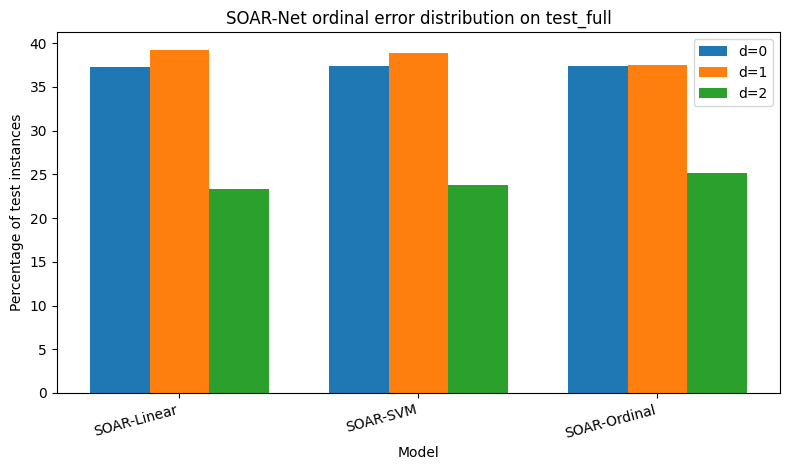

✅ Saved figure: /content/Q1_readability_outputs_FINAL/out/q1_figures/soar_net_ordinal_error_distribution.png


In [16]:

# ============================================================
# 5) SOAR paper-ready comparison table + ordinal error figure
# ============================================================

# Merge SOAR metrics with every existing paper-ready metrics file.
def _standardize_metrics_table(df, source_name=""):
    df = df.copy()

    # Some AraBERT metric files use "title" instead of model/split.
    if "model" not in df.columns and "title" in df.columns:
        title = df["title"].astype(str)
        df["model"] = title.str.extract(r"^(.*?)(?:\s*-\s*test_.*)?$")[0].fillna(title)
        df["split"] = title.str.extract(r"(test_[A-Za-z0-9_]+)")[0].fillna("test_full")

    if "split" not in df.columns:
        # Infer split from source filename when possible
        s = str(source_name).lower()
        if "same0" in s or "same_all=0" in s:
            df["split"] = "test_same0"
        elif "same1" in s or "same_all=1" in s:
            df["split"] = "test_same1"
        else:
            df["split"] = "test_full"

    if "model" not in df.columns:
        df["model"] = Path(str(source_name)).stem

    # Normalize column names used in earlier blocks
    rename_map = {
        "avg_ordinal_distance": "avg_orddist",
        "near_miss_accuracy": "nm1",
        "accuracy": "acc",
        "Macro-F1": "macro_f1",
        "macro-f1": "macro_f1",
    }
    df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})

    # Normalize internal experiment labels to publication names.
    model_aliases = {
        "SVM_char_TFIDF_recheck": "Character-level TF-IDF SVM",
        "SVM_TFIDF": "Character-level TF-IDF SVM",
        "OrdinalLogReg_cumulative": "Ordinal Logistic Regression",
        "AraBERT Two-Stage": "AraBERT (Two-Stage)",
    }
    if "model" in df.columns:
        df["model"] = (
            df["model"]
            .astype(str)
            .replace(model_aliases)
        )

    # Ensure important numeric columns exist when possible
    for c in ["n","acc","macro_f1","avg_orddist","nm1","p_d0","p_d1","p_d2"]:
        if c not in df.columns:
            df[c] = np.nan
    return df

metric_files = []
explicit_candidates = [
    OUT_DIR / "baseline_metrics_dummy.csv",
    OUT_DIR / "metrics_logistic_regression.csv",
    OUT_DIR / "metrics_svm_best.csv",
    OUT_DIR / "ablation_svm_tfidf.csv",
    OUT_DIR / "metrics_svm_recheck_for_q1.csv",
    OUT_DIR / "metrics_ordinal_logreg_cumulative.csv",
    OUT_DIR / "metrics_arabert_two_stage.csv",
    OUT_DIR / "soar_net_metrics.csv",
]
metric_files.extend([p for p in explicit_candidates if p.exists()])

# Add any future metrics_*.csv files; legacy weighted rows are filtered below.
for p in OUT_DIR.glob("metrics_*.csv"):
    if p.exists() and p not in metric_files:
        metric_files.append(p)

tables = []
for p in metric_files:
    try:
        tmp = pd.read_csv(p)
        tmp = _standardize_metrics_table(tmp, p)
        tmp["source_file"] = p.name
        tables.append(tmp)
        print("Loaded metrics:", p.name)
    except Exception as e:
        print("Skipped metrics file:", p, "|", e)

if len(tables) == 0:
    comparison = soar_metrics.copy()
    comparison["source_file"] = "soar_net_metrics.csv"
else:
    comparison = pd.concat(tables + [soar_metrics.assign(source_file="soar_net_metrics.csv")], ignore_index=True, sort=False)

# Remove exact duplicates but keep the latest SOAR rows.
comparison = comparison.drop_duplicates(subset=["model", "split", "source_file"], keep="last")

# Final-paper safety: remove every legacy weighted AraBERT row.
comparison = comparison[
    ~comparison["model"].astype(str).str.contains(
        "weighted",
        case=False,
        na=False,
    )
].copy()

comparison = comparison[
    ~comparison["source_file"].astype(str).str.contains(
        "weighted",
        case=False,
        na=False,
    )
].copy()


# Paper-critical subset: keep main test rows and all model families.
cols = [c for c in ["model","split","n","acc","macro_f1","avg_orddist","nm1","p_d0","p_d1","p_d2","source_file"] if c in comparison.columns]
comparison = comparison[cols].copy()

# Sort: full test first, then same0, then same1; best Macro-F1 first within each split.
split_order = {"test_full": 0, "test_same0": 1, "test_same1": 2}
comparison["_split_order"] = comparison["split"].map(split_order).fillna(9)
comparison = comparison.sort_values(["_split_order", "macro_f1"], ascending=[True, False]).drop(columns=["_split_order"])

comparison_path = OUT_DIR / "paper_table_WITH_ALL_MODELS_AND_SOAR.csv"
comparison.to_csv(comparison_path, index=False)
print("✅ Saved complete comparison table:", comparison_path)
display(comparison)

# Also save a compact table for the main paper: test_full only,
# restricted to the seven final publication models.
FINAL_PUBLICATION_MODELS = [
    "Character-level TF-IDF SVM",
    "Logistic Regression",
    "AraBERT (Two-Stage)",
    "Ordinal Logistic Regression",
    "SOAR-Linear",
    "SOAR-SVM",
    "SOAR-Ordinal",
]

main_table = comparison[
    comparison["split"].astype(str).eq("test_full")
].copy()

main_table = main_table[
    main_table["model"].isin(FINAL_PUBLICATION_MODELS)
].copy()
main_table = main_table.drop_duplicates(subset=["model"], keep="last")
main_table = main_table.sort_values("macro_f1", ascending=False)
main_path = OUT_DIR / "paper_main_table_test_full_all_models.csv"
main_table.to_csv(main_path, index=False)
print("✅ Saved main paper table:", main_path)
display(main_table)

# Ordinal error distribution for SOAR variants.
# Robustly get gold labels even if Cell 14 was skipped during testing.
y_test_local = y_test if "y_test" in globals() else test_df["label"].astype(int).values
plot_rows = []
for model_name, pred in [
    ("SOAR-Linear", pred_linear_test),
    ("SOAR-SVM", pred_svm_test),
    ("SOAR-Ordinal", pred_ord_test),
]:
    d = np.abs(y_test_local - np.asarray(pred, dtype=int))
    for dist in [0, 1, 2]:
        plot_rows.append({"model": model_name, "distance": dist, "percent": 100 * float((d == dist).mean())})

err_df = pd.DataFrame(plot_rows)
err_path = OUT_DIR / "soar_ordinal_error_distribution.csv"
err_df.to_csv(err_path, index=False)
print("✅ Saved SOAR ordinal error distribution:", err_path)

plt.figure(figsize=(8, 4.8))
models = err_df["model"].unique().tolist()
x = np.arange(len(models))
width = 0.25
for j, dist in enumerate([0, 1, 2]):
    vals = [err_df[(err_df["model"] == m) & (err_df["distance"] == dist)]["percent"].iloc[0] for m in models]
    plt.bar(x + (j - 1) * width, vals, width, label=f"d={dist}")
plt.xticks(x, models, rotation=15, ha="right")
plt.ylabel("Percentage of test instances")
plt.xlabel("Model")
plt.title("SOAR-Net ordinal error distribution on test_full")
plt.legend()
plt.tight_layout()
fig_path = FIG_DIR / "soar_net_ordinal_error_distribution.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.savefig(FIG_DIR / "soar_net_ordinal_error_distribution.pdf", bbox_inches="tight")
plt.show()
print("✅ Saved figure:", fig_path)


In [17]:
# ============================================================
# FINAL STATISTICAL VALIDATION
#
# - Strict one-to-one prediction alignment
# - Pairwise McNemar tests
# - Holm correction for multiple pairwise comparisons
# - 1,000 bootstrap samples
# - 95% CI for Accuracy, Macro-F1, AOD and NM@1
# ============================================================

from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
)

from statsmodels.stats.contingency_tables import (
    mcnemar,
)

from statsmodels.stats.multitest import (
    multipletests,
)


OUT_DIR = get_out_dir()

LABELS = [3, 4, 5]

N_BOOT = 1000
BOOT_SEED = 42


# ============================================================
# 1) Prediction files
# ============================================================

prediction_files = {

    "Character-level TF-IDF SVM":
        OUT_DIR
        / "test_full_predictions_svm_recheck.csv",

    "Logistic Regression":
        OUT_DIR
        / "test_full_predictions_logistic_regression.csv",

    "AraBERT (Two-Stage)":
        OUT_DIR
        / "test_full_predictions_arabert_two_stage.csv",

    "Ordinal Logistic Regression":
        OUT_DIR
        / "test_full_predictions_ordinal_logreg.csv",

    "SOAR-Linear":
        OUT_DIR
        / "test_full_predictions_soar_linear.csv",

    "SOAR-SVM":
        OUT_DIR
        / "test_full_predictions_soar_svm.csv",

    "SOAR-Ordinal":
        OUT_DIR
        / "test_full_predictions_soar_ordinal.csv",
}


# ============================================================
# 2) Robust prediction loader
# ============================================================

def load_prediction_file(
    model_name,
    path,
):

    if not path.exists():

        print(
            f"⚠️ Missing {model_name}: {path.name}"
        )

        return None

    df = pd.read_csv(path)

    rename_map = {}

    if (
        "y_true" in df.columns
        and "gold" not in df.columns
    ):
        rename_map["y_true"] = "gold"

    if (
        "level" in df.columns
        and "gold" not in df.columns
    ):
        rename_map["level"] = "gold"

    if (
        "y_pred" in df.columns
        and "pred" not in df.columns
    ):
        rename_map["y_pred"] = "pred"

    df = df.rename(
        columns=rename_map
    )

    required = {
        "id",
        "gold",
        "pred",
    }

    missing = required - set(df.columns)

    if missing:

        raise ValueError(
            f"{model_name}: "
            f"missing columns {missing}"
        )

    df = df[
        [
            "id",
            "gold",
            "pred",
        ]
    ].copy()

    df["id"] = df["id"].astype(str)

    df["gold"] = pd.to_numeric(
        df["gold"],
        errors="raise",
    ).astype(int)

    df["pred"] = pd.to_numeric(
        df["pred"],
        errors="raise",
    ).astype(int)

    # CRITICAL CHECK: IDs must be unique
    if not df["id"].is_unique:

        duplicate_rows = int(
            df["id"]
            .duplicated(
                keep=False
            )
            .sum()
        )

        duplicate_ids = (
            df.loc[
                df["id"].duplicated(
                    keep=False
                ),
                "id",
            ]
            .value_counts()
            .head(10)
        )

        raise ValueError(
            f"\n❌ {model_name}: IDs are not unique.\n"
            f"Duplicated rows: {duplicate_rows}\n"
            f"Examples:\n{duplicate_ids}"
        )

    if not set(
        df["gold"].unique()
    ).issubset(set(LABELS)):

        raise ValueError(
            f"{model_name}: unexpected gold labels "
            f"{sorted(df['gold'].unique())}"
        )

    if not set(
        df["pred"].unique()
    ).issubset(set(LABELS)):

        raise ValueError(
            f"{model_name}: unexpected prediction labels "
            f"{sorted(df['pred'].unique())}"
        )

    print(
        f"✅ {model_name}: "
        f"{len(df)} predictions, unique IDs confirmed."
    )

    return df


predictions = {}

for model_name, path in prediction_files.items():

    df = load_prediction_file(
        model_name,
        path,
    )

    if df is not None:
        predictions[model_name] = df


EXPECTED_STAT_MODELS = set(prediction_files.keys())

missing_stat_models = (
    EXPECTED_STAT_MODELS
    - set(predictions.keys())
)

if missing_stat_models:
    raise RuntimeError(
        "Missing prediction files for final statistical validation: "
        + ", ".join(sorted(missing_stat_models))
    )


# ============================================================
# 3) Reference test set and strict alignment
# ============================================================

reference_model = (
    "Character-level TF-IDF SVM"
    if "Character-level TF-IDF SVM"
       in predictions
    else list(predictions.keys())[0]
)

reference = (
    predictions[reference_model]
    .sort_values("id")
    .reset_index(drop=True)
)

EXPECTED_N = len(reference)

print(
    "\nReference model:",
    reference_model
)

print(
    "Expected test size:",
    EXPECTED_N
)


aligned = {}

for model_name, df in predictions.items():

    current = (
        df
        .sort_values("id")
        .reset_index(drop=True)
    )

    if set(current["id"]) != set(reference["id"]):

        missing_from_model = (
            set(reference["id"])
            - set(current["id"])
        )

        extra_in_model = (
            set(current["id"])
            - set(reference["id"])
        )

        raise AssertionError(
            f"\n❌ Test instances differ for {model_name}.\n"
            f"Missing IDs: {len(missing_from_model)}\n"
            f"Extra IDs: {len(extra_in_model)}"
        )

    merged = (
        reference[
            [
                "id",
                "gold",
            ]
        ]
        .rename(
            columns={
                "gold":
                "gold_reference"
            }
        )
        .merge(
            current,
            on="id",
            how="inner",
            validate="one_to_one",
        )
    )

    if len(merged) != EXPECTED_N:

        raise AssertionError(
            f"{model_name}: "
            f"expected {EXPECTED_N} aligned rows, "
            f"got {len(merged)}"
        )

    if not np.array_equal(
        merged["gold_reference"].values,
        merged["gold"].values,
    ):

        raise AssertionError(
            f"{model_name}: gold labels "
            f"do not match reference."
        )

    aligned[model_name] = pd.DataFrame({

        "id":
            merged["id"].values,

        "gold":
            merged[
                "gold_reference"
            ].astype(int).values,

        "pred":
            merged["pred"]
            .astype(int)
            .values,
    })


print(
    "\n✅ ALL prediction files are aligned one-to-one."
)

print(
    "Aligned test instances:",
    EXPECTED_N
)


# ============================================================
# 4) Exact metrics sanity table
# ============================================================

def calculate_metrics(
    y_true,
    y_pred,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int,
    )

    dist = np.abs(
        y_true
        - y_pred
    )

    return {

        "accuracy":
            float(
                accuracy_score(
                    y_true,
                    y_pred,
                )
            ),

        "macro_f1":
            float(
                f1_score(
                    y_true,
                    y_pred,
                    labels=LABELS,
                    average="macro",
                    zero_division=0,
                )
            ),

        "AOD":
            float(
                dist.mean()
            ),

        "NM@1":
            float(
                (dist <= 1).mean()
            ),

        "QWK":
            float(
                cohen_kappa_score(
                    y_true,
                    y_pred,
                    labels=LABELS,
                    weights="quadratic",
                )
            ),

        "p_d0":
            float(
                (dist == 0).mean()
            ),

        "p_d1":
            float(
                (dist == 1).mean()
            ),

        "p_d2":
            float(
                (dist == 2).mean()
            ),
    }


metric_rows = []

for model_name, df in aligned.items():

    metrics = calculate_metrics(
        df["gold"],
        df["pred"],
    )

    metric_rows.append({
        "model": model_name,
        "n": len(df),
        **metrics,
    })


metrics_df = pd.DataFrame(
    metric_rows
)

metrics_df = metrics_df.sort_values(
    "macro_f1",
    ascending=False,
)

metrics_path = (
    OUT_DIR
    / "FINAL_metrics_recomputed_all_models.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False,
)

print(
    "\n===== FINAL RECOMPUTED METRICS ====="
)

display(metrics_df)

print(
    "Saved:",
    metrics_path
)


# ============================================================
# 5) Pairwise McNemar tests
# ============================================================

mcnemar_rows = []

for model_a, model_b in combinations(
    aligned.keys(),
    2,
):

    A = aligned[model_a]
    B = aligned[model_b]

    assert np.array_equal(
        A["id"].values,
        B["id"].values,
    )

    assert np.array_equal(
        A["gold"].values,
        B["gold"].values,
    )

    gold = A["gold"].values

    pred_a = A["pred"].values
    pred_b = B["pred"].values

    correct_a = (
        gold == pred_a
    )

    correct_b = (
        gold == pred_b
    )

    both_correct = int(
        np.sum(
            correct_a
            & correct_b
        )
    )

    a_only = int(
        np.sum(
            correct_a
            & ~correct_b
        )
    )

    b_only = int(
        np.sum(
            ~correct_a
            & correct_b
        )
    )

    both_wrong = int(
        np.sum(
            ~correct_a
            & ~correct_b
        )
    )

    contingency = [

        [
            both_correct,
            a_only,
        ],

        [
            b_only,
            both_wrong,
        ],
    ]

    result = mcnemar(
        contingency,
        exact=False,
        correction=True,
    )

    mcnemar_rows.append({

        "model_A":
            model_a,

        "model_B":
            model_b,

        "both_correct":
            both_correct,

        "A_only_correct":
            a_only,

        "B_only_correct":
            b_only,

        "both_wrong":
            both_wrong,

        "discordant_pairs":
            a_only + b_only,

        "mcnemar_statistic":
            float(
                result.statistic
            ),

        "p_value_raw":
            float(
                result.pvalue
            ),
    })


mcnemar_df = pd.DataFrame(
    mcnemar_rows
)


# ============================================================
# 6) Holm correction
# ============================================================

reject, p_holm, _, _ = (
    multipletests(
        mcnemar_df[
            "p_value_raw"
        ].values,
        alpha=0.05,
        method="holm",
    )
)

mcnemar_df[
    "p_value_holm"
] = p_holm

mcnemar_df[
    "significant_raw_0.05"
] = (
    mcnemar_df[
        "p_value_raw"
    ] < 0.05
)

mcnemar_df[
    "significant_holm_0.05"
] = reject


mcnemar_path = (
    OUT_DIR
    / "FINAL_mcnemar_pairwise_all_models.csv"
)

mcnemar_df.to_csv(
    mcnemar_path,
    index=False,
)


print(
    "\n===== PAIRWISE McNEMAR TESTS ====="
)

display(mcnemar_df)

print(
    "Saved:",
    mcnemar_path
)


# ============================================================
# 7) Bootstrap 95% confidence intervals
# ============================================================

def bootstrap_metrics(
    y_true,
    y_pred,
    n_boot=1000,
    seed=42,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int,
    )

    n = len(y_true)

    rng = np.random.default_rng(seed)

    acc_scores = np.empty(n_boot, dtype=float)
    f1_scores = np.empty(n_boot, dtype=float)
    aod_scores = np.empty(n_boot, dtype=float)
    nm1_scores = np.empty(n_boot, dtype=float)
    qwk_scores = np.empty(n_boot, dtype=float)

    for b in range(n_boot):

        idx = rng.integers(
            0,
            n,
            size=n,
        )

        yt = y_true[idx]
        yp = y_pred[idx]

        dist = np.abs(
            yt - yp
        )

        acc_scores[b] = (
            accuracy_score(
                yt,
                yp,
            )
        )

        f1_scores[b] = (
            f1_score(
                yt,
                yp,
                labels=LABELS,
                average="macro",
                zero_division=0,
            )
        )

        aod_scores[b] = (
            dist.mean()
        )

        nm1_scores[b] = (
            (dist <= 1).mean()
        )

        qwk_scores[b] = (
            cohen_kappa_score(
                yt,
                yp,
                labels=LABELS,
                weights="quadratic",
            )
        )

    distributions = {

        "Accuracy":
            acc_scores,

        "Macro-F1":
            f1_scores,

        "AOD":
            aod_scores,

        "NM@1":
            nm1_scores,

        "QWK":
            qwk_scores,
    }

    rows = []

    for metric_name, values in (
        distributions.items()
    ):

        rows.append({

            "metric":
                metric_name,

            "bootstrap_mean":
                float(
                    np.nanmean(values)
                ),

            "bootstrap_std":
                float(
                    np.nanstd(
                        values,
                        ddof=1
                    )
                ),

            "ci_low_95":
                float(
                    np.nanpercentile(
                        values,
                        2.5,
                    )
                ),

            "ci_high_95":
                float(
                    np.nanpercentile(
                        values,
                        97.5,
                    )
                ),
        })

    return rows


bootstrap_rows = []

for i, (
    model_name,
    df,
) in enumerate(
    aligned.items()
):

    rows = bootstrap_metrics(

        df["gold"],
        df["pred"],

        n_boot=N_BOOT,

        seed=(
            BOOT_SEED
            + i
        ),
    )

    exact = calculate_metrics(
        df["gold"],
        df["pred"],
    )

    exact_lookup = {
        "Accuracy":
            exact["accuracy"],

        "Macro-F1":
            exact["macro_f1"],

        "AOD":
            exact["AOD"],

        "NM@1":
            exact["NM@1"],

        "QWK":
            exact["QWK"],
    }

    for row in rows:

        row["model"] = model_name

        row[
            "point_estimate"
        ] = exact_lookup[
            row["metric"]
        ]

        row[
            "n_bootstrap"
        ] = N_BOOT

        bootstrap_rows.append(
            row
        )


bootstrap_df = pd.DataFrame(
    bootstrap_rows
)


bootstrap_df = bootstrap_df[
    [
        "model",
        "metric",
        "point_estimate",
        "bootstrap_mean",
        "bootstrap_std",
        "ci_low_95",
        "ci_high_95",
        "n_bootstrap",
    ]
]


bootstrap_path = (
    OUT_DIR
    / "FINAL_bootstrap_95CI_all_models.csv"
)

bootstrap_df.to_csv(
    bootstrap_path,
    index=False,
)


print(
    "\n===== BOOTSTRAP 95% CONFIDENCE INTERVALS ====="
)

display(
    bootstrap_df
)

print(
    "Saved:",
    bootstrap_path
)


# ============================================================
# 8) Paper-ready Macro-F1 bootstrap table
# ============================================================

paper_bootstrap = (
    bootstrap_df[
        bootstrap_df[
            "metric"
        ].eq(
            "Macro-F1"
        )
    ]
    .copy()
    .sort_values(
        "point_estimate",
        ascending=False,
    )
)


paper_bootstrap_path = (
    OUT_DIR
    / "FINAL_bootstrap_macro_f1_paper_table.csv"
)

paper_bootstrap.to_csv(
    paper_bootstrap_path,
    index=False,
)


print(
    "\n===== PAPER-READY MACRO-F1 BOOTSTRAP TABLE ====="
)

display(
    paper_bootstrap
)


# ============================================================
# 9) Final sanity checks
# ============================================================

assert (
    metrics_df["n"]
    .nunique()
    == 1
), (
    "Models were evaluated "
    "on different test sizes."
)

assert (
    metrics_df["n"].iloc[0]
    == EXPECTED_N
)

print(
    "\n=============================================="
)

print(
    "✅ FINAL statistical validation completed."
)

print(
    "✅ All IDs unique."
)

print(
    "✅ All model predictions aligned one-to-one."
)

print(
    "✅ Gold labels identical across models."
)

print(
    f"✅ Test size = {EXPECTED_N}"
)

print(
    f"✅ Bootstrap samples per model = {N_BOOT}"
)

print(
    "=============================================="
)


✅ Character-level TF-IDF SVM: 9831 predictions, unique IDs confirmed.
✅ Logistic Regression: 9831 predictions, unique IDs confirmed.
✅ AraBERT (Two-Stage): 9831 predictions, unique IDs confirmed.
✅ Ordinal Logistic Regression: 9831 predictions, unique IDs confirmed.
✅ SOAR-Linear: 9831 predictions, unique IDs confirmed.
✅ SOAR-SVM: 9831 predictions, unique IDs confirmed.
✅ SOAR-Ordinal: 9831 predictions, unique IDs confirmed.

Reference model: Character-level TF-IDF SVM
Expected test size: 9831

✅ ALL prediction files are aligned one-to-one.
Aligned test instances: 9831

===== FINAL RECOMPUTED METRICS =====


,model,n,accuracy,macro_f1,AOD,NM@1,QWK,p_d0,p_d1,p_d2
0,Character-level TF-IDF SVM,9831,0.423558,0.414270,0.778049,0.798393,0.185681,0.423558,0.374835,0.201607
1,Logistic Regression,9831,0.420303,0.413615,0.769606,0.810091,0.187985,0.420303,0.389787,0.189909
2,AraBERT (Two-Stage),9831,0.410742,0.390402,0.794731,0.794528,0.182157,0.410742,0.383786,0.205472
4,SOAR-Linear,9831,0.373309,0.361493,0.860543,0.766148,0.098702,0.373309,0.392839,0.233852
5,SOAR-SVM,9831,0.374021,0.358817,0.863493,0.762486,0.102571,0.374021,0.388465,0.237514
6,SOAR-Ordinal,9831,0.374123,0.348396,0.876920,0.748957,0.105089,0.374123,0.374835,0.251043
3,Ordinal Logistic Regression,9831,0.417964,0.336487,0.831146,0.750890,0.201210,0.417964,0.332926,0.249110


Saved: /content/Q1_readability_outputs_FINAL/out/FINAL_metrics_recomputed_all_models.csv

===== PAIRWISE McNEMAR TESTS =====


,model_A,model_B,both_correct,A_only_correct,B_only_correct,both_wrong,discordant_pairs,mcnemar_statistic,p_value_raw,p_value_holm,significant_raw_0.05,significant_holm_0.05
0,Character-level TF-IDF SVM,Logistic Regression,3242,922,890,4777,1812,0.530353,4.664584e-01,1.000000e+00,False,False
1,Character-level TF-IDF SVM,AraBERT (Two-Stage),2205,1959,1833,3834,3792,4.120517,4.236613e-02,3.812952e-01,True,False
2,Character-level TF-IDF SVM,Ordinal Logistic Regression,3148,1016,961,4706,1977,1.474962,2.245644e-01,1.000000e+00,False,False
3,Character-level TF-IDF SVM,SOAR-Linear,1848,2316,1822,3845,4138,58.735863,1.803246e-14,3.786816e-13,True,True
4,Character-level TF-IDF SVM,SOAR-SVM,1857,2307,1820,3847,4127,57.231888,3.873399e-14,7.359458e-13,True,True
5,Character-level TF-IDF SVM,SOAR-Ordinal,1914,2250,1764,3903,4014,58.601146,1.931040e-14,3.862079e-13,True,True
6,Logistic Regression,AraBERT (Two-Stage),2101,2031,1937,3762,3968,2.179688,1.398429e-01,1.000000e+00,False,False
7,Logistic Regression,Ordinal Logistic Regression,3010,1122,1099,4600,2221,0.217920,6.406295e-01,1.000000e+00,False,False
8,Logistic Regression,SOAR-Linear,1880,2252,1790,3909,4042,52.578179,4.134576e-13,7.028779e-12,True,True
9,Logistic Regression,SOAR-SVM,1912,2220,1765,3934,3985,51.722961,6.391094e-13,1.022575e-11,True,True


Saved: /content/Q1_readability_outputs_FINAL/out/FINAL_mcnemar_pairwise_all_models.csv

===== BOOTSTRAP 95% CONFIDENCE INTERVALS =====


,model,metric,point_estimate,bootstrap_mean,bootstrap_std,ci_low_95,ci_high_95,n_bootstrap
0,Character-level TF-IDF SVM,Accuracy,0.423558,0.423745,0.004951,0.413997,0.433323,1000
1,Character-level TF-IDF SVM,Macro-F1,0.414270,0.414421,0.004907,0.404724,0.423744,1000
2,Character-level TF-IDF SVM,AOD,0.778049,0.777655,0.007501,0.763503,0.792086,1000
3,Character-level TF-IDF SVM,NM@1,0.798393,0.798600,0.003939,0.790965,0.806429,1000
4,Character-level TF-IDF SVM,QWK,0.185681,0.186088,0.009776,0.167936,0.204771,1000
5,Logistic Regression,Accuracy,0.420303,0.420381,0.004918,0.410434,0.429460,1000
6,Logistic Regression,Macro-F1,0.413615,0.413681,0.004785,0.403726,0.422476,1000
7,Logistic Regression,AOD,0.769606,0.769483,0.007628,0.755058,0.785177,1000
8,Logistic Regression,NM@1,0.810091,0.810136,0.004038,0.802357,0.818228,1000
9,Logistic Regression,QWK,0.187985,0.188083,0.010319,0.166552,0.207248,1000


Saved: /content/Q1_readability_outputs_FINAL/out/FINAL_bootstrap_95CI_all_models.csv

===== PAPER-READY MACRO-F1 BOOTSTRAP TABLE =====


,model,metric,point_estimate,bootstrap_mean,bootstrap_std,ci_low_95,ci_high_95,n_bootstrap
1,Character-level TF-IDF SVM,Macro-F1,0.414270,0.414421,0.004907,0.404724,0.423744,1000
6,Logistic Regression,Macro-F1,0.413615,0.413681,0.004785,0.403726,0.422476,1000
11,AraBERT (Two-Stage),Macro-F1,0.390402,0.390304,0.004870,0.380776,0.399774,1000
21,SOAR-Linear,Macro-F1,0.361493,0.361009,0.004821,0.351583,0.370678,1000
26,SOAR-SVM,Macro-F1,0.358817,0.358731,0.004596,0.349976,0.368213,1000
31,SOAR-Ordinal,Macro-F1,0.348396,0.348424,0.004551,0.339449,0.357350,1000
16,Ordinal Logistic Regression,Macro-F1,0.336487,0.336295,0.003608,0.329209,0.343100,1000



✅ FINAL statistical validation completed.
✅ All IDs unique.
✅ All model predictions aligned one-to-one.
✅ Gold labels identical across models.
✅ Test size = 9831
✅ Bootstrap samples per model = 1000


In [18]:
# ============================================================
# FINAL DISCUSSION / RQ4 ANALYSIS PACK
#
# Produces all additional evidence likely to be needed later:
# 1) top character n-grams for linguistic interpretation
# 2) per-class precision/recall/F1 and confusion matrices
# 3) all-model ordinal-error distribution figure
# 4) all-model ambiguity robustness table + performance gaps
# 5) group-level similarity/error Spearman correlations
# 6) qualitative example candidates
# 7) machine-readable experiment-configuration summary
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix,
    cohen_kappa_score,
)
from scipy.stats import spearmanr

OUT_DIR = get_out_dir()
DISC_DIR = OUT_DIR / "discussion_outputs"
DISC_DIR.mkdir(parents=True, exist_ok=True)

LABELS = [3, 4, 5]


# ============================================================
# 1) Top character-level SVM features
# ============================================================

if "vec" not in globals() or "clf" not in globals():
    raise RuntimeError(
        "Final SVM vectorizer/classifier not found. Run the SVM cell first."
    )

feature_names = np.asarray(vec.get_feature_names_out())
coef = np.asarray(clf.coef_)

if coef.shape[0] != len(LABELS):
    raise AssertionError(
        f"Unexpected SVM coefficient shape: {coef.shape}"
    )

top_feature_rows = []
TOP_K = 20

for class_idx, level in enumerate(LABELS):
    order = np.argsort(coef[class_idx])[::-1][:TOP_K]

    for rank, feat_idx in enumerate(order, start=1):
        top_feature_rows.append({
            "level": f"L{level}",
            "rank": rank,
            "feature": feature_names[feat_idx],
            "weight": float(coef[class_idx, feat_idx]),
        })

top_features_df = pd.DataFrame(top_feature_rows)

top_features_df.to_csv(
    DISC_DIR / "FINAL_top_character_ngrams_by_level.csv",
    index=False,
)

print("\n===== TOP CHARACTER N-GRAMS BY LEVEL =====")
display(top_features_df.groupby("level").head(10))


# ============================================================
# 2) Load main-model full-test predictions
# ============================================================

main_prediction_files = {
    "Character-level TF-IDF SVM":
        OUT_DIR / "test_full_predictions_svm_recheck.csv",

    "Logistic Regression":
        OUT_DIR / "test_full_predictions_logistic_regression.csv",

    "AraBERT (Two-Stage)":
        OUT_DIR / "test_full_predictions_arabert_two_stage.csv",

    "Ordinal Logistic Regression":
        OUT_DIR / "test_full_predictions_ordinal_logreg.csv",

    "SOAR-Linear":
        OUT_DIR / "test_full_predictions_soar_linear.csv",

    "SOAR-SVM":
        OUT_DIR / "test_full_predictions_soar_svm.csv",

    "SOAR-Ordinal":
        OUT_DIR / "test_full_predictions_soar_ordinal.csv",
}

main_preds = {}

for model_name, path in main_prediction_files.items():
    if not path.exists():
        print(f"⚠️ Missing for discussion: {model_name} -> {path.name}")
        continue

    dfp = pd.read_csv(path)

    if "y_true" in dfp.columns and "gold" not in dfp.columns:
        dfp = dfp.rename(columns={"y_true": "gold"})
    if "level" in dfp.columns and "gold" not in dfp.columns:
        dfp = dfp.rename(columns={"level": "gold"})
    if "y_pred" in dfp.columns and "pred" not in dfp.columns:
        dfp = dfp.rename(columns={"y_pred": "pred"})

    required = {"id", "gold", "pred"}
    missing = required - set(dfp.columns)

    if missing:
        raise ValueError(
            f"{model_name}: missing prediction columns {missing}"
        )

    dfp = dfp.copy()
    dfp["id"] = dfp["id"].astype(str)
    dfp["gold"] = pd.to_numeric(dfp["gold"], errors="raise").astype(int)
    dfp["pred"] = pd.to_numeric(dfp["pred"], errors="raise").astype(int)

    if not dfp["id"].is_unique:
        raise ValueError(f"{model_name}: duplicate IDs in full-test predictions.")

    main_preds[model_name] = dfp


# ============================================================
# 3) Per-class metrics + confusion matrices
# ============================================================

per_class_rows = []

for model_name, dfp in main_preds.items():
    p, r, f1, support = precision_recall_fscore_support(
        dfp["gold"],
        dfp["pred"],
        labels=LABELS,
        zero_division=0,
    )

    for i, level in enumerate(LABELS):
        per_class_rows.append({
            "model": model_name,
            "level": f"L{level}",
            "precision": float(p[i]),
            "recall": float(r[i]),
            "f1": float(f1[i]),
            "support": int(support[i]),
        })

    cm = confusion_matrix(
        dfp["gold"],
        dfp["pred"],
        labels=LABELS,
    )

    pd.DataFrame(
        cm,
        index=[f"true_L{x}" for x in LABELS],
        columns=[f"pred_L{x}" for x in LABELS],
    ).to_csv(
        DISC_DIR / (
            "FINAL_cm_"
            + re.sub(r"[^A-Za-z0-9]+", "_", model_name).strip("_").lower()
            + ".csv"
        )
    )

per_class_df = pd.DataFrame(per_class_rows)

per_class_df.to_csv(
    DISC_DIR / "FINAL_per_class_metrics_all_models.csv",
    index=False,
)

print("\n===== PER-CLASS METRICS =====")
display(per_class_df)


# ============================================================
# 4) All-model ordinal error distribution
# ============================================================

ordinal_rows = []

for model_name, dfp in main_preds.items():
    d = np.abs(
        dfp["gold"].to_numpy()
        - dfp["pred"].to_numpy()
    )

    ordinal_rows.append({
        "model": model_name,
        "p_d0": 100.0 * float((d == 0).mean()),
        "p_d1": 100.0 * float((d == 1).mean()),
        "p_d2": 100.0 * float((d == 2).mean()),
    })

ordinal_df = pd.DataFrame(ordinal_rows)

ordinal_df.to_csv(
    DISC_DIR / "FINAL_ordinal_error_distribution_all_models.csv",
    index=False,
)

# Exclude Logistic Regression from the main visual only if needed later;
# the CSV keeps every model.
plot_models = [
    m for m in [
        "Character-level TF-IDF SVM",
        "Logistic Regression",
        "AraBERT (Two-Stage)",
        "Ordinal Logistic Regression",
        "SOAR-Linear",
        "SOAR-SVM",
        "SOAR-Ordinal",
    ]
    if m in set(ordinal_df["model"])
]

plot_df = (
    ordinal_df
    .set_index("model")
    .loc[plot_models]
    .reset_index()
)

short_names = {
    "Character-level TF-IDF SVM": "Char-SVM",
    "Logistic Regression": "LogReg",
    "AraBERT (Two-Stage)": "AraBERT",
    "Ordinal Logistic Regression": "Ord-LogReg",
    "SOAR-Linear": "SOAR-L",
    "SOAR-SVM": "SOAR-SVM",
    "SOAR-Ordinal": "SOAR-O",
}

x = np.arange(len(plot_df))
width = 0.24

fig, ax = plt.subplots(figsize=(11.5, 5.8))

ax.bar(
    x - width,
    plot_df["p_d0"],
    width,
    label=r"Correct ($d=0$)",
)

ax.bar(
    x,
    plot_df["p_d1"],
    width,
    label=r"Adjacent ($d=1$)",
)

ax.bar(
    x + width,
    plot_df["p_d2"],
    width,
    label=r"Two-level ($d=2$)",
)

ax.set_title("Ordinal prediction error distribution")
ax.set_ylabel("Percentage of test instances (%)")

ax.set_xticks(x)
ax.set_xticklabels(
    [short_names.get(m, m) for m in plot_df["model"]]
)

ax.set_ylim(
    0,
    max(
        55,
        float(
            plot_df[["p_d0", "p_d1", "p_d2"]]
            .to_numpy()
            .max()
            + 5
        ),
    ),
)

ax.grid(
    axis="y",
    alpha=0.15,
    linestyle="--",
)

ax.set_axisbelow(True)
ax.legend(loc="upper right", frameon=True)

plt.tight_layout()

plt.savefig(
    DISC_DIR / "FINAL_ordinal_error_distribution_all_models.png",
    dpi=600,
    bbox_inches="tight",
)

plt.savefig(
    DISC_DIR / "FINAL_ordinal_error_distribution_all_models.pdf",
    bbox_inches="tight",
)

plt.close()

print("\n===== ORDINAL ERROR DISTRIBUTION =====")
display(ordinal_df)


# ============================================================
# 5) Ambiguity robustness across model families
# ============================================================

split_prediction_files = {
    "Character-level TF-IDF SVM": {
        "same0": OUT_DIR / "test_same0_predictions_svm_recheck.csv",
        "same1": OUT_DIR / "test_same1_predictions_svm_recheck.csv",
    },

    "Logistic Regression": {
        "same0": OUT_DIR / "test_same0_predictions_logistic_regression.csv",
        "same1": OUT_DIR / "test_same1_predictions_logistic_regression.csv",
    },

    "AraBERT (Two-Stage)": {
        "same0": OUT_DIR / "test_same0_predictions_arabert_two_stage.csv",
        "same1": OUT_DIR / "test_same1_predictions_arabert_two_stage.csv",
    },

    "Ordinal Logistic Regression": {
        "same0": OUT_DIR / "test_same0_predictions_ordinal_logreg.csv",
        "same1": OUT_DIR / "test_same1_predictions_ordinal_logreg.csv",
    },

    "SOAR-Linear": {
        "same0": OUT_DIR / "test_same0_predictions_soar_linear.csv",
        "same1": OUT_DIR / "test_same1_predictions_soar_linear.csv",
    },

    "SOAR-SVM": {
        "same0": OUT_DIR / "test_same0_predictions_soar_svm.csv",
        "same1": OUT_DIR / "test_same1_predictions_soar_svm.csv",
    },

    "SOAR-Ordinal": {
        "same0": OUT_DIR / "test_same0_predictions_soar_ordinal.csv",
        "same1": OUT_DIR / "test_same1_predictions_soar_ordinal.csv",
    },
}


def _simple_metrics_from_pred_df(dfp):
    y = dfp["gold"].astype(int).to_numpy()
    p = dfp["pred"].astype(int).to_numpy()
    d = np.abs(y - p)

    return {
        "accuracy": float((y == p).mean()),
        "macro_f1": float(
            __import__("sklearn.metrics", fromlist=["f1_score"])
            .f1_score(
                y,
                p,
                labels=LABELS,
                average="macro",
                zero_division=0,
            )
        ),
        "AOD": float(d.mean()),
        "NM@1": float((d <= 1).mean()),
        "p_d2": float((d == 2).mean()),
        "n": int(len(y)),
    }


robust_rows = []
gap_rows = []

for model_name, files in split_prediction_files.items():
    model_metrics = {}

    for split_key, path in files.items():
        if not path.exists():
            print(f"⚠️ Missing robustness file: {path.name}")
            continue

        dfp = pd.read_csv(path)

        if "y_true" in dfp.columns and "gold" not in dfp.columns:
            dfp = dfp.rename(columns={"y_true": "gold"})
        if "level" in dfp.columns and "gold" not in dfp.columns:
            dfp = dfp.rename(columns={"level": "gold"})
        if "y_pred" in dfp.columns and "pred" not in dfp.columns:
            dfp = dfp.rename(columns={"y_pred": "pred"})

        m = _simple_metrics_from_pred_df(dfp)
        model_metrics[split_key] = m

        robust_rows.append({
            "model": model_name,
            "subset": split_key,
            **m,
        })

    if "same0" in model_metrics and "same1" in model_metrics:
        a = model_metrics["same0"]
        b = model_metrics["same1"]

        gap_rows.append({
            "model": model_name,
            "accuracy_drop_same0_to_same1": a["accuracy"] - b["accuracy"],
            "macro_f1_drop_same0_to_same1": a["macro_f1"] - b["macro_f1"],
            "AOD_increase_same0_to_same1": b["AOD"] - a["AOD"],
            "NM1_drop_same0_to_same1": a["NM@1"] - b["NM@1"],
            "d2_increase_same0_to_same1": b["p_d2"] - a["p_d2"],
        })

robust_df = pd.DataFrame(robust_rows)
gap_df = pd.DataFrame(gap_rows)

robust_df.to_csv(
    DISC_DIR / "FINAL_model_performance_same0_same1_all_models.csv",
    index=False,
)

gap_df.to_csv(
    DISC_DIR / "FINAL_ambiguity_performance_gap_all_models.csv",
    index=False,
)

print("\n===== AMBIGUITY ROBUSTNESS: SAME0 vs SAME1 =====")
display(robust_df)

print("\n===== AMBIGUITY PERFORMANCE GAPS =====")
display(gap_df)




# ============================================================
# 5b) Bootstrap uncertainty for ambiguity-performance gaps
#     same0 vs same1 are disjoint subsets, so each iteration
#     independently resamples each subset and computes the gap.
# ============================================================

from sklearn.metrics import f1_score, cohen_kappa_score

def _metric_bundle(y, p):
    y = np.asarray(y, dtype=int)
    p = np.asarray(p, dtype=int)
    d = np.abs(y - p)

    return {
        "Accuracy": float((y == p).mean()),
        "Macro-F1": float(
            f1_score(
                y, p,
                labels=LABELS,
                average="macro",
                zero_division=0,
            )
        ),
        "AOD": float(d.mean()),
        "NM@1": float((d <= 1).mean()),
        "QWK": float(
            cohen_kappa_score(
                y, p,
                labels=LABELS,
                weights="quadratic",
            )
        ),
    }


def bootstrap_ambiguity_gap(df0, df1, n_boot=1000, seed=42):
    """
    Gap direction:
      Accuracy/Macro-F1/NM@1/QWK: same0 - same1  (positive = degradation)
      AOD:                      same1 - same0  (positive = degradation)
    """
    rng = np.random.default_rng(seed)

    y0 = df0["gold"].astype(int).to_numpy()
    p0 = df0["pred"].astype(int).to_numpy()

    y1 = df1["gold"].astype(int).to_numpy()
    p1 = df1["pred"].astype(int).to_numpy()

    gap_store = {
        "Accuracy": [],
        "Macro-F1": [],
        "AOD": [],
        "NM@1": [],
        "QWK": [],
    }

    for _ in range(n_boot):
        i0 = rng.integers(0, len(y0), size=len(y0))
        i1 = rng.integers(0, len(y1), size=len(y1))

        m0 = _metric_bundle(y0[i0], p0[i0])
        m1 = _metric_bundle(y1[i1], p1[i1])

        gap_store["Accuracy"].append(m0["Accuracy"] - m1["Accuracy"])
        gap_store["Macro-F1"].append(m0["Macro-F1"] - m1["Macro-F1"])
        gap_store["AOD"].append(m1["AOD"] - m0["AOD"])
        gap_store["NM@1"].append(m0["NM@1"] - m1["NM@1"])
        gap_store["QWK"].append(m0["QWK"] - m1["QWK"])

    rows = []

    point0 = _metric_bundle(y0, p0)
    point1 = _metric_bundle(y1, p1)

    point_gap = {
        "Accuracy": point0["Accuracy"] - point1["Accuracy"],
        "Macro-F1": point0["Macro-F1"] - point1["Macro-F1"],
        "AOD": point1["AOD"] - point0["AOD"],
        "NM@1": point0["NM@1"] - point1["NM@1"],
        "QWK": point0["QWK"] - point1["QWK"],
    }

    for metric, values in gap_store.items():
        arr = np.asarray(values, dtype=float)

        rows.append({
            "metric": metric,
            "point_gap": float(point_gap[metric]),
            "bootstrap_mean_gap": float(arr.mean()),
            "ci_low_95": float(np.percentile(arr, 2.5)),
            "ci_high_95": float(np.percentile(arr, 97.5)),
            "n_bootstrap": int(n_boot),
            "gap_direction": (
                "same0-minus-same1"
                if metric != "AOD"
                else "same1-minus-same0"
            ),
        })

    return rows


ambiguity_ci_rows = []

for model_index, (model_name, files) in enumerate(
    split_prediction_files.items()
):
    p0 = files["same0"]
    p1 = files["same1"]

    if not (p0.exists() and p1.exists()):
        continue

    d0 = pd.read_csv(p0)
    d1 = pd.read_csv(p1)

    for df_ in [d0, d1]:
        if "y_true" in df_.columns and "gold" not in df_.columns:
            df_.rename(columns={"y_true": "gold"}, inplace=True)
        if "level" in df_.columns and "gold" not in df_.columns:
            df_.rename(columns={"level": "gold"}, inplace=True)
        if "y_pred" in df_.columns and "pred" not in df_.columns:
            df_.rename(columns={"y_pred": "pred"}, inplace=True)

    rows = bootstrap_ambiguity_gap(
        d0,
        d1,
        n_boot=1000,
        seed=4200 + model_index,
    )

    for row in rows:
        row["model"] = model_name
        ambiguity_ci_rows.append(row)

ambiguity_gap_ci_df = pd.DataFrame(ambiguity_ci_rows)

ambiguity_gap_ci_df.to_csv(
    DISC_DIR / "FINAL_ambiguity_gap_bootstrap_95CI.csv",
    index=False,
)

print("\n===== BOOTSTRAP 95% CI FOR AMBIGUITY PERFORMANCE GAPS =====")
display(ambiguity_gap_ci_df)


# ============================================================
# 6) Group-level similarity vs error/AOD correlation
# ============================================================

similarity_source = OUT_DIR / "test_overlap_table_q1.csv"

corr_rows = []

if similarity_source.exists():
    sim_df = pd.read_csv(similarity_source)

    for model_name, dfp in main_preds.items():

        # only models where group-level similarity exists
        if "group_id" not in dfp.columns:
            # Recover group_id from test long metadata
            meta = pd.read_csv(
                OUT_DIR / "test.long.tsv",
                sep="\t",
            )[["id", "group_id"]]

            dfp2 = dfp.merge(
                meta,
                on="id",
                how="left",
                validate="one_to_one",
            )
        else:
            dfp2 = dfp.copy()

        merged = dfp2.merge(
            sim_df[["group_id", "mean_pair_sim"]],
            on="group_id",
            how="left",
            validate="many_to_one",
        )

        merged["error"] = (
            merged["gold"] != merged["pred"]
        ).astype(float)

        merged["orddist"] = np.abs(
            merged["gold"] - merged["pred"]
        ).astype(float)

        # Aggregate predictions to one observation per source group
        group_eval = (
            merged
            .dropna(subset=["mean_pair_sim"])
            .groupby("group_id", as_index=False)
            .agg(
                mean_pair_sim=("mean_pair_sim", "first"),
                error_rate=("error", "mean"),
                mean_orddist=("orddist", "mean"),
            )
        )

        if len(group_eval) >= 3:
            rho_err, p_err = spearmanr(
                group_eval["mean_pair_sim"],
                group_eval["error_rate"],
            )

            rho_aod, p_aod = spearmanr(
                group_eval["mean_pair_sim"],
                group_eval["mean_orddist"],
            )

            corr_rows.extend([
                {
                    "model": model_name,
                    "outcome": "classification_error_rate",
                    "spearman_rho": float(rho_err),
                    "p_value": float(p_err),
                    "n_groups": int(len(group_eval)),
                },
                {
                    "model": model_name,
                    "outcome": "average_ordinal_distance",
                    "spearman_rho": float(rho_aod),
                    "p_value": float(p_aod),
                    "n_groups": int(len(group_eval)),
                },
            ])

corr_df = pd.DataFrame(corr_rows)

corr_df.to_csv(
    DISC_DIR / "FINAL_similarity_error_spearman_correlations.csv",
    index=False,
)

print("\n===== GROUP-LEVEL SIMILARITY CORRELATIONS =====")
display(corr_df)


# ============================================================
# 7) Qualitative example candidates
# ============================================================

test_meta = pd.read_csv(
    OUT_DIR / "test.long.tsv",
    sep="\t",
)

meta_cols = [
    c for c in [
        "id",
        "group_id",
        "level",
        "text",
        "text_norm",
        "ambiguous_exact",
        "same_all",
    ]
    if c in test_meta.columns
]

examples = test_meta[meta_cols].copy()

if "Character-level TF-IDF SVM" in main_preds:
    svm_df = main_preds["Character-level TF-IDF SVM"][
        ["id", "pred"]
    ].rename(columns={"pred": "pred_svm"})

    examples = examples.merge(
        svm_df,
        on="id",
        how="left",
        validate="one_to_one",
    )

if "AraBERT (Two-Stage)" in main_preds:
    ara_df = main_preds["AraBERT (Two-Stage)"][
        ["id", "pred"]
    ].rename(columns={"pred": "pred_arabert"})

    examples = examples.merge(
        ara_df,
        on="id",
        how="left",
        validate="one_to_one",
    )

if "pred_svm" in examples.columns:
    examples["svm_correct"] = (
        examples["level"] == examples["pred_svm"]
    ).astype(int)

    examples["svm_orddist"] = np.abs(
        examples["level"] - examples["pred_svm"]
    )

if "pred_arabert" in examples.columns:
    examples["arabert_correct"] = (
        examples["level"] == examples["pred_arabert"]
    ).astype(int)

    examples["arabert_orddist"] = np.abs(
        examples["level"] - examples["pred_arabert"]
    )

candidate_parts = []

if {"svm_correct", "arabert_correct"}.issubset(examples.columns):
    # Non-overlapping cases where SVM succeeds and AraBERT fails
    c = examples[
        (examples["same_all"].astype(int) == 0)
        & (examples["svm_correct"] == 1)
        & (examples["arabert_correct"] == 0)
    ].head(30).copy()
    c["example_type"] = "nonoverlap_svm_correct_arabert_wrong"
    candidate_parts.append(c)

if "same_all" in examples.columns:
    # Ambiguous cases
    c = examples[
        examples["same_all"].astype(int) == 1
    ].head(30).copy()
    c["example_type"] = "ambiguous_exact_surface_form"
    candidate_parts.append(c)

if "svm_orddist" in examples.columns:
    # SVM near misses
    c = examples[
        examples["svm_orddist"] == 1
    ].head(30).copy()
    c["example_type"] = "svm_adjacent_near_miss"
    candidate_parts.append(c)

qual_df = (
    pd.concat(candidate_parts, ignore_index=True)
    if candidate_parts
    else pd.DataFrame()
)

qual_df.to_csv(
    DISC_DIR / "FINAL_qualitative_example_candidates.csv",
    index=False,
)

print("\n===== QUALITATIVE EXAMPLE CANDIDATES =====")
display(qual_df.head(20))


# ============================================================
# 8) Experiment configuration summary
# ============================================================

config_rows = [
    {
        "component": "Preprocessing",
        "parameter": "Arabic normalization",
        "value": "remove diacritics/tatweel; normalize alif variants; ى->ي; collapse whitespace",
    },
    {
        "component": "Character TF-IDF",
        "parameter": "ngram_range",
        "value": "(3,5)",
    },
    {
        "component": "Character TF-IDF",
        "parameter": "min_df",
        "value": "2",
    },
    {
        "component": "Character TF-IDF",
        "parameter": "max_features",
        "value": "50000",
    },
    {
        "component": "Character TF-IDF",
        "parameter": "sublinear_tf",
        "value": "True",
    },
    {
        "component": "Character TF-IDF",
        "parameter": "norm",
        "value": "l2",
    },
    {
        "component": "SVM",
        "parameter": "C",
        "value": "1.0",
    },
    {
        "component": "AraBERT",
        "parameter": "model",
        "value": "aubmindlab/bert-base-arabertv2",
    },
    {
        "component": "AraBERT",
        "parameter": "max_length",
        "value": "256",
    },
    {
        "component": "AraBERT Stage 1",
        "parameter": "learning_rate / epochs / train_batch",
        "value": "2e-5 / 3 / 16",
    },
    {
        "component": "AraBERT Stage 2",
        "parameter": "learning_rate / epochs / train_batch",
        "value": "1e-5 / 1 / 16",
    },
    {
        "component": "AraBERT",
        "parameter": "weight_decay / warmup_ratio",
        "value": "0.01 / 0.1",
    },
    {
        "component": "Bootstrap",
        "parameter": "replicates",
        "value": "1000",
    },
]

config_df = pd.DataFrame(config_rows)

config_df.to_csv(
    DISC_DIR / "FINAL_experiment_configuration_summary.csv",
    index=False,
)

print("\n✅ Discussion/RQ4 analysis pack completed.")
print("Saved to:", DISC_DIR)

# ============================================================
# 8) FINAL PAPER-READY FIGURES — ROBUST VERSION
# ============================================================

import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

PAPER_FIG_DIR = DISC_DIR / "paper_ready_figures"
PAPER_FIG_DIR.mkdir(parents=True, exist_ok=True)


def _save_png_pdf(fig, stem):
    png = PAPER_FIG_DIR / f"{stem}.png"
    pdf = PAPER_FIG_DIR / f"{stem}.pdf"
    fig.savefig(png, dpi=600, bbox_inches="tight")
    fig.savefig(pdf, bbox_inches="tight")
    plt.close(fig)
    print("✅ Saved:", png)
    print("✅ Saved:", pdf)


def _normalize_model_rows(df):
    df = df.copy()
    if "model" in df.columns:
        df = df[
            ~df["model"].astype(str).str.contains("weighted", case=False, na=False)
        ].copy()
    return df


# ------------------------------------------------------------
# 8.1 Overall Accuracy and Macro-F1
# ------------------------------------------------------------
overall_path = OUT_DIR / "FINAL_metrics_recomputed_all_models.csv"
if not overall_path.exists():
    raise FileNotFoundError(overall_path)

ov = _normalize_model_rows(pd.read_csv(overall_path))
rename = {}
for c in ov.columns:
    lc = str(c).strip().lower()
    if lc in {"accuracy", "acc"}:
        rename[c] = "Accuracy"
    elif lc in {"macro-f1", "macro_f1", "macrof1", "f1_macro"}:
        rename[c] = "Macro-F1"
    elif lc == "model":
        rename[c] = "model"
ov = ov.rename(columns=rename)
need = {"model", "Accuracy", "Macro-F1"}
if not need.issubset(ov.columns):
    raise ValueError(f"Overall metrics missing {sorted(need-set(ov.columns))}; found {ov.columns.tolist()}")
ov["Accuracy"] = pd.to_numeric(ov["Accuracy"], errors="coerce")
ov["Macro-F1"] = pd.to_numeric(ov["Macro-F1"], errors="coerce")
ov = ov.dropna(subset=["Accuracy", "Macro-F1"]).sort_values(["Accuracy", "Macro-F1"], ascending=False)

x = np.arange(len(ov)); width = 0.38
fig, ax = plt.subplots(figsize=(11.5, 6.2))
ax.bar(x-width/2, ov["Accuracy"], width, label="Accuracy")
ax.bar(x+width/2, ov["Macro-F1"], width, label="Macro-F1")
ax.set_ylabel("Score"); ax.set_xlabel("Model")
ax.set_xticks(x); ax.set_xticklabels(ov["model"].astype(str), rotation=25, ha="right")
ax.legend(frameon=True); ax.grid(axis="y", alpha=0.2); fig.tight_layout()
_save_png_pdf(fig, "FINAL_overall_accuracy_macro_f1_all_models")


# ------------------------------------------------------------
# 8.2 same0 vs same1 Accuracy
# Supports either `subset` or `split`, and accuracy/Accuracy/acc.
# ------------------------------------------------------------
robust_path = DISC_DIR / "FINAL_model_performance_same0_same1_all_models.csv"
if not robust_path.exists():
    raise FileNotFoundError(robust_path)

rb = _normalize_model_rows(pd.read_csv(robust_path))
rb_rename = {}
for c in rb.columns:
    lc = str(c).strip().lower()
    if lc in {"accuracy", "acc"}:
        rb_rename[c] = "Accuracy"
    elif lc in {"split", "subset"}:
        rb_rename[c] = "split"
    elif lc == "model":
        rb_rename[c] = "model"
rb = rb.rename(columns=rb_rename)
need = {"model", "split", "Accuracy"}
if not need.issubset(rb.columns):
    raise ValueError(f"same0/same1 table missing {sorted(need-set(rb.columns))}; found {rb.columns.tolist()}")
rb["Accuracy"] = pd.to_numeric(rb["Accuracy"], errors="coerce")
rb["split_clean"] = rb["split"].astype(str).str.replace("test_", "", regex=False)
rb = rb[rb["split_clean"].isin(["same0", "same1"])].copy()
piv = rb.pivot_table(index="model", columns="split_clean", values="Accuracy", aggfunc="first")
if not {"same0", "same1"}.issubset(piv.columns):
    raise ValueError(f"same0/same1 pivot incomplete; columns={piv.columns.tolist()}")
piv = piv.sort_values("same0", ascending=False)

x = np.arange(len(piv)); width = 0.38
fig, ax = plt.subplots(figsize=(11.5, 6.2))
ax.bar(x-width/2, piv["same0"], width, label="Non-overlapping (same0)")
ax.bar(x+width/2, piv["same1"], width, label="Ambiguous (same1)")
ax.set_ylabel("Accuracy"); ax.set_xlabel("Model")
ax.set_xticks(x); ax.set_xticklabels(piv.index.astype(str), rotation=25, ha="right")
ax.legend(frameon=True); ax.grid(axis="y", alpha=0.2); fig.tight_layout()
_save_png_pdf(fig, "FINAL_accuracy_same0_vs_same1_all_models")


# ------------------------------------------------------------
# 8.3 Per-class F1 figure
# ------------------------------------------------------------
pc_path = DISC_DIR / "FINAL_per_class_metrics_all_models.csv"
if not pc_path.exists():
    raise FileNotFoundError(pc_path)
pc = _normalize_model_rows(pd.read_csv(pc_path))
if not {"model", "level", "f1"}.issubset(pc.columns):
    raise ValueError(f"Per-class metrics columns unexpected: {pc.columns.tolist()}")
models = list(dict.fromkeys(pc["model"].astype(str)))
levels = list(dict.fromkeys(pc["level"].astype(str)))
x = np.arange(len(models)); total_width=0.8; width=total_width/max(len(levels),1)
fig, ax = plt.subplots(figsize=(12, 6.5))
for i, level in enumerate(levels):
    vals=[]
    for model in models:
        sub=pc[(pc["model"].astype(str)==model)&(pc["level"].astype(str)==level)]
        vals.append(float(sub["f1"].iloc[0]) if len(sub) else np.nan)
    offset=-total_width/2+width/2+i*width
    ax.bar(x+offset, vals, width, label=str(level))
ax.set_ylabel("F1-score"); ax.set_xlabel("Model")
ax.set_xticks(x); ax.set_xticklabels(models, rotation=25, ha="right")
ax.legend(frameon=True, title="Level"); ax.grid(axis="y", alpha=0.2); fig.tight_layout()
_save_png_pdf(fig, "FINAL_per_class_f1_all_models")


# ------------------------------------------------------------
# 8.4 Bootstrap Macro-F1 95% confidence intervals
# ------------------------------------------------------------
boot_path = OUT_DIR / "FINAL_bootstrap_95CI_all_models.csv"
if not boot_path.exists():
    raise FileNotFoundError(boot_path)
bt = _normalize_model_rows(pd.read_csv(boot_path))
need={"model","metric","point_estimate","ci_low_95","ci_high_95"}
if not need.issubset(bt.columns):
    raise ValueError(f"Bootstrap table columns unexpected: {bt.columns.tolist()}")
bt = bt[bt["metric"].astype(str).str.lower().eq("macro-f1")].copy()
bt = bt.sort_values("point_estimate", ascending=True)
y=np.arange(len(bt)); est=bt["point_estimate"].to_numpy(float); lo=bt["ci_low_95"].to_numpy(float); hi=bt["ci_high_95"].to_numpy(float)
fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.errorbar(est, y, xerr=np.vstack([est-lo,hi-est]), fmt="o", capsize=4)
ax.set_yticks(y); ax.set_yticklabels(bt["model"].astype(str)); ax.set_xlabel("Macro-F1 (95% bootstrap CI)")
ax.set_ylabel("Model"); ax.grid(axis="x", alpha=0.2); fig.tight_layout()
_save_png_pdf(fig, "FINAL_bootstrap_macro_f1_95CI")


# ------------------------------------------------------------
# 8.5 Confusion-matrix figures for every main model
# ------------------------------------------------------------
for model_name, dfp in main_preds.items():
    if "weighted" in model_name.lower():
        continue
    if not {"gold", "pred"}.issubset(dfp.columns):
        raise ValueError(f"Prediction dataframe for {model_name} lacks gold/pred")
    cm = confusion_matrix(dfp["gold"].astype(int), dfp["pred"].astype(int), labels=LABELS)
    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    im=ax.imshow(cm)
    ax.set_xticks(range(len(LABELS))); ax.set_yticks(range(len(LABELS)))
    ax.set_xticklabels([f"L{x}" for x in LABELS]); ax.set_yticklabels([f"L{x}" for x in LABELS])
    ax.set_xlabel("Predicted level"); ax.set_ylabel("True level"); ax.set_title(model_name)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j,i,str(cm[i,j]),ha="center",va="center")
    fig.colorbar(im, ax=ax); fig.tight_layout()
    slug=re.sub(r"[^A-Za-z0-9]+","_",model_name).strip("_").lower()
    _save_png_pdf(fig, f"FINAL_confusion_matrix_{slug}")


# ------------------------------------------------------------
# 8.6 Figure index for manuscript/discussion use
# ------------------------------------------------------------
figure_rows=[]
for p in sorted(OUT_DIR.rglob("*.png")) + sorted(OUT_DIR.rglob("*.pdf")):
    figure_rows.append({
        "relative_path": str(p.relative_to(OUT_DIR)),
        "format": p.suffix.lower().lstrip("."),
        "size_bytes": int(p.stat().st_size),
    })
figure_index_df=pd.DataFrame(figure_rows)
figure_index_df.to_csv(OUT_DIR / "FINAL_FIGURE_INDEX.csv", index=False)

print("\n✅ Final paper-ready figure pack completed:", PAPER_FIG_DIR)



# ============================================================
# 9) FIGURE REPRODUCTION DATA PACK
#
# PURPOSE:
# Save the exact numerical/tabular inputs required to redraw every
# data-driven manuscript/discussion figure later WITHOUT retraining.
#
# Saved under:
#   out/figure_source_data/
#
# Also creates:
#   FINAL_FIGURE_REPRODUCTION_MANIFEST.csv
# ============================================================

FIG_SOURCE_DIR = OUT_DIR / "figure_source_data"
FIG_SOURCE_DIR.mkdir(parents=True, exist_ok=True)

figure_repro_rows = []


def _register_figure_source(
    figure_stem,
    source_csv,
    figure_files,
    x_or_categories,
    y_or_values,
    notes,
):
    figure_repro_rows.append({
        "figure_stem": figure_stem,
        "source_csv": str(Path(source_csv).relative_to(OUT_DIR)),
        "figure_files": " | ".join(figure_files),
        "x_or_categories": x_or_categories,
        "y_or_values": y_or_values,
        "notes": notes,
    })


# ------------------------------------------------------------
# 9.1 Overall Accuracy / Macro-F1 — exact plotted table
# ------------------------------------------------------------
overall_plot_data = ov[
    ["model", "Accuracy", "Macro-F1"]
].copy().reset_index(drop=True)

overall_plot_csv = (
    FIG_SOURCE_DIR
    / "FIGDATA_overall_accuracy_macro_f1_all_models.csv"
)

overall_plot_data.to_csv(
    overall_plot_csv,
    index=False,
)

_register_figure_source(
    "FINAL_overall_accuracy_macro_f1_all_models",
    overall_plot_csv,
    [
        "discussion_outputs/paper_ready_figures/"
        "FINAL_overall_accuracy_macro_f1_all_models.png",
        "discussion_outputs/paper_ready_figures/"
        "FINAL_overall_accuracy_macro_f1_all_models.pdf",
    ],
    "model",
    "Accuracy; Macro-F1",
    "Exact sorted values used in the grouped bar chart.",
)


# ------------------------------------------------------------
# 9.2 same0 vs same1 Accuracy — exact plotted long table
# ------------------------------------------------------------
same_plot_data = (
    rb[
        ["model", "split_clean", "Accuracy"]
    ]
    .rename(
        columns={"split_clean": "subset"}
    )
    .copy()
    .reset_index(drop=True)
)

same_plot_csv = (
    FIG_SOURCE_DIR
    / "FIGDATA_accuracy_same0_vs_same1_all_models.csv"
)

same_plot_data.to_csv(
    same_plot_csv,
    index=False,
)

_register_figure_source(
    "FINAL_accuracy_same0_vs_same1_all_models",
    same_plot_csv,
    [
        "discussion_outputs/paper_ready_figures/"
        "FINAL_accuracy_same0_vs_same1_all_models.png",
        "discussion_outputs/paper_ready_figures/"
        "FINAL_accuracy_same0_vs_same1_all_models.pdf",
    ],
    "model + subset",
    "Accuracy",
    "Exact same0/same1 values used in the grouped bar chart.",
)


# ------------------------------------------------------------
# 9.3 Per-class F1 — exact plotted table
# ------------------------------------------------------------
per_class_plot_data = pc[
    ["model", "level", "precision", "recall", "f1", "support"]
].copy().reset_index(drop=True)

per_class_plot_csv = (
    FIG_SOURCE_DIR
    / "FIGDATA_per_class_metrics_all_models.csv"
)

per_class_plot_data.to_csv(
    per_class_plot_csv,
    index=False,
)

_register_figure_source(
    "FINAL_per_class_f1_all_models",
    per_class_plot_csv,
    [
        "discussion_outputs/paper_ready_figures/"
        "FINAL_per_class_f1_all_models.png",
        "discussion_outputs/paper_ready_figures/"
        "FINAL_per_class_f1_all_models.pdf",
    ],
    "model + level",
    "f1",
    "Includes precision/recall/support too, so alternative per-class figures can be drawn.",
)


# ------------------------------------------------------------
# 9.4 Bootstrap Macro-F1 confidence intervals — exact plotted rows
# ------------------------------------------------------------
bootstrap_plot_data = bt[
    [
        "model",
        "metric",
        "point_estimate",
        "bootstrap_mean",
        "bootstrap_std",
        "ci_low_95",
        "ci_high_95",
    ]
].copy().reset_index(drop=True)

bootstrap_plot_csv = (
    FIG_SOURCE_DIR
    / "FIGDATA_bootstrap_macro_f1_95CI.csv"
)

bootstrap_plot_data.to_csv(
    bootstrap_plot_csv,
    index=False,
)

_register_figure_source(
    "FINAL_bootstrap_macro_f1_95CI",
    bootstrap_plot_csv,
    [
        "discussion_outputs/paper_ready_figures/"
        "FINAL_bootstrap_macro_f1_95CI.png",
        "discussion_outputs/paper_ready_figures/"
        "FINAL_bootstrap_macro_f1_95CI.pdf",
    ],
    "model",
    "point_estimate; ci_low_95; ci_high_95",
    "Exact Macro-F1 confidence-interval rows used in the error-bar figure.",
)


# ------------------------------------------------------------
# 9.5 Confusion matrices — exact 3x3 values for every final model
# ------------------------------------------------------------
for model_name, dfp in main_preds.items():

    if "weighted" in model_name.lower():
        continue

    cm = confusion_matrix(
        dfp["gold"].astype(int),
        dfp["pred"].astype(int),
        labels=LABELS,
    )

    slug = re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        model_name,
    ).strip("_").lower()

    cm_plot_data = pd.DataFrame(
        cm,
        index=[f"true_L{x}" for x in LABELS],
        columns=[f"pred_L{x}" for x in LABELS],
    )

    cm_plot_csv = (
        FIG_SOURCE_DIR
        / f"FIGDATA_confusion_matrix_{slug}.csv"
    )

    cm_plot_data.to_csv(
        cm_plot_csv,
        index=True,
    )

    _register_figure_source(
        f"FINAL_confusion_matrix_{slug}",
        cm_plot_csv,
        [
            "discussion_outputs/paper_ready_figures/"
            f"FINAL_confusion_matrix_{slug}.png",
            "discussion_outputs/paper_ready_figures/"
            f"FINAL_confusion_matrix_{slug}.pdf",
        ],
        "true readability level",
        "predicted readability level counts",
        f"Exact 3x3 confusion matrix for {model_name}.",
    )


# ------------------------------------------------------------
# 9.6 All-model ordinal error distribution
# ------------------------------------------------------------
ordinal_plot_csv = (
    FIG_SOURCE_DIR
    / "FIGDATA_ordinal_error_distribution_all_models.csv"
)

ordinal_df.to_csv(
    ordinal_plot_csv,
    index=False,
)

_register_figure_source(
    "FINAL_ordinal_error_distribution_all_models",
    ordinal_plot_csv,
    [
        "discussion_outputs/"
        "FINAL_ordinal_error_distribution_all_models.png",
        "discussion_outputs/"
        "FINAL_ordinal_error_distribution_all_models.pdf",
    ],
    "model",
    "p_d0; p_d1; p_d2",
    "Exact correct/adjacent/two-level error percentages for all final models.",
)


# ------------------------------------------------------------
# 9.7 Similarity vs classification error / AOD
# Use the final similarity table that directly feeds both figures.
# ------------------------------------------------------------
similarity_source_path = (
    OUT_DIR
    / "FINAL_similarity_analysis_main_models.csv"
)

if not similarity_source_path.exists():
    raise FileNotFoundError(
        similarity_source_path
    )

similarity_plot_data = pd.read_csv(
    similarity_source_path
)

similarity_plot_csv = (
    FIG_SOURCE_DIR
    / "FIGDATA_similarity_error_and_aod_main_models.csv"
)

similarity_plot_data.to_csv(
    similarity_plot_csv,
    index=False,
)

_register_figure_source(
    "q1_similarity_vs_error_rate_FINAL",
    similarity_plot_csv,
    [
        "q1_similarity_vs_error_rate_FINAL.png",
        "q1_similarity_vs_error_rate_FINAL.pdf",
    ],
    "similarity bin / average similarity",
    "error_rate",
    "Full binned similarity table used to reproduce the classification-error figure.",
)

_register_figure_source(
    "q1_similarity_vs_ordinal_distance_FINAL",
    similarity_plot_csv,
    [
        "q1_similarity_vs_ordinal_distance_FINAL.png",
        "q1_similarity_vs_ordinal_distance_FINAL.pdf",
    ],
    "similarity bin / average similarity",
    "avg_orddist",
    "Same full binned similarity table used to reproduce the AOD figure.",
)


# ------------------------------------------------------------
# 9.8 SVM ordinal-distance figures
# ------------------------------------------------------------
svm_metric_source = pd.read_csv(
    OUT_DIR / "metrics_svm_best.csv"
).copy()

svm_ord_source = svm_metric_source[
    [
        "model",
        "split",
        "n",
        "p_d0",
        "p_d1",
        "p_d2",
        "avg_orddist",
        "nm1",
    ]
].copy()

svm_ord_csv = (
    FIG_SOURCE_DIR
    / "FIGDATA_svm_ordinal_distance_distributions.csv"
)

svm_ord_source.to_csv(
    svm_ord_csv,
    index=False,
)

_register_figure_source(
    "ordinal_distance_distribution_svm_test_full",
    svm_ord_csv,
    ["ordinal_distance_distribution_svm_test_full.png"],
    "ordinal distance d=0,1,2",
    "p_d0; p_d1; p_d2 for split=test_full",
    "Source contains all SVM subsets so full/same0/same1 can be redrawn.",
)

_register_figure_source(
    "ordinal_distance_distribution_svm_test_same0",
    svm_ord_csv,
    ["ordinal_distance_distribution_svm_test_same0.png"],
    "ordinal distance d=0,1,2",
    "p_d0; p_d1; p_d2 for split=test_same0",
    "Source contains all SVM subsets.",
)


# ------------------------------------------------------------
# 9.9 AraBERT ordinal-distance figures
# ------------------------------------------------------------
arabert_metric_source = pd.read_csv(
    OUT_DIR / "metrics_arabert_two_stage.csv"
).copy()

arabert_ord_source = arabert_metric_source[
    [
        "model",
        "split",
        "n",
        "p_d0",
        "p_d1",
        "p_d2",
        "avg_orddist",
        "nm1",
        "qwk",
    ]
].copy()

arabert_ord_csv = (
    FIG_SOURCE_DIR
    / "FIGDATA_arabert_ordinal_distance_distributions.csv"
)

arabert_ord_source.to_csv(
    arabert_ord_csv,
    index=False,
)

for _split in [
    "test_full",
    "test_same0",
    "test_same1",
]:
    _register_figure_source(
        f"ordinal_distance_distribution_arabert_{_split}",
        arabert_ord_csv,
        [
            f"ordinal_distance_distribution_arabert_{_split}.png",
            f"ordinal_distance_distribution_arabert_{_split}.pdf",
        ],
        "ordinal distance d=0,1,2",
        f"p_d0; p_d1; p_d2 for split={_split}",
        "Exact AraBERT Two-Stage ordinal-distance percentages.",
    )


# ------------------------------------------------------------
# 9.10 SOAR ordinal distribution
# ------------------------------------------------------------
soar_source_path = OUT_DIR / "soar_net_metrics.csv"

if soar_source_path.exists():
    soar_fig_source = pd.read_csv(
        soar_source_path
    ).copy()

    soar_fig_csv = (
        FIG_SOURCE_DIR
        / "FIGDATA_soar_ordinal_error_distribution.csv"
    )

    soar_fig_source.to_csv(
        soar_fig_csv,
        index=False,
    )

    _register_figure_source(
        "soar_net_ordinal_error_distribution",
        soar_fig_csv,
        [
            "soar_net_figures/soar_net_ordinal_error_distribution.png",
            "soar_net_figures/soar_net_ordinal_error_distribution.pdf",
        ],
        "SOAR variant",
        "ordinal-distance distribution / associated metrics",
        "Full SOAR metrics table retained for later figure redesign.",
    )


# ------------------------------------------------------------
# 9.11 Ambiguity performance-gap data — useful for future figures
# even if not currently plotted in the manuscript.
# ------------------------------------------------------------
future_figure_sources = {
    "FIGDATA_ambiguity_performance_gap_all_models.csv":
        DISC_DIR / "FINAL_ambiguity_performance_gap_all_models.csv",

    "FIGDATA_ambiguity_gap_bootstrap_95CI.csv":
        DISC_DIR / "FINAL_ambiguity_gap_bootstrap_95CI.csv",

    "FIGDATA_similarity_spearman_correlations.csv":
        DISC_DIR / "FINAL_similarity_error_spearman_correlations.csv",

    "FIGDATA_model_performance_same0_same1_all_metrics.csv":
        DISC_DIR / "FINAL_model_performance_same0_same1_all_models.csv",
}

for out_name, in_path in future_figure_sources.items():

    if not in_path.exists():
        raise FileNotFoundError(
            in_path
        )

    pd.read_csv(
        in_path
    ).to_csv(
        FIG_SOURCE_DIR / out_name,
        index=False,
    )


# ------------------------------------------------------------
# 9.12 Full prediction archive pointers
# These are the most fundamental source data: with gold/pred/ID
# we can recompute essentially every performance/error figure.
# ------------------------------------------------------------
prediction_pointer_rows = []

for model_name, path in main_prediction_files.items():
    prediction_pointer_rows.append({
        "model": model_name,
        "split": "test_full",
        "prediction_file": str(path.relative_to(OUT_DIR)),
    })

for model_name, split_map in split_prediction_files.items():
    for subset, path in split_map.items():
        prediction_pointer_rows.append({
            "model": model_name,
            "split": subset,
            "prediction_file": str(path.relative_to(OUT_DIR)),
        })

prediction_pointer_df = pd.DataFrame(
    prediction_pointer_rows
)

prediction_pointer_csv = (
    FIG_SOURCE_DIR
    / "FIGDATA_prediction_file_index.csv"
)

prediction_pointer_df.to_csv(
    prediction_pointer_csv,
    index=False,
)


# ------------------------------------------------------------
# 9.13 Reproduction manifest
# ------------------------------------------------------------
figure_repro_df = pd.DataFrame(
    figure_repro_rows
)

figure_repro_path = (
    OUT_DIR
    / "FINAL_FIGURE_REPRODUCTION_MANIFEST.csv"
)

figure_repro_df.to_csv(
    figure_repro_path,
    index=False,
)

print(
    "\n✅ Figure reproduction data pack saved:",
    FIG_SOURCE_DIR,
)
print(
    "✅ Figure reproduction manifest:",
    figure_repro_path,
)




===== TOP CHARACTER N-GRAMS BY LEVEL =====


,level,rank,feature,weight
0,L3,1,حاليا,2.544127
1,L3,2,حالي,2.464896
2,L3,3,رغب,2.272121
3,L3,4,نوي,2.060271
4,L3,5,سرق,2.017061
5,L3,6,حالي,1.990234
6,L3,7,هدف,1.917640
7,L3,8,واذ,1.891650
8,L3,9,ختف,1.859828
9,L3,10,نوي,1.772857



===== PER-CLASS METRICS =====


,model,level,precision,recall,f1,support
0,Character-level TF-IDF SVM,L3,0.447246,0.557522,0.496333,3277
1,Character-level TF-IDF SVM,L4,0.403955,0.261825,0.317719,3277
2,Character-level TF-IDF SVM,L5,0.408338,0.451327,0.428758,3277
3,Logistic Regression,L3,0.445421,0.556607,0.494845,3277
4,Logistic Regression,L4,0.387606,0.292035,0.333101,3277
5,Logistic Regression,L5,0.413529,0.412267,0.412897,3277
6,AraBERT (Two-Stage),L3,0.409219,0.663717,0.506285,3277
7,AraBERT (Two-Stage),L4,0.368922,0.213000,0.270072,3277
8,AraBERT (Two-Stage),L5,0.443979,0.355508,0.394848,3277
9,Ordinal Logistic Regression,L3,0.431924,0.651511,0.519465,3277



===== ORDINAL ERROR DISTRIBUTION =====


,model,p_d0,p_d1,p_d2
0,Character-level TF-IDF SVM,42.355813,37.483471,20.160716
1,Logistic Regression,42.030312,38.978741,18.990947
2,AraBERT (Two-Stage),41.074153,38.378598,20.547248
3,Ordinal Logistic Regression,41.796358,33.292646,24.910996
4,SOAR-Linear,37.330892,39.283898,23.385210
5,SOAR-SVM,37.402095,38.846506,23.751399
6,SOAR-Ordinal,37.412267,37.483471,25.104262


... (7 outputs left out)

,model,outcome,spearman_rho,p_value,n_groups
0,Character-level TF-IDF SVM,classification_error_rate,0.563063,1.645311e-273,3277
1,Character-level TF-IDF SVM,average_ordinal_distance,0.520110,1.312453e-226,3277
2,Logistic Regression,classification_error_rate,0.542954,1.049812e-250,3277
3,Logistic Regression,average_ordinal_distance,0.450260,2.320753e-163,3277
4,AraBERT (Two-Stage),classification_error_rate,0.508570,4.045726e-215,3277
5,AraBERT (Two-Stage),average_ordinal_distance,0.515848,2.587841e-222,3277
6,Ordinal Logistic Regression,classification_error_rate,0.564182,7.937985e-275,3277
7,Ordinal Logistic Regression,average_ordinal_distance,0.564261,6.408186e-275,3277
8,SOAR-Linear,classification_error_rate,0.322679,2.769396e-80,3277
9,SOAR-Linear,average_ordinal_distance,0.273292,3.182297e-57,3277



===== QUALITATIVE EXAMPLE CANDIDATES =====


,id,group_id,level,text,text_norm,ambiguous_exact,same_all,pred_svm,pred_arabert,svm_correct,svm_orddist,arabert_correct,arabert_orddist,example_type
0,test_row_14_L3,test_row_14,3,فلم يظهر عليها ما يدل على الارتياح إلى إعرابه ...,فلم يظهر عليها ما يدل علي الارتياح الي اعرابه ...,0,0,3,4,1,0,0,1,nonoverlap_svm_correct_arabert_wrong
1,test_row_22_L3,test_row_22,3,فحل الاكتئاب محل الغضب في تعابير وجهها الذي ظه...,فحل الاكتئاب محل الغضب في تعابير وجهها الذي ظه...,0,0,3,4,1,0,0,1,nonoverlap_svm_correct_arabert_wrong
2,test_row_44_L3,test_row_44,3,وتأخر هو برهة ثم لحق بها وهو يقول: ما أغرب أحو...,وتاخر هو برهة ثم لحق بها وهو يقول: ما اغرب احو...,0,0,3,4,1,0,0,1,nonoverlap_svm_correct_arabert_wrong
3,test_row_79_L3,test_row_79,3,ولمح إبراهيم ذلك فقال: لا تكلف نفسك هذه العادا...,ولمح ابراهيم ذلك فقال: لا تكلف نفسك هذه العادا...,0,0,3,4,1,0,0,1,nonoverlap_svm_correct_arabert_wrong
4,test_row_96_L3,test_row_96,3,فذهبت شوشو إلى النافذة لتخفي أمارات السرور الط...,فذهبت شوشو الي النافذة لتخفي امارات السرور الط...,0,0,3,4,1,0,0,1,nonoverlap_svm_correct_arabert_wrong
5,test_row_104_L3,test_row_104,3,فقال بلسان الفائز: آه!,فقال بلسان الفائز: اه!,0,0,3,5,1,0,0,2,nonoverlap_svm_correct_arabert_wrong
6,test_row_111_L3,test_row_111,3,فلم ينهزم أمام هذا العبوس وضاعف الإصرار: إن من...,فلم ينهزم امام هذا العبوس وضاعف الاصرار: ان من...,0,0,3,5,1,0,0,2,nonoverlap_svm_correct_arabert_wrong
7,test_row_136_L3,test_row_136,3,فلم تستطع أن ترد نفسها عن الذهاب إلى حيث يجرها...,فلم تستطع ان ترد نفسها عن الذهاب الي حيث يجرها...,0,0,3,4,1,0,0,1,nonoverlap_svm_correct_arabert_wrong
8,test_row_160_L3,test_row_160,3,وتمتع عينيها بمنظره وبما يعاني من ألم وحيرة وخ...,وتمتع عينيها بمنظره وبما يعاني من الم وحيرة وخ...,0,0,3,4,1,0,0,1,nonoverlap_svm_correct_arabert_wrong
9,test_row_259_L3,test_row_259,3,إن القلب بعواطفه الغنية يشبه الأرزة بأغصانها ا...,ان القلب بعواطفه الغنية يشبه الارزة باغصانها ا...,0,0,3,5,1,0,0,2,nonoverlap_svm_correct_arabert_wrong



✅ Discussion/RQ4 analysis pack completed.
Saved to: /content/Q1_readability_outputs_FINAL/out/discussion_outputs
✅ Saved: /content/Q1_readability_outputs_FINAL/out/discussion_outputs/paper_ready_figures/FINAL_overall_accuracy_macro_f1_all_models.png
✅ Saved: /content/Q1_readability_outputs_FINAL/out/discussion_outputs/paper_ready_figures/FINAL_overall_accuracy_macro_f1_all_models.pdf
✅ Saved: /content/Q1_readability_outputs_FINAL/out/discussion_outputs/paper_ready_figures/FINAL_accuracy_same0_vs_same1_all_models.png
✅ Saved: /content/Q1_readability_outputs_FINAL/out/discussion_outputs/paper_ready_figures/FINAL_accuracy_same0_vs_same1_all_models.pdf
✅ Saved: /content/Q1_readability_outputs_FINAL/out/discussion_outputs/paper_ready_figures/FINAL_per_class_f1_all_models.png
✅ Saved: /content/Q1_readability_outputs_FINAL/out/discussion_outputs/paper_ready_figures/FINAL_per_class_f1_all_models.pdf
✅ Saved: /content/Q1_readability_outputs_FINAL/out/discussion_outputs/paper_ready_figures/FINA

In [19]:
# ============================================================
# FINAL EXCEL WORKBOOKS + MANIFEST + FULL ZIP
# ============================================================

from pathlib import Path
import hashlib
import json
import re
import zipfile
import pandas as pd

OUT_DIR = get_out_dir()
ROOT = LOCAL_ROOT

MASTER_XLSX = (
    ROOT
    / "FINAL_ALL_RESULTS_TABLES.xlsx"
)

PAPER_XLSX = (
    ROOT
    / "FINAL_PAPER_TABLES.xlsx"
)

FIGURE_SOURCE_XLSX = (
    ROOT
    / "FINAL_FIGURE_SOURCE_DATA.xlsx"
)

ZIP_PATH = Path(
    "/content/Q1_readability_outputs_FINAL.zip"
)

MANIFEST_PATH = (
    OUT_DIR
    / "FINAL_artifact_manifest.csv"
)


# ------------------------------------------------------------
# Excel helpers
# ------------------------------------------------------------

def safe_sheet_name(
    name,
    used,
):
    name = re.sub(
        r"[\[\]\:\*\?\/\\]",
        "_",
        str(name),
    )

    name = name[:31] or "Sheet"

    base = name
    k = 1

    while name in used:
        suffix = f"_{k}"
        name = (
            base[
                : 31 - len(suffix)
            ]
            + suffix
        )
        k += 1

    used.add(name)

    return name


def write_df_sheet(
    writer,
    df,
    sheet_name,
):

    # Excel row limit safety.
    max_rows = 1_048_000

    if len(df) > max_rows:
        df = df.iloc[
            :max_rows
        ].copy()

    df.to_excel(
        writer,
        sheet_name=sheet_name,
        index=False,
    )

    workbook = writer.book
    worksheet = writer.sheets[
        sheet_name
    ]

    header_fmt = (
        workbook.add_format({
            "bold": True,
            "bg_color": "#D9EAF7",
            "border": 1,
            "align": "center",
            "valign": "vcenter",
        })
    )

    num_fmt = (
        workbook.add_format({
            "num_format": "0.0000",
        })
    )

    wrap_fmt = (
        workbook.add_format({
            "text_wrap": True,
            "valign": "top",
        })
    )

    for col_num, value in enumerate(
        df.columns
    ):
        worksheet.write(
            0,
            col_num,
            value,
            header_fmt,
        )

        if len(df):
            sample = (
                df[value]
                .astype(str)
                .head(200)
            )

            width = min(
                max(
                    len(str(value)) + 2,
                    sample.map(len).max()
                    + 2,
                ),
                42,
            )
        else:
            width = min(
                len(str(value)) + 2,
                30,
            )

        worksheet.set_column(
            col_num,
            col_num,
            width,
            wrap_fmt,
        )

        if pd.api.types.is_numeric_dtype(
            df[value]
        ):
            worksheet.set_column(
                col_num,
                col_num,
                max(
                    12,
                    min(width, 18),
                ),
                num_fmt,
            )

    worksheet.freeze_panes(
        1,
        0,
    )

    if len(df.columns):
        worksheet.autofilter(
            0,
            0,
            max(len(df), 1),
            len(df.columns) - 1,
        )


# ------------------------------------------------------------
# 1) MASTER Excel workbook:
#    every CSV/TSV in final output folder becomes a sheet.
# ------------------------------------------------------------

table_files = sorted(
    list(ROOT.rglob("*.csv"))
    + list(ROOT.rglob("*.tsv"))
)

json_files = sorted(
    list(ROOT.rglob("*.json"))
)

used = {"INDEX"}

with pd.ExcelWriter(
    MASTER_XLSX,
    engine="xlsxwriter",
) as writer:

    index_rows = []
    failed_tables = []

    for path in table_files:

        rel = str(
            path.relative_to(
                ROOT
            )
        )

        # Safety: legacy weighted artifacts must never enter final workbook.
        if "weighted" in rel.lower():
            continue

        try:
            if (
                path.suffix.lower()
                == ".tsv"
            ):
                df = pd.read_csv(
                    path,
                    sep="\t",
                )
            else:
                df = pd.read_csv(
                    path
                )

            raw_sheet = (
                path.stem
            )

            sheet = safe_sheet_name(
                raw_sheet,
                used,
            )

            write_df_sheet(
                writer,
                df,
                sheet,
            )

            index_rows.append({
                "sheet":
                    sheet,
                "source_file":
                    rel,
                "rows":
                    len(df),
                "columns":
                    len(df.columns),
            })

        except Exception as e:
            failed_tables.append((str(path), repr(e)))
            index_rows.append({
                "sheet":
                    "NOT_WRITTEN",
                "source_file":
                    rel,
                "rows":
                    None,
                "columns":
                    None,
                "error":
                    repr(e),
            })


    # Add JSON configuration/environment files as readable two-column sheets.
    for path in json_files:
        rel = str(path.relative_to(ROOT))

        if "weighted" in rel.lower():
            continue

        try:
            with open(path, "r", encoding="utf-8") as fh:
                obj = json.load(fh)

            if isinstance(obj, dict):
                json_df = pd.DataFrame(
                    [{"key": str(k), "value": json.dumps(v, ensure_ascii=False) if isinstance(v, (dict, list)) else v}
                     for k, v in obj.items()]
                )
            elif isinstance(obj, list):
                json_df = pd.DataFrame(obj)
            else:
                json_df = pd.DataFrame([{"value": obj}])

            sheet = safe_sheet_name("JSON_" + path.stem, used)
            write_df_sheet(writer, json_df, sheet)

            index_rows.append({
                "sheet": sheet,
                "source_file": rel,
                "rows": len(json_df),
                "columns": len(json_df.columns),
            })

        except Exception as e:
            failed_tables.append((str(path), repr(e)))
            index_rows.append({
                "sheet": "NOT_WRITTEN",
                "source_file": rel,
                "rows": None,
                "columns": None,
                "error": repr(e),
            })

    index_df = pd.DataFrame(
        index_rows
    )

    write_df_sheet(
        writer,
        index_df,
        "INDEX",
    )

print(
    "✅ Master Excel workbook:",
    MASTER_XLSX,
)

if failed_tables:
    raise RuntimeError(
        "Some result/data files could not be written to FINAL_ALL_RESULTS_TABLES.xlsx:\n"
        + "\n".join(f"{p} -> {e}" for p, e in failed_tables)
    )


# ------------------------------------------------------------
# 2) Curated PAPER Excel workbook
# ------------------------------------------------------------

paper_tables = {
    "Overall_Performance":
        OUT_DIR
        / "FINAL_metrics_recomputed_all_models.csv",

    "Main_Table":
        OUT_DIR
        / "paper_main_table_test_full_all_models.csv",

    "SVM_Metrics":
        OUT_DIR
        / "metrics_svm_best.csv",

    "AraBERT_Metrics":
        OUT_DIR
        / "metrics_arabert_two_stage.csv",

    "LogReg_Metrics":
        OUT_DIR
        / "metrics_logistic_regression.csv",

    "Ordinal_Metrics":
        OUT_DIR
        / "metrics_ordinal_logreg_cumulative.csv",

    "SOAR_Metrics":
        OUT_DIR
        / "soar_net_metrics.csv",

    "SVM_Ablation":
        OUT_DIR
        / "ablation_svm_tfidf.csv",

    "Similarity":
        OUT_DIR
        / "FINAL_similarity_analysis_main_models.csv",

    "Ambiguity":
        OUT_DIR
        / "q1_overlap_error_by_ambiguity_all_models.csv",

    "Upper_Bound":
        OUT_DIR
        / "text_only_ambiguity_upper_bounds.csv",

    "Overall_Corpus_Ceiling":
        OUT_DIR
        / "FINAL_overall_corpus_ambiguity_upper_bound.csv",

    "CrossSplit_Overlap":
        OUT_DIR
        / "FINAL_cross_split_surface_overlap.csv",

    "CrossSplit_Conflicts":
        OUT_DIR
        / "FINAL_cross_split_label_conflicts.csv",

    "McNemar":
        OUT_DIR
        / "FINAL_mcnemar_pairwise_all_models.csv",

    "Bootstrap":
        OUT_DIR
        / "FINAL_bootstrap_95CI_all_models.csv",

    "Per_Class":
        OUT_DIR
        / "discussion_outputs"
        / "FINAL_per_class_metrics_all_models.csv",

    "Ordinal_Distribution":
        OUT_DIR
        / "discussion_outputs"
        / "FINAL_ordinal_error_distribution_all_models.csv",

    "Ambiguity_Robustness":
        OUT_DIR
        / "discussion_outputs"
        / "FINAL_model_performance_same0_same1_all_models.csv",

    "Ambiguity_Gap":
        OUT_DIR
        / "discussion_outputs"
        / "FINAL_ambiguity_performance_gap_all_models.csv",

    "Ambiguity_Gap_CI":
        OUT_DIR
        / "discussion_outputs"
        / "FINAL_ambiguity_gap_bootstrap_95CI.csv",

    "Similarity_Correlations":
        OUT_DIR
        / "discussion_outputs"
        / "FINAL_similarity_error_spearman_correlations.csv",

    "Top_Char_Ngrams":
        OUT_DIR
        / "discussion_outputs"
        / "FINAL_top_character_ngrams_by_level.csv",

    "Qualitative_Examples":
        OUT_DIR
        / "discussion_outputs"
        / "FINAL_qualitative_example_candidates.csv",

    "Experiment_Config":
        OUT_DIR
        / "discussion_outputs"
        / "FINAL_experiment_configuration_summary.csv",

    "Figure_Index":
        OUT_DIR
        / "FINAL_FIGURE_INDEX.csv",

    "Figure_Repro_Manifest":
        OUT_DIR
        / "FINAL_FIGURE_REPRODUCTION_MANIFEST.csv",

    "FigData_Overall":
        OUT_DIR
        / "figure_source_data"
        / "FIGDATA_overall_accuracy_macro_f1_all_models.csv",

    "FigData_Same0_Same1":
        OUT_DIR
        / "figure_source_data"
        / "FIGDATA_accuracy_same0_vs_same1_all_models.csv",

    "FigData_Similarity":
        OUT_DIR
        / "figure_source_data"
        / "FIGDATA_similarity_error_and_aod_main_models.csv",

    "FigData_Ordinal":
        OUT_DIR
        / "figure_source_data"
        / "FIGDATA_ordinal_error_distribution_all_models.csv",

    "FigData_Bootstrap":
        OUT_DIR
        / "figure_source_data"
        / "FIGDATA_bootstrap_macro_f1_95CI.csv",
}

used = {"INDEX"}

with pd.ExcelWriter(
    PAPER_XLSX,
    engine="xlsxwriter",
) as writer:

    index_rows = []

    for preferred_name, path in paper_tables.items():

        if not path.exists():
            raise FileNotFoundError(
                f"Required curated paper table is missing: {path}"
            )

        if "weighted" in str(path).lower():
            continue

        df = pd.read_csv(
            path
        )

        # Final safety against weighted rows in a general table.
        if "model" in df.columns:
            df = df[
                ~df["model"].astype(str).str.contains(
                    "weighted",
                    case=False,
                    na=False,
                )
            ].copy()

        sheet = safe_sheet_name(
            preferred_name,
            used,
        )

        write_df_sheet(
            writer,
            df,
            sheet,
        )

        index_rows.append({
            "sheet":
                sheet,
            "source_file":
                str(
                    path.relative_to(
                        ROOT
                    )
                ),
            "rows":
                len(df),
            "columns":
                len(df.columns),
        })

    write_df_sheet(
        writer,
        pd.DataFrame(
            index_rows
        ),
        "INDEX",
    )

print(
    "✅ Curated paper Excel workbook:",
    PAPER_XLSX,
)



# ------------------------------------------------------------
# 2B) Dedicated FIGURE SOURCE DATA workbook
#     One sheet per figure-source CSV + reproduction manifest.
# ------------------------------------------------------------

FIG_SOURCE_DIR = OUT_DIR / "figure_source_data"

if not FIG_SOURCE_DIR.exists():
    raise FileNotFoundError(
        f"Figure-source directory is missing: {FIG_SOURCE_DIR}"
    )

figure_source_files = sorted(
    FIG_SOURCE_DIR.glob("*.csv")
)

if not figure_source_files:
    raise RuntimeError(
        "No figure-source CSV files were generated."
    )

used = {"INDEX"}

with pd.ExcelWriter(
    FIGURE_SOURCE_XLSX,
    engine="xlsxwriter",
) as writer:

    figure_index_rows = []

    for path in figure_source_files:

        df = pd.read_csv(path)

        sheet = safe_sheet_name(
            path.stem.replace("FIGDATA_", ""),
            used,
        )

        write_df_sheet(
            writer,
            df,
            sheet,
        )

        figure_index_rows.append({
            "sheet": sheet,
            "source_file": str(
                path.relative_to(ROOT)
            ),
            "rows": len(df),
            "columns": len(df.columns),
        })

    repro_manifest = (
        OUT_DIR
        / "FINAL_FIGURE_REPRODUCTION_MANIFEST.csv"
    )

    if not repro_manifest.exists():
        raise FileNotFoundError(
            repro_manifest
        )

    repro_df = pd.read_csv(
        repro_manifest
    )

    repro_sheet = safe_sheet_name(
        "REPRO_MANIFEST",
        used,
    )

    write_df_sheet(
        writer,
        repro_df,
        repro_sheet,
    )

    figure_index_rows.append({
        "sheet": repro_sheet,
        "source_file": str(
            repro_manifest.relative_to(ROOT)
        ),
        "rows": len(repro_df),
        "columns": len(repro_df.columns),
    })

    write_df_sheet(
        writer,
        pd.DataFrame(
            figure_index_rows
        ),
        "INDEX",
    )

print(
    "✅ Figure-source Excel workbook:",
    FIGURE_SOURCE_XLSX,
)


# ------------------------------------------------------------
# 3) Artifact manifest
# ------------------------------------------------------------

def sha256_file(
    path,
    chunk_size=1024 * 1024,
):
    h = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as fh:
        for chunk in iter(
            lambda:
                fh.read(chunk_size),
            b"",
        ):
            h.update(chunk)

    return h.hexdigest()


manifest_rows = []

for f in sorted(
    ROOT.rglob("*")
):
    if not f.is_file():
        continue

    manifest_rows.append({
        "relative_path":
            str(
                f.relative_to(ROOT)
            ),
        "size_bytes":
            int(
                f.stat().st_size
            ),
        "sha256":
            sha256_file(f),
    })

pd.DataFrame(
    manifest_rows
).to_csv(
    MANIFEST_PATH,
    index=False,
)

print(
    "✅ Artifact manifest:",
    MANIFEST_PATH,
)

# Rebuild once so the manifest itself is represented in the manifest.
manifest_rows = []
for f in sorted(ROOT.rglob("*")):
    if not f.is_file():
        continue
    manifest_rows.append({
        "relative_path": str(f.relative_to(ROOT)),
        "size_bytes": int(f.stat().st_size),
        "sha256": sha256_file(f),
    })

pd.DataFrame(manifest_rows).to_csv(
    MANIFEST_PATH,
    index=False,
)


# ------------------------------------------------------------
# 4) Full ZIP — ALL results, Excel, figures, predictions,
#    configs, data copies, and final AraBERT model.
# ------------------------------------------------------------

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6,
    allowZip64=True,
) as z:

    added = 0

    for f in ROOT.rglob("*"):

        if not f.is_file():
            continue

        rel = str(
            f.relative_to(ROOT)
        )

        # Absolute final safety:
        # no legacy weighted output file is packaged.
        if "weighted" in rel.lower():
            continue

        z.write(
            f,
            arcname=rel,
        )

        added += 1

print(
    f"✅ Final ZIP created with {added} files."
)
print(
    "ZIP:",
    ZIP_PATH,
)


✅ Master Excel workbook: /content/Q1_readability_outputs_FINAL/FINAL_ALL_RESULTS_TABLES.xlsx
✅ Curated paper Excel workbook: /content/Q1_readability_outputs_FINAL/FINAL_PAPER_TABLES.xlsx
✅ Figure-source Excel workbook: /content/Q1_readability_outputs_FINAL/FINAL_FIGURE_SOURCE_DATA.xlsx
✅ Artifact manifest: /content/Q1_readability_outputs_FINAL/out/FINAL_artifact_manifest.csv
✅ Final ZIP created with 182 files.
ZIP: /content/Q1_readability_outputs_FINAL.zip


In [25]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive", force_remount=False)

src = Path("/content/Q1_readability_outputs_FINAL.zip")
dst = Path("/content/drive/MyDrive/Q1_readability_outputs_FINAL.zip")

assert src.exists(), f"❌ Original ZIP not found: {src}"

src_size = src.stat().st_size
print(f"📦 Original ZIP: {src_size / 1024**2:.2f} MB")
print("☁️ Copying FULL package to Google Drive...")

shutil.copy2(src, dst)

assert dst.exists(), "❌ Copy failed."
assert dst.stat().st_size == src_size, "❌ Size mismatch after copying!"

print("✅ FULL ZIP copied successfully.")
print(f"📍 {dst}")
print(f"📦 Size on Drive: {dst.stat().st_size / 1024**2:.2f} MB")
print("✅ Source and Drive copy have identical sizes.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📦 Original ZIP: 708.13 MB
☁️ Copying FULL package to Google Drive...
✅ FULL ZIP copied successfully.
📍 /content/drive/MyDrive/Q1_readability_outputs_FINAL.zip
📦 Size on Drive: 708.13 MB
✅ Source and Drive copy have identical sizes.


In [20]:
# ============================================================
# FINAL SEMANTIC PAPER PACKAGE AUDIT + AUTO DOWNLOAD
# ============================================================

from pathlib import Path
import json
import zipfile
import pandas as pd

OUT_DIR = get_out_dir()
ZIP_PATH = Path("/content/Q1_readability_outputs_FINAL.zip")
MASTER_XLSX = LOCAL_ROOT / "FINAL_ALL_RESULTS_TABLES.xlsx"
PAPER_XLSX = LOCAL_ROOT / "FINAL_PAPER_TABLES.xlsx"
PAPER_FIG_DIR = OUT_DIR / "discussion_outputs" / "paper_ready_figures"

# ------------------------------------------------------------
# 1) Critical file existence
# ------------------------------------------------------------
critical = [
    MASTER_XLSX,
    PAPER_XLSX,
    FIGURE_SOURCE_XLSX,

    OUT_DIR / "FINAL_FIGURE_REPRODUCTION_MANIFEST.csv",

    OUT_DIR / "figure_source_data"
    / "FIGDATA_overall_accuracy_macro_f1_all_models.csv",

    OUT_DIR / "figure_source_data"
    / "FIGDATA_accuracy_same0_vs_same1_all_models.csv",

    OUT_DIR / "figure_source_data"
    / "FIGDATA_per_class_metrics_all_models.csv",

    OUT_DIR / "figure_source_data"
    / "FIGDATA_bootstrap_macro_f1_95CI.csv",

    OUT_DIR / "figure_source_data"
    / "FIGDATA_similarity_error_and_aod_main_models.csv",

    OUT_DIR / "figure_source_data"
    / "FIGDATA_ordinal_error_distribution_all_models.csv",

    OUT_DIR / "figure_source_data"
    / "FIGDATA_svm_ordinal_distance_distributions.csv",

    OUT_DIR / "figure_source_data"
    / "FIGDATA_arabert_ordinal_distance_distributions.csv",

    OUT_DIR / "figure_source_data"
    / "FIGDATA_prediction_file_index.csv",
    LOCAL_DATA_DIR / "train.tsv",
    LOCAL_DATA_DIR / "dev.tsv",
    LOCAL_DATA_DIR / "test.tsv",
    OUT_DIR / "train.long.tsv",
    OUT_DIR / "dev.long.tsv",
    OUT_DIR / "test.long.tsv",
    OUT_DIR / "train.analyzed.tsv",
    OUT_DIR / "dev.analyzed.tsv",
    OUT_DIR / "test.analyzed.tsv",
    OUT_DIR / "metrics_svm_best.csv",
    OUT_DIR / "metrics_logistic_regression.csv",
    OUT_DIR / "metrics_arabert_two_stage.csv",
    OUT_DIR / "metrics_ordinal_logreg_cumulative.csv",
    OUT_DIR / "soar_net_metrics.csv",
    OUT_DIR / "FINAL_metrics_recomputed_all_models.csv",
    OUT_DIR / "paper_main_table_test_full_all_models.csv",
    OUT_DIR / "text_only_ambiguity_upper_bounds.csv",
    OUT_DIR / "FINAL_overall_corpus_ambiguity_upper_bound.csv",
    OUT_DIR / "FINAL_cross_split_surface_overlap.csv",
    OUT_DIR / "FINAL_cross_split_label_conflicts.csv",
    OUT_DIR / "test_overlap_table_q1.csv",
    OUT_DIR / "FINAL_similarity_analysis_main_models.csv",
    OUT_DIR / "q1_similarity_vs_error_rate_FINAL.png",
    OUT_DIR / "q1_similarity_vs_error_rate_FINAL.pdf",
    OUT_DIR / "q1_similarity_vs_ordinal_distance_FINAL.png",
    OUT_DIR / "q1_similarity_vs_ordinal_distance_FINAL.pdf",
    OUT_DIR / "FINAL_mcnemar_pairwise_all_models.csv",
    OUT_DIR / "FINAL_bootstrap_95CI_all_models.csv",
    OUT_DIR / "FINAL_bootstrap_macro_f1_paper_table.csv",
    OUT_DIR / "discussion_outputs" / "FINAL_top_character_ngrams_by_level.csv",
    OUT_DIR / "discussion_outputs" / "FINAL_per_class_metrics_all_models.csv",
    OUT_DIR / "discussion_outputs" / "FINAL_ordinal_error_distribution_all_models.csv",
    OUT_DIR / "discussion_outputs" / "FINAL_ordinal_error_distribution_all_models.png",
    OUT_DIR / "discussion_outputs" / "FINAL_ordinal_error_distribution_all_models.pdf",
    OUT_DIR / "discussion_outputs" / "FINAL_model_performance_same0_same1_all_models.csv",
    OUT_DIR / "discussion_outputs" / "FINAL_ambiguity_performance_gap_all_models.csv",
    OUT_DIR / "discussion_outputs" / "FINAL_ambiguity_gap_bootstrap_95CI.csv",
    OUT_DIR / "discussion_outputs" / "FINAL_similarity_error_spearman_correlations.csv",
    OUT_DIR / "discussion_outputs" / "FINAL_qualitative_example_candidates.csv",
    OUT_DIR / "discussion_outputs" / "FINAL_experiment_configuration_summary.csv",
    OUT_DIR / "FINAL_FIGURE_INDEX.csv",
    PAPER_FIG_DIR / "FINAL_overall_accuracy_macro_f1_all_models.png",
    PAPER_FIG_DIR / "FINAL_overall_accuracy_macro_f1_all_models.pdf",
    PAPER_FIG_DIR / "FINAL_accuracy_same0_vs_same1_all_models.png",
    PAPER_FIG_DIR / "FINAL_accuracy_same0_vs_same1_all_models.pdf",
    PAPER_FIG_DIR / "FINAL_per_class_f1_all_models.png",
    PAPER_FIG_DIR / "FINAL_per_class_f1_all_models.pdf",
    PAPER_FIG_DIR / "FINAL_bootstrap_macro_f1_95CI.png",
    PAPER_FIG_DIR / "FINAL_bootstrap_macro_f1_95CI.pdf",
    OUT_DIR / "FINAL_svm_configuration.csv",
    OUT_DIR / "FINAL_arabert_two_stage_configuration.json",
    OUT_DIR / "FINAL_environment_versions.json",
    OUT_DIR / "FINAL_artifact_manifest.csv",
    LOCAL_MODEL_DIR / "arabert_two_stage_final" / "config.json",
    LOCAL_MODEL_DIR / "arabert_two_stage_final" / "tokenizer_config.json",
    ZIP_PATH,
]

# All full/same0/same1 prediction files for the seven main models.
for stem in [
    "svm_recheck", "logistic_regression", "arabert_two_stage", "ordinal_logreg",
    "soar_linear", "soar_svm", "soar_ordinal",
]:
    critical.append(OUT_DIR / f"test_full_predictions_{stem}.csv")
    critical.append(OUT_DIR / f"test_same0_predictions_{stem}.csv")
    critical.append(OUT_DIR / f"test_same1_predictions_{stem}.csv")

# HuggingFace weights may be safetensors or pytorch bin.
model_dir = LOCAL_MODEL_DIR / "arabert_two_stage_final"
weight_candidates = [model_dir / "model.safetensors", model_dir / "pytorch_model.bin"]
if not any(p.exists() for p in weight_candidates):
    critical.append(weight_candidates[0])

missing = [p for p in critical if not p.exists()]
if missing:
    print("❌ Missing critical files:")
    for p in missing:
        print(" -", p)
    raise FileNotFoundError("Final package is incomplete; download cancelled.")

# ------------------------------------------------------------
# 2) Semantic model-content checks
# ------------------------------------------------------------
EXPECTED_MODELS = {
    "Character-level TF-IDF SVM",
    "Logistic Regression",
    "AraBERT (Two-Stage)",
    "Ordinal Logistic Regression",
    "SOAR-Linear",
    "SOAR-SVM",
    "SOAR-Ordinal",
}

main = pd.read_csv(OUT_DIR / "FINAL_metrics_recomputed_all_models.csv")
if "model" not in main.columns:
    raise ValueError("FINAL_metrics_recomputed_all_models.csv lacks model column")
main_models = set(main["model"].astype(str))
if not EXPECTED_MODELS.issubset(main_models):
    raise AssertionError(f"Missing main models from final metrics: {sorted(EXPECTED_MODELS-main_models)}")
if main["model"].astype(str).str.contains("weighted", case=False, na=False).any():
    raise AssertionError("Weighted AraBERT row found in final metrics.")


# Main paper table must contain exactly the seven final publication models.
paper_main = pd.read_csv(
    OUT_DIR / "paper_main_table_test_full_all_models.csv"
)
if "model" not in paper_main.columns:
    raise ValueError("Main paper table lacks model column.")
paper_main_models = set(paper_main["model"].astype(str))
if paper_main_models != EXPECTED_MODELS:
    raise AssertionError(
        "Main paper table model set mismatch. "
        f"Expected={sorted(EXPECTED_MODELS)} "
        f"Found={sorted(paper_main_models)}"
    )

# Canonical SVM configuration must be unweighted.
svm_cfg = pd.read_csv(
    OUT_DIR / "FINAL_svm_configuration.csv"
)
if "class_weight" in svm_cfg.columns:
    bad = svm_cfg["class_weight"].astype(str).str.lower().isin(
        ["balanced", "auto"]
    ).any()
    if bad:
        raise AssertionError(
            "Canonical SVM configuration unexpectedly uses class weighting."
        )

# All-model ordinal table must contain all seven final models.
ord_all = pd.read_csv(
    OUT_DIR
    / "discussion_outputs"
    / "FINAL_ordinal_error_distribution_all_models.csv"
)
if set(ord_all["model"].astype(str)) != EXPECTED_MODELS:
    raise AssertionError(
        "Ordinal-distribution table does not contain exactly all seven final models."
    )

# Correct AraBERT must be present in similarity analysis.
sim = pd.read_csv(OUT_DIR / "FINAL_similarity_analysis_main_models.csv")
if "model" not in sim.columns:
    raise ValueError("Similarity table lacks model column")
if sim["model"].astype(str).str.contains("weighted", case=False, na=False).any():
    raise AssertionError("Weighted AraBERT found in similarity analysis.")
SIM_EXPECTED = {
    "Character-level TF-IDF SVM",
    "Ordinal Logistic Regression",
    "AraBERT (Two-Stage)",
}
sim_models = set(sim["model"].astype(str))
if sim_models != SIM_EXPECTED:
    raise AssertionError(
        f"Similarity analysis model set mismatch. Expected={sorted(SIM_EXPECTED)} "
        f"Found={sorted(sim_models)}"
    )

# McNemar / bootstrap must use all seven final models and no weighted model.
mcn = pd.read_csv(OUT_DIR / "FINAL_mcnemar_pairwise_all_models.csv")
for c in ["model_A", "model_B"]:
    if mcn[c].astype(str).str.contains("weighted", case=False, na=False).any():
        raise AssertionError("Weighted AraBERT found in McNemar table.")
mcn_models = set(mcn["model_A"].astype(str)) | set(mcn["model_B"].astype(str))
if not EXPECTED_MODELS.issubset(mcn_models):
    raise AssertionError(f"Models missing from McNemar: {sorted(EXPECTED_MODELS-mcn_models)}")

boot = pd.read_csv(OUT_DIR / "FINAL_bootstrap_95CI_all_models.csv")
if boot["model"].astype(str).str.contains("weighted", case=False, na=False).any():
    raise AssertionError("Weighted AraBERT found in bootstrap table.")
if not EXPECTED_MODELS.issubset(set(boot["model"].astype(str))):
    raise AssertionError("Not all final models are represented in bootstrap table.")

# Discussion robustness table must accept the actual schema (`subset`).
rob = pd.read_csv(OUT_DIR / "discussion_outputs" / "FINAL_model_performance_same0_same1_all_models.csv")
subset_col = "subset" if "subset" in rob.columns else ("split" if "split" in rob.columns else None)
if subset_col is None:
    raise ValueError(f"Robustness table lacks subset/split column: {rob.columns.tolist()}")
if not {"same0", "same1"}.issubset(set(rob[subset_col].astype(str).str.replace("test_", "", regex=False))):
    raise AssertionError("Robustness table does not contain both same0 and same1.")
if rob["model"].astype(str).str.contains("weighted", case=False, na=False).any():
    raise AssertionError("Weighted AraBERT found in robustness table.")

# ------------------------------------------------------------
# 3) Ensure no legacy weighted files exist in final root or ZIP
# ------------------------------------------------------------
weighted_files = [p for p in LOCAL_ROOT.rglob("*") if p.is_file() and "weighted" in p.name.lower()]
if weighted_files:
    raise RuntimeError("Legacy weighted files found:\n" + "\n".join(map(str, weighted_files)))

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    members = set(z.namelist())
    weighted_members = [x for x in members if "weighted" in x.lower()]
    if weighted_members:
        raise RuntimeError("Weighted files found inside ZIP:\n" + "\n".join(weighted_members))

    # Every critical file under LOCAL_ROOT must physically be in ZIP.
    must_be_in_zip=[]
    for p in critical:
        if p == ZIP_PATH:
            continue
        if LOCAL_ROOT in p.parents:
            must_be_in_zip.append(str(p.relative_to(LOCAL_ROOT)))
    missing_zip=[x for x in must_be_in_zip if x not in members]
    if missing_zip:
        raise RuntimeError("Critical files missing from ZIP:\n" + "\n".join(missing_zip))

# ------------------------------------------------------------
# 4) Excel integrity
# ------------------------------------------------------------
for xlsx in [MASTER_XLSX, PAPER_XLSX]:
    xl = pd.ExcelFile(xlsx)
    if len(xl.sheet_names) < 2:
        raise AssertionError(f"Excel workbook appears incomplete: {xlsx}")


# MASTER Excel must report that every source file was written successfully.
master_index = pd.read_excel(
    MASTER_XLSX,
    sheet_name="INDEX",
)
if "sheet" not in master_index.columns:
    raise AssertionError("Master Excel INDEX sheet is malformed.")
if master_index["sheet"].astype(str).eq("NOT_WRITTEN").any():
    bad_rows = master_index[
        master_index["sheet"].astype(str).eq("NOT_WRITTEN")
    ]
    raise AssertionError(
        "Some files were not written to the master Excel workbook:\\n"
        + bad_rows.to_string(index=False)
    )

# The curated paper workbook must contain the important result/analysis sheets.
paper_xl = pd.ExcelFile(PAPER_XLSX)
required_paper_sheets = {
    "Overall_Performance",
    "Main_Table",
    "SVM_Metrics",
    "AraBERT_Metrics",
    "LogReg_Metrics",
    "Ordinal_Metrics",
    "SOAR_Metrics",
    "Similarity",
    "Ambiguity",
    "Upper_Bound",
    "Overall_Corpus_Ceiling",
    "CrossSplit_Overlap",
    "CrossSplit_Conflicts",
    "McNemar",
    "Bootstrap",
    "Per_Class",
    "Ordinal_Distribution",
    "Ambiguity_Robustness",
    "Ambiguity_Gap",
    "Ambiguity_Gap_CI",
    "Similarity_Correlations",
    "Top_Char_Ngrams",
    "Qualitative_Examples",
    "Experiment_Config",
    "Figure_Index",
    "INDEX",
}
missing_paper_sheets = required_paper_sheets - set(paper_xl.sheet_names)
if missing_paper_sheets:
    raise AssertionError(
        f"Curated paper Excel is missing sheets: {sorted(missing_paper_sheets)}"
    )

# Master workbook must include raw data and core statistical outputs in its INDEX.
master_sources = set(master_index["source_file"].astype(str))
must_be_indexed = {
    "data/train.tsv",
    "data/dev.tsv",
    "data/test.tsv",
    "out/FINAL_metrics_recomputed_all_models.csv",
    "out/FINAL_mcnemar_pairwise_all_models.csv",
    "out/FINAL_bootstrap_95CI_all_models.csv",
    "out/discussion_outputs/FINAL_per_class_metrics_all_models.csv",
    "out/discussion_outputs/FINAL_model_performance_same0_same1_all_models.csv",
}
missing_master_sources = must_be_indexed - master_sources
if missing_master_sources:
    raise AssertionError(
        f"Master Excel is missing indexed source files: {sorted(missing_master_sources)}"
    )


# Every final model must have full/same0/same1 predictions with identical
# row counts to the corresponding canonical split.
expected_split_sizes = {
    "test_full": len(clf_data["test_full"]),
    "test_same0": len(clf_data["test_same0"]),
    "test_same1": len(clf_data["test_same1"]),
}

prediction_stems = {
    "Character-level TF-IDF SVM": "svm_recheck",
    "Logistic Regression": "logistic_regression",
    "AraBERT (Two-Stage)": "arabert_two_stage",
    "Ordinal Logistic Regression": "ordinal_logreg",
    "SOAR-Linear": "soar_linear",
    "SOAR-SVM": "soar_svm",
    "SOAR-Ordinal": "soar_ordinal",
}

for model_name, stem in prediction_stems.items():
    for split_name, expected_n in expected_split_sizes.items():
        pred_path = OUT_DIR / f"{split_name}_predictions_{stem}.csv"
        pred_df = pd.read_csv(pred_path)

        required_pred_cols = {"id", "gold", "pred"}
        missing_pred_cols = required_pred_cols - set(pred_df.columns)
        if missing_pred_cols:
            raise AssertionError(
                f"{model_name} {split_name} predictions missing columns: "
                f"{sorted(missing_pred_cols)}"
            )

        if len(pred_df) != expected_n:
            raise AssertionError(
                f"{model_name} {split_name}: expected {expected_n} predictions, "
                f"found {len(pred_df)}."
            )

        if not pred_df["id"].astype(str).is_unique:
            raise AssertionError(
                f"{model_name} {split_name}: duplicate prediction IDs."
            )

        if not set(pd.to_numeric(pred_df["gold"], errors="raise").astype(int)).issubset({3,4,5}):
            raise AssertionError(
                f"{model_name} {split_name}: unexpected gold labels."
            )

        if not set(pd.to_numeric(pred_df["pred"], errors="raise").astype(int)).issubset({3,4,5}):
            raise AssertionError(
                f"{model_name} {split_name}: unexpected predicted labels."
            )

# Figure index must actually enumerate all final PNG/PDF figures that exist.
fig_index = pd.read_csv(OUT_DIR / "FINAL_FIGURE_INDEX.csv")
if "relative_path" not in fig_index.columns:
    raise AssertionError("FINAL_FIGURE_INDEX.csv lacks relative_path column.")

indexed_figs = set(fig_index["relative_path"].astype(str))
actual_figs = {
    str(p.relative_to(OUT_DIR))
    for p in OUT_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".png", ".pdf"}
}
missing_from_figure_index = actual_figs - indexed_figs
if missing_from_figure_index:
    raise AssertionError(
        "Some generated figures are absent from FINAL_FIGURE_INDEX.csv: "
        + ", ".join(sorted(missing_from_figure_index))
    )


# ------------------------------------------------------------
# FIGURE REPRODUCIBILITY AUDIT
# ------------------------------------------------------------

# Dedicated figure-source workbook must be readable and non-empty.
fig_source_xl = pd.ExcelFile(
    FIGURE_SOURCE_XLSX
)

if "INDEX" not in fig_source_xl.sheet_names:
    raise AssertionError(
        "FINAL_FIGURE_SOURCE_DATA.xlsx lacks INDEX sheet."
    )

fig_source_index = pd.read_excel(
    FIGURE_SOURCE_XLSX,
    sheet_name="INDEX",
)

if len(fig_source_index) == 0:
    raise AssertionError(
        "Figure-source Excel INDEX is empty."
    )

# Reproduction manifest must cover the critical manuscript figures.
fig_repro = pd.read_csv(
    OUT_DIR
    / "FINAL_FIGURE_REPRODUCTION_MANIFEST.csv"
)

critical_figure_stems = {
    "FINAL_overall_accuracy_macro_f1_all_models",
    "FINAL_accuracy_same0_vs_same1_all_models",
    "FINAL_per_class_f1_all_models",
    "FINAL_bootstrap_macro_f1_95CI",
    "FINAL_ordinal_error_distribution_all_models",
    "q1_similarity_vs_error_rate_FINAL",
    "q1_similarity_vs_ordinal_distance_FINAL",
}

found_figure_stems = set(
    fig_repro["figure_stem"].astype(str)
)

missing_repro_figures = (
    critical_figure_stems
    - found_figure_stems
)

if missing_repro_figures:
    raise AssertionError(
        "Critical figures missing from reproduction manifest: "
        + ", ".join(
            sorted(
                missing_repro_figures
            )
        )
    )

# Every source CSV named in the reproduction manifest must exist.
for rel in fig_repro["source_csv"].astype(str).unique():

    source_path = OUT_DIR / rel

    if not source_path.exists():
        raise FileNotFoundError(
            f"Figure reproduction source is missing: {source_path}"
        )

# Prediction index must include all seven final models and all 3 evaluation conditions.
pred_fig_index = pd.read_csv(
    OUT_DIR
    / "figure_source_data"
    / "FIGDATA_prediction_file_index.csv"
)

expected_pred_models = {
    "Character-level TF-IDF SVM",
    "Logistic Regression",
    "AraBERT (Two-Stage)",
    "Ordinal Logistic Regression",
    "SOAR-Linear",
    "SOAR-SVM",
    "SOAR-Ordinal",
}

if set(pred_fig_index["model"].astype(str)) != expected_pred_models:
    raise AssertionError(
        "Figure prediction source index does not contain exactly the seven final models."
    )

# Ensure the figure-source Excel workbook itself is inside the final ZIP.
if "FINAL_FIGURE_SOURCE_DATA.xlsx" not in members:
    raise AssertionError(
        "FINAL_FIGURE_SOURCE_DATA.xlsx is missing from the ZIP."
    )

print(
    "✅ Figure reproduction data are fully archived."
)
print(
    "✅ Every critical data-driven figure can be redrawn without retraining."
)


# ------------------------------------------------------------
# 5) Final success + automatic browser download
# ------------------------------------------------------------
print("\n" + "="*78)
print("FINAL PAPER PACKAGE AUDIT — PASSED")
print("="*78)
print("✅ All critical Results/RQ2/RQ3/RQ4/Discussion files exist.")
print("✅ All seven final models are present in main/statistical outputs.")
print("✅ AraBERT (Two-Stage) is present in similarity analysis.")
print("✅ No Weighted AraBERT artifacts are present.")
print("✅ Both Excel workbooks are valid.")
print("✅ All critical files are physically inside the ZIP.")
print("✅ Final ZIP:", ZIP_PATH)
print("✅ ZIP size GB:", round(ZIP_PATH.stat().st_size/(1024**3), 3))
print("="*78)

try:
    from google.colab import files
    print("\n⬇️ Starting automatic download to your computer...")
    files.download(str(ZIP_PATH))
except Exception as e:
    print("⚠️ Automatic download could not start.")
    print("The audited ZIP remains at:", ZIP_PATH)
    print("Reason:", repr(e))


✅ Figure reproduction data are fully archived.
✅ Every critical data-driven figure can be redrawn without retraining.

FINAL PAPER PACKAGE AUDIT — PASSED
✅ All critical Results/RQ2/RQ3/RQ4/Discussion files exist.
✅ All seven final models are present in main/statistical outputs.
✅ AraBERT (Two-Stage) is present in similarity analysis.
✅ No Weighted AraBERT artifacts are present.
✅ Both Excel workbooks are valid.
✅ All critical files are physically inside the ZIP.
✅ Final ZIP: /content/Q1_readability_outputs_FINAL.zip
✅ ZIP size GB: 0.692

⬇️ Starting automatic download to your computer...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [21]:
from google.colab import files
from pathlib import Path

ZIP_PATH = Path("/content/Q1_readability_outputs_FINAL.zip")

assert ZIP_PATH.exists(), f"ZIP not found: {ZIP_PATH}"

size_mb = ZIP_PATH.stat().st_size / (1024 ** 2)

print(f"✅ ZIP found: {ZIP_PATH}")
print(f"📦 Size: {size_mb:.2f} MB")
print("⬇️ Starting download to your computer...")

files.download(str(ZIP_PATH))

✅ ZIP found: /content/Q1_readability_outputs_FINAL.zip
📦 Size: 708.13 MB
⬇️ Starting download to your computer...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
from pathlib import Path
from google.colab import files

zip_path = Path("/content/Q1_readability_outputs_FINAL.zip")
part_size = 200 * 1024 * 1024  # 200 MB

with open(zip_path, "rb") as src:
    i = 1
    while True:
        chunk = src.read(part_size)
        if not chunk:
            break

        part = Path(f"/content/Q1_readability_outputs_FINAL.zip.part{i:02d}")
        part.write_bytes(chunk)
        print(f"Created: {part.name} ({part.stat().st_size/1024**2:.1f} MB)")
        i += 1

print("✅ Parts created")

Created: Q1_readability_outputs_FINAL.zip.part01 (200.0 MB)
Created: Q1_readability_outputs_FINAL.zip.part02 (200.0 MB)
Created: Q1_readability_outputs_FINAL.zip.part03 (200.0 MB)
Created: Q1_readability_outputs_FINAL.zip.part04 (108.1 MB)
✅ Parts created


In [23]:
from pathlib import Path
from google.colab import files
import zipfile

ROOT = Path("/content/Q1_readability_outputs_FINAL")
OUT_ZIP = Path("/content/SAMER_PAPER_RESULTS_ONLY.zip")

# الملفات/المجلدات الثقيلة التي لا نحتاجها لمراجعة الورقة
EXCLUDE_DIRS = {
    "arabert_two_stage_model",
    "arabert_two_stage_tokenizer",
    "__pycache__",
}

EXCLUDE_EXTENSIONS = {
    ".bin",
    ".safetensors",
    ".pt",
    ".pth",
}

included = []

with zipfile.ZipFile(
    OUT_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as zf:

    for p in ROOT.rglob("*"):

        if not p.is_file():
            continue

        rel = p.relative_to(ROOT)

        # تجاهل مجلدات النماذج الثقيلة
        if any(part in EXCLUDE_DIRS for part in rel.parts):
            continue

        # تجاهل ملفات weights الثقيلة
        if p.suffix.lower() in EXCLUDE_EXTENSIONS:
            continue

        zf.write(p, arcname=str(rel))
        included.append(rel)

print("=" * 60)
print("PAPER RESULTS PACKAGE")
print("=" * 60)
print(f"Files included: {len(included)}")
print(f"ZIP: {OUT_ZIP}")
print(f"Size: {OUT_ZIP.stat().st_size / 1024**2:.2f} MB")

# تحقق أن ملفات Excel المهمة موجودة
important = [
    "FINAL_ALL_RESULTS_TABLES.xlsx",
    "FINAL_PAPER_TABLES.xlsx",
    "FINAL_FIGURE_SOURCE_DATA.xlsx",
]

print("\nImportant files:")
for name in important:
    found = list(ROOT.rglob(name))
    print(("✅" if found else "❌"), name)

print("\n⬇️ Starting download...")
files.download(str(OUT_ZIP))

PAPER RESULTS PACKAGE
Files included: 181
ZIP: /content/SAMER_PAPER_RESULTS_ONLY.zip
Size: 229.37 MB

Important files:
✅ FINAL_ALL_RESULTS_TABLES.xlsx
✅ FINAL_PAPER_TABLES.xlsx
✅ FINAL_FIGURE_SOURCE_DATA.xlsx

⬇️ Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

src = Path("/content/SAMER_PAPER_RESULTS_ONLY.zip")
dst = Path("/content/drive/MyDrive/SAMER_PAPER_RESULTS_ONLY.zip")

assert src.exists(), f"File not found: {src}"

print(f"Copying {src.stat().st_size / 1024**2:.2f} MB to Google Drive...")

shutil.copy2(src, dst)

assert dst.exists()
assert dst.stat().st_size == src.stat().st_size

print("✅ DONE")
print(f"Saved to Google Drive: {dst}")
print(f"Size: {dst.stat().st_size / 1024**2:.2f} MB")

Mounted at /content/drive
Copying 229.37 MB to Google Drive...
✅ DONE
Saved to Google Drive: /content/drive/MyDrive/SAMER_PAPER_RESULTS_ONLY.zip
Size: 229.37 MB
